In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA
from sklearn.cluster import KMeans

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
N_INIT = 20
K_VALUES = [2, 3, 4, 5, 6]

# Find project root from the notebook location.
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "data").exists():
    raise FileNotFoundError(
        "Could not locate project root. "
        "Run this notebook from the project directory."
    )

INPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "tour_level"
    / "pca_experiments"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "tour_level"
    / "pca_experiments"
)

PLOT_DIR = OUTPUT_DIR / "plots"
ASSIGNMENT_DIR = OUTPUT_DIR / "pca_cluster_assignments"

for directory in [OUTPUT_DIR, PLOT_DIR, ASSIGNMENT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Input directory:", INPUT_DIR)
print("Output directory:", OUTPUT_DIR)

Project root: /Users/divyshah/Desktop/dt-cargo-vehicle-telemetry-
Input directory: /Users/divyshah/Desktop/dt-cargo-vehicle-telemetry-/data/processed/tour_level/pca_experiments
Output directory: /Users/divyshah/Desktop/dt-cargo-vehicle-telemetry-/data/processed/tour_level/pca_experiments


In [2]:
DATASETS = {
    "A_70pct_with_extreme":
        "experiment_A_70pct_with_extreme.csv",

    "B_75pct_without_extreme":
        "experiment_B_75pct_without_extreme.csv",

    "C_absolute_gap_24h":
        "experiment_C_absolute_gap_24h.csv"
}

datasets = {}

for experiment, filename in DATASETS.items():

    file_path = INPUT_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(file_path)

    data = pd.read_csv(file_path)

    datasets[experiment] = data

    print(
        f"{experiment}: "
        f"{len(data):,} tours, "
        f"{data['vehicle_id'].nunique()} vehicles"
    )

FileNotFoundError: /Users/divyshah/Desktop/dt-cargo-vehicle-telemetry-/data/processed/tour_level/pca_experiments/experiment_A_70pct_with_extreme.csv

In [ ]:
PCA_FEATURES = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
]

LOG_FEATURES = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "track_count"
]

TARGET_COLUMN = "elapsed_span_hours"

KEY_COLUMNS = [
    "vehicle_id",
    "tour_id"
]

In [ ]:
def prepare_features(df):

    X = df[PCA_FEATURES].copy()

    # Ensure numeric values.
    X = X.apply(pd.to_numeric, errors="coerce")

    # Replace infinite values.
    X = X.replace([np.inf, -np.inf], np.nan)

    # Log-transform selected non-negative variables.
    for column in LOG_FEATURES:

        if (X[column].dropna() < 0).any():
            raise ValueError(
                f"Negative values found in {column}"
            )

        X[column] = np.log1p(X[column])

    # Median imputation.
    imputer = SimpleImputer(strategy="median")

    X_imputed = imputer.fit_transform(X)

    # Standardization.
    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(X_imputed)

    X_scaled = pd.DataFrame(
        X_scaled,
        columns=PCA_FEATURES,
        index=df.index
    )

    return X_scaled, imputer, scaler


prepared_datasets = {}

for name, df in datasets.items():

    X_scaled, imputer, scaler = prepare_features(df)

    prepared_datasets[name] = X_scaled

    print(name, X_scaled.shape)

A_70pct_with_extreme (7278, 5)
B_75pct_without_extreme (7563, 5)
C_absolute_gap_24h (8821, 5)


In [ ]:
pca_results = {}

for name, X_scaled in prepared_datasets.items():

    pca = PCA(
        n_components=2,
        random_state=RANDOM_STATE
    )

    X_pca = pca.fit_transform(X_scaled)

    pca_results[name] = {
        "model": pca,
        "scores": X_pca,
        "explained_variance": (
            pca.explained_variance_ratio_
        ),
        "cumulative_variance": (
            pca.explained_variance_ratio_.sum()
        )
    }

    print(f"\n{name}")
    print(
        "PC1:",
        pca.explained_variance_ratio_[0]
    )
    print(
        "PC2:",
        pca.explained_variance_ratio_[1]
    )
    print(
        "Cumulative:",
        pca.explained_variance_ratio_.sum()
    )


A_70pct_with_extreme
PC1: 0.7602048198566863
PC2: 0.1787087797188812
Cumulative: 0.9389135995755675

B_75pct_without_extreme
PC1: 0.7437834895939496
PC2: 0.19444425973223473
Cumulative: 0.9382277493261844

C_absolute_gap_24h
PC1: 0.6426880429505711
PC2: 0.25085267555626933
Cumulative: 0.8935407185068405


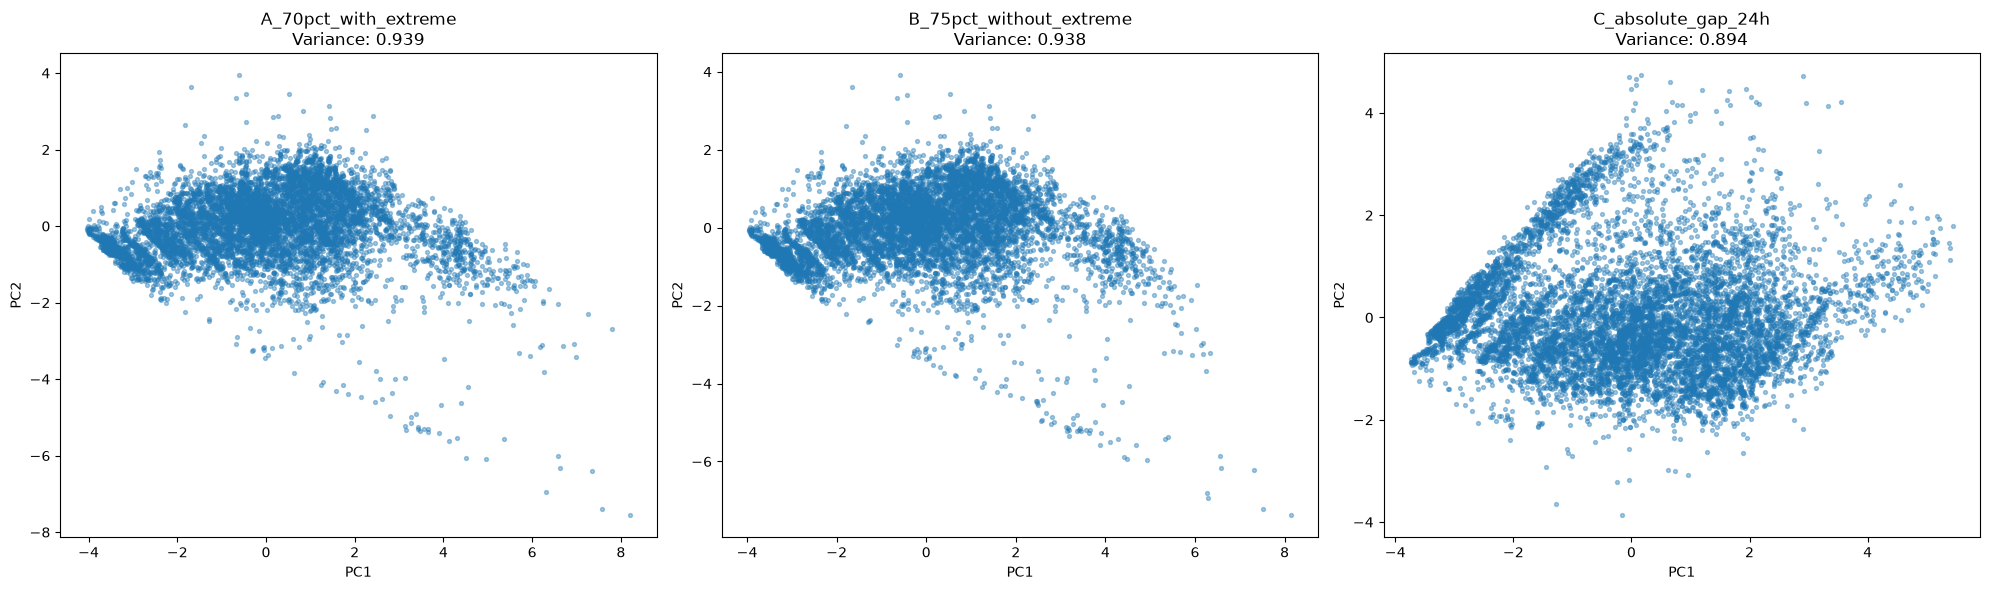

In [ ]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(20, 6)
)

for ax, (name, result) in zip(
    axes,
    pca_results.items()
):

    scores = result["scores"]

    ax.scatter(
        scores[:, 0],
        scores[:, 1],
        s=8,
        alpha=0.4
    )

    ax.set_title(
        f"{name}\n"
        f"Variance: "
        f"{result['cumulative_variance']:.3f}"
    )

    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

plt.tight_layout()

plt.savefig(
    PLOT_DIR / "linear_pca_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
loading_results = {}

for name, result in pca_results.items():

    loadings = pd.DataFrame(
        result["model"].components_.T,
        index=PCA_FEATURES,
        columns=["PC1", "PC2"]
    )

    loading_results[name] = loadings

    print(f"\n{name}")
    display(loadings)


A_70pct_with_extreme


,PC1,PC2
total_distance_km,0.479573,0.318771
recorded_track_hours,0.491412,-0.133112
elapsed_span_hours,0.489971,-0.230491
distance_based_avg_speed_kmh_clean,0.367425,0.695047
track_count,0.391729,-0.586898



B_75pct_without_extreme


,PC1,PC2
total_distance_km,0.478657,0.339204
recorded_track_hours,0.496789,-0.125443
elapsed_span_hours,0.491904,-0.244113
distance_based_avg_speed_kmh_clean,0.362591,0.682684
track_count,0.388133,-0.586137



C_absolute_gap_24h


,PC1,PC2
total_distance_km,0.505377,-0.343518
recorded_track_hours,0.524616,-0.033747
elapsed_span_hours,0.429162,0.453693
distance_based_avg_speed_kmh_clean,0.416930,-0.518352
track_count,0.333709,0.637440


In [ ]:
from sklearn.decomposition import KernelPCA
from sklearn.metrics import pairwise_distances

KERNEL_CONFIGS = {
    "rbf_g001": {
        "kernel": "rbf",
        "gamma": 0.01
    },
    "rbf_g005": {
        "kernel": "rbf",
        "gamma": 0.05
    },
    "rbf_g01": {
        "kernel": "rbf",
        "gamma": 0.1
    },
    "rbf_g05": {
        "kernel": "rbf",
        "gamma": 0.5
    },
    "rbf_g1": {
        "kernel": "rbf",
        "gamma": 1.0
    },
    "poly_d2": {
        "kernel": "poly",
        "gamma": 1.0 / len(PCA_FEATURES),
        "degree": 2,
        "coef0": 1
    },
    "poly_d3": {
        "kernel": "poly",
        "gamma": 1.0 / len(PCA_FEATURES),
        "degree": 3,
        "coef0": 1
    }
}

K_VALUES = [2, 3, 4, 5, 6]

print("Kernel configurations:", len(KERNEL_CONFIGS))
print("K values:", K_VALUES)

Kernel configurations: 7
K values: [2, 3, 4, 5, 6]


In [ ]:
import time
import gc

kernel_results = {}

total_runs = len(datasets) * len(KERNEL_CONFIGS)
completed_runs = 0

print("=" * 75)
print("STARTING KERNEL PCA EXPERIMENTS")
print("=" * 75)
print(f"Datasets          : {len(datasets)}")
print(f"Kernel configs    : {len(KERNEL_CONFIGS)}")
print(f"Total PCA runs    : {total_runs}")
print("=" * 75)

for dataset_idx, (dataset_name, X_scaled) in enumerate(
    prepared_datasets.items(), start=1
):

    print(f"\n{'#' * 75}")
    print(f"DATASET {dataset_idx}/{len(datasets)}: {dataset_name}")
    print(f"Input shape: {X_scaled.shape}")
    print(f"{'#' * 75}")

    kernel_results[dataset_name] = {}

    for kernel_idx, (config_name, config) in enumerate(
        KERNEL_CONFIGS.items(), start=1
    ):

        completed_runs += 1
        start_time = time.time()

        print(
            f"\n[{completed_runs}/{total_runs}] "
            f"Fitting {config_name}"
        )

        print(f"Kernel parameters: {config}")
        print("Status: Initializing Kernel PCA...")

        try:
            kpca = KernelPCA(
                n_components=2,
                kernel=config["kernel"],
                gamma=config.get("gamma"),
                degree=config.get("degree", 3),
                coef0=config.get("coef0", 1),
                eigen_solver="auto",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )

            print("Status: Fitting and transforming data...")

            scores = kpca.fit_transform(X_scaled)

            elapsed_time = time.time() - start_time

            kernel_results[dataset_name][config_name] = {
                "model": kpca,
                "scores": scores,
                "config": config,
                "fit_time_seconds": elapsed_time
            }

            print("Status: COMPLETED")
            print(f"Output shape      : {scores.shape}")
            print(f"Execution time    : {elapsed_time:.2f} seconds")
            print(f"NaN values        : {np.isnan(scores).sum()}")
            print(f"Infinite values   : {np.isinf(scores).sum()}")
            print(
                f"Component 1 range : "
                f"{scores[:, 0].min():.4f} to "
                f"{scores[:, 0].max():.4f}"
            )
            print(
                f"Component 2 range : "
                f"{scores[:, 1].min():.4f} to "
                f"{scores[:, 1].max():.4f}"
            )

        except Exception as e:

            elapsed_time = time.time() - start_time

            print("Status: FAILED")
            print(f"Error: {type(e).__name__}: {e}")
            print(f"Time before failure: {elapsed_time:.2f} seconds")

            kernel_results[dataset_name][config_name] = {
                "model": None,
                "scores": None,
                "config": config,
                "error": str(e),
                "fit_time_seconds": elapsed_time
            }

        finally:
            gc.collect()

        print("-" * 75)

    successful = sum(
        1 for result in kernel_results[dataset_name].values()
        if result["scores"] is not None
    )

    print(
        f"\nDataset completed: {dataset_name} | "
        f"{successful}/{len(KERNEL_CONFIGS)} successful"
    )

print("\n" + "=" * 75)
print("KERNEL PCA EXPERIMENTS FINISHED")
print("=" * 75)

for dataset_name, results in kernel_results.items():

    successful = sum(
        1 for result in results.values()
        if result["scores"] is not None
    )

    print(f"{dataset_name}: {successful}/{len(results)} successful")

STARTING KERNEL PCA EXPERIMENTS
Datasets          : 3
Kernel configs    : 7
Total PCA runs    : 21

###########################################################################
DATASET 1/3: A_70pct_with_extreme
Input shape: (7278, 5)
###########################################################################

[1/21] Fitting rbf_g001
Kernel parameters: {'kernel': 'rbf', 'gamma': 0.01}
Status: Initializing Kernel PCA...
Status: Fitting and transforming data...
Status: COMPLETED
Output shape      : (7278, 2)
Execution time    : 0.34 seconds
NaN values        : 0
Infinite values   : 0
Component 1 range : -0.4737 to 0.6285
Component 2 range : -0.3890 to 0.6702
---------------------------------------------------------------------------

[2/21] Fitting rbf_g005
Kernel parameters: {'kernel': 'rbf', 'gamma': 0.05}
Status: Initializing Kernel PCA...
Status: Fitting and transforming data...
Status: COMPLETED
Output shape      : (7278, 2)
Execution time    : 0.23 seconds
NaN values        : 0
Infin

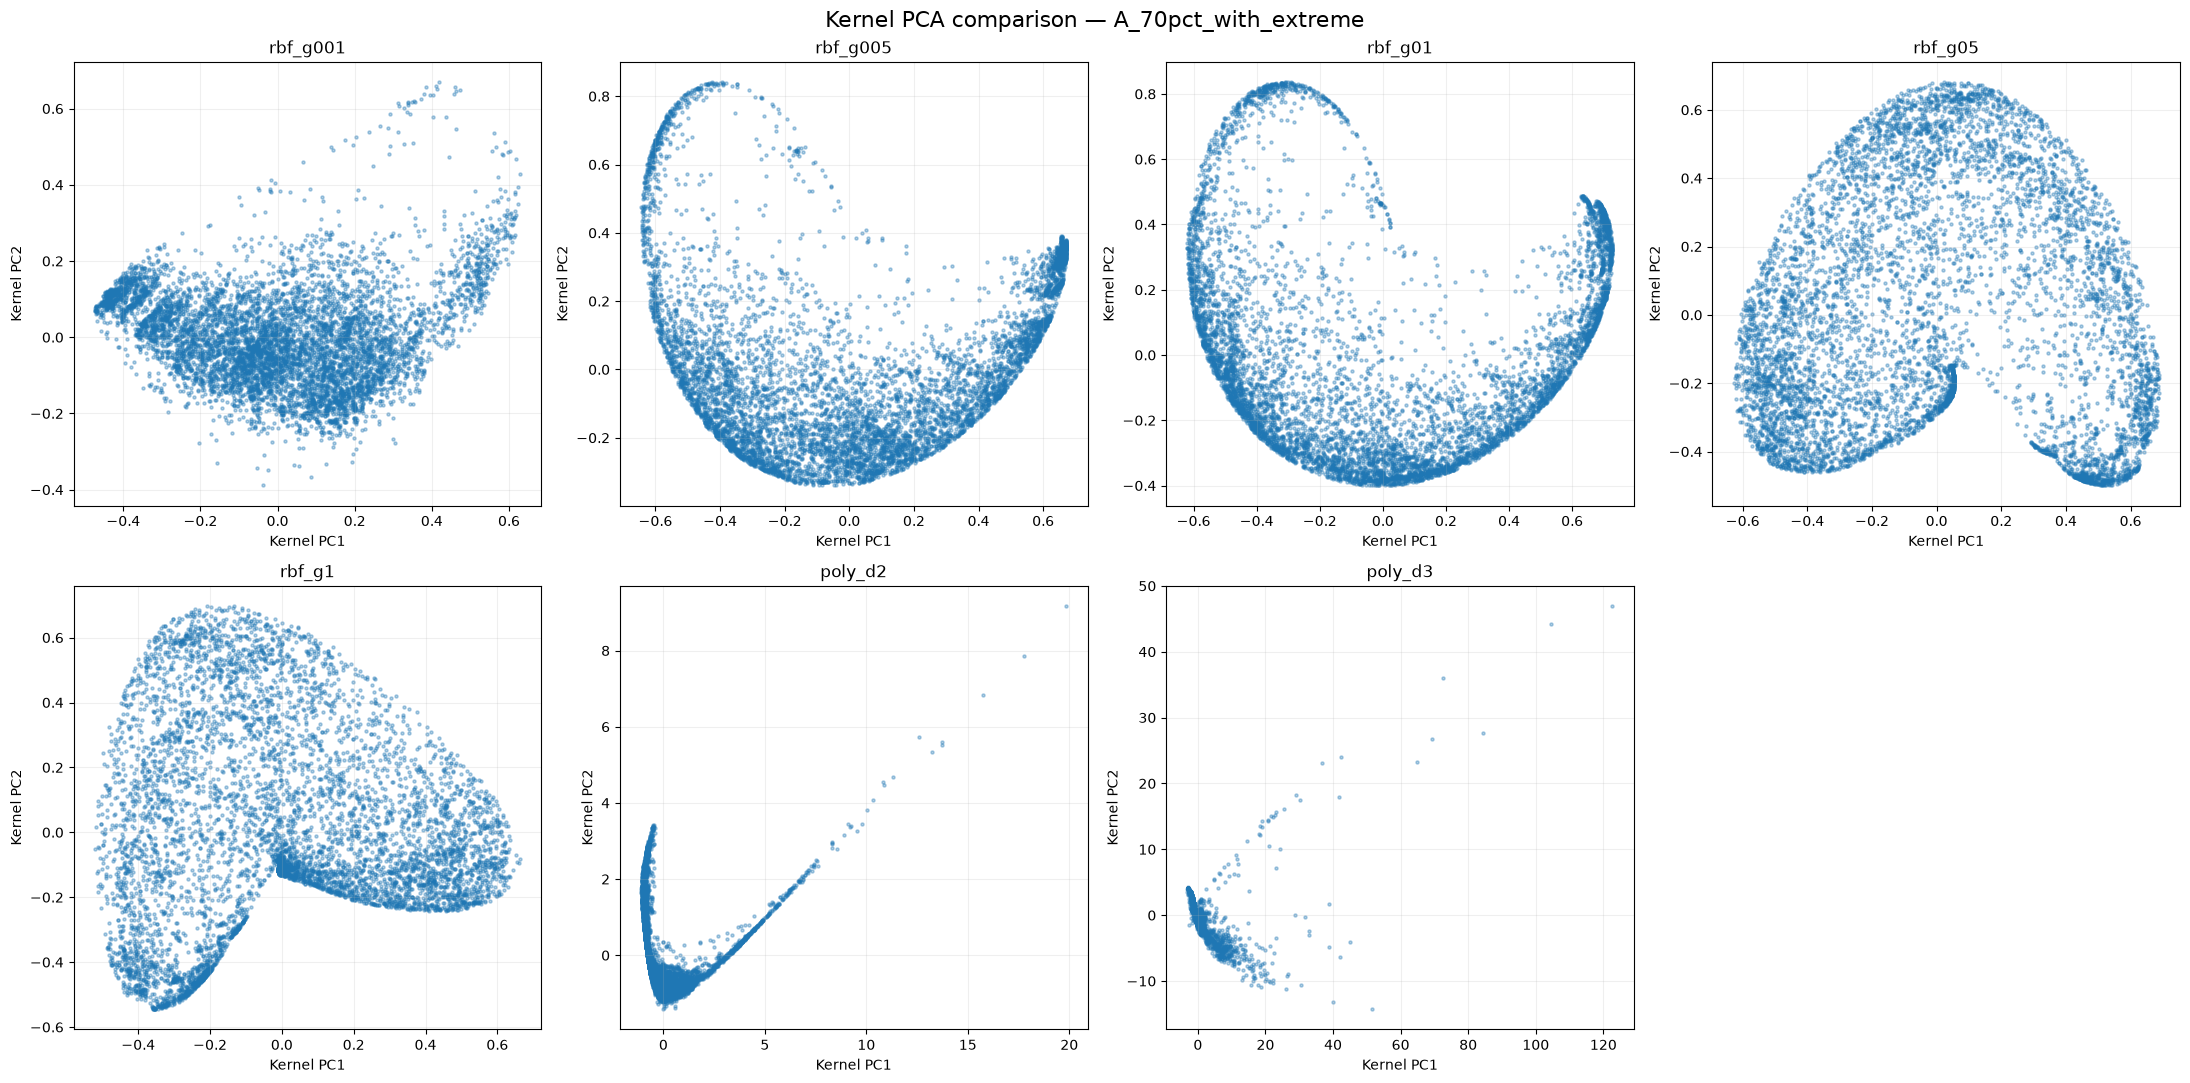

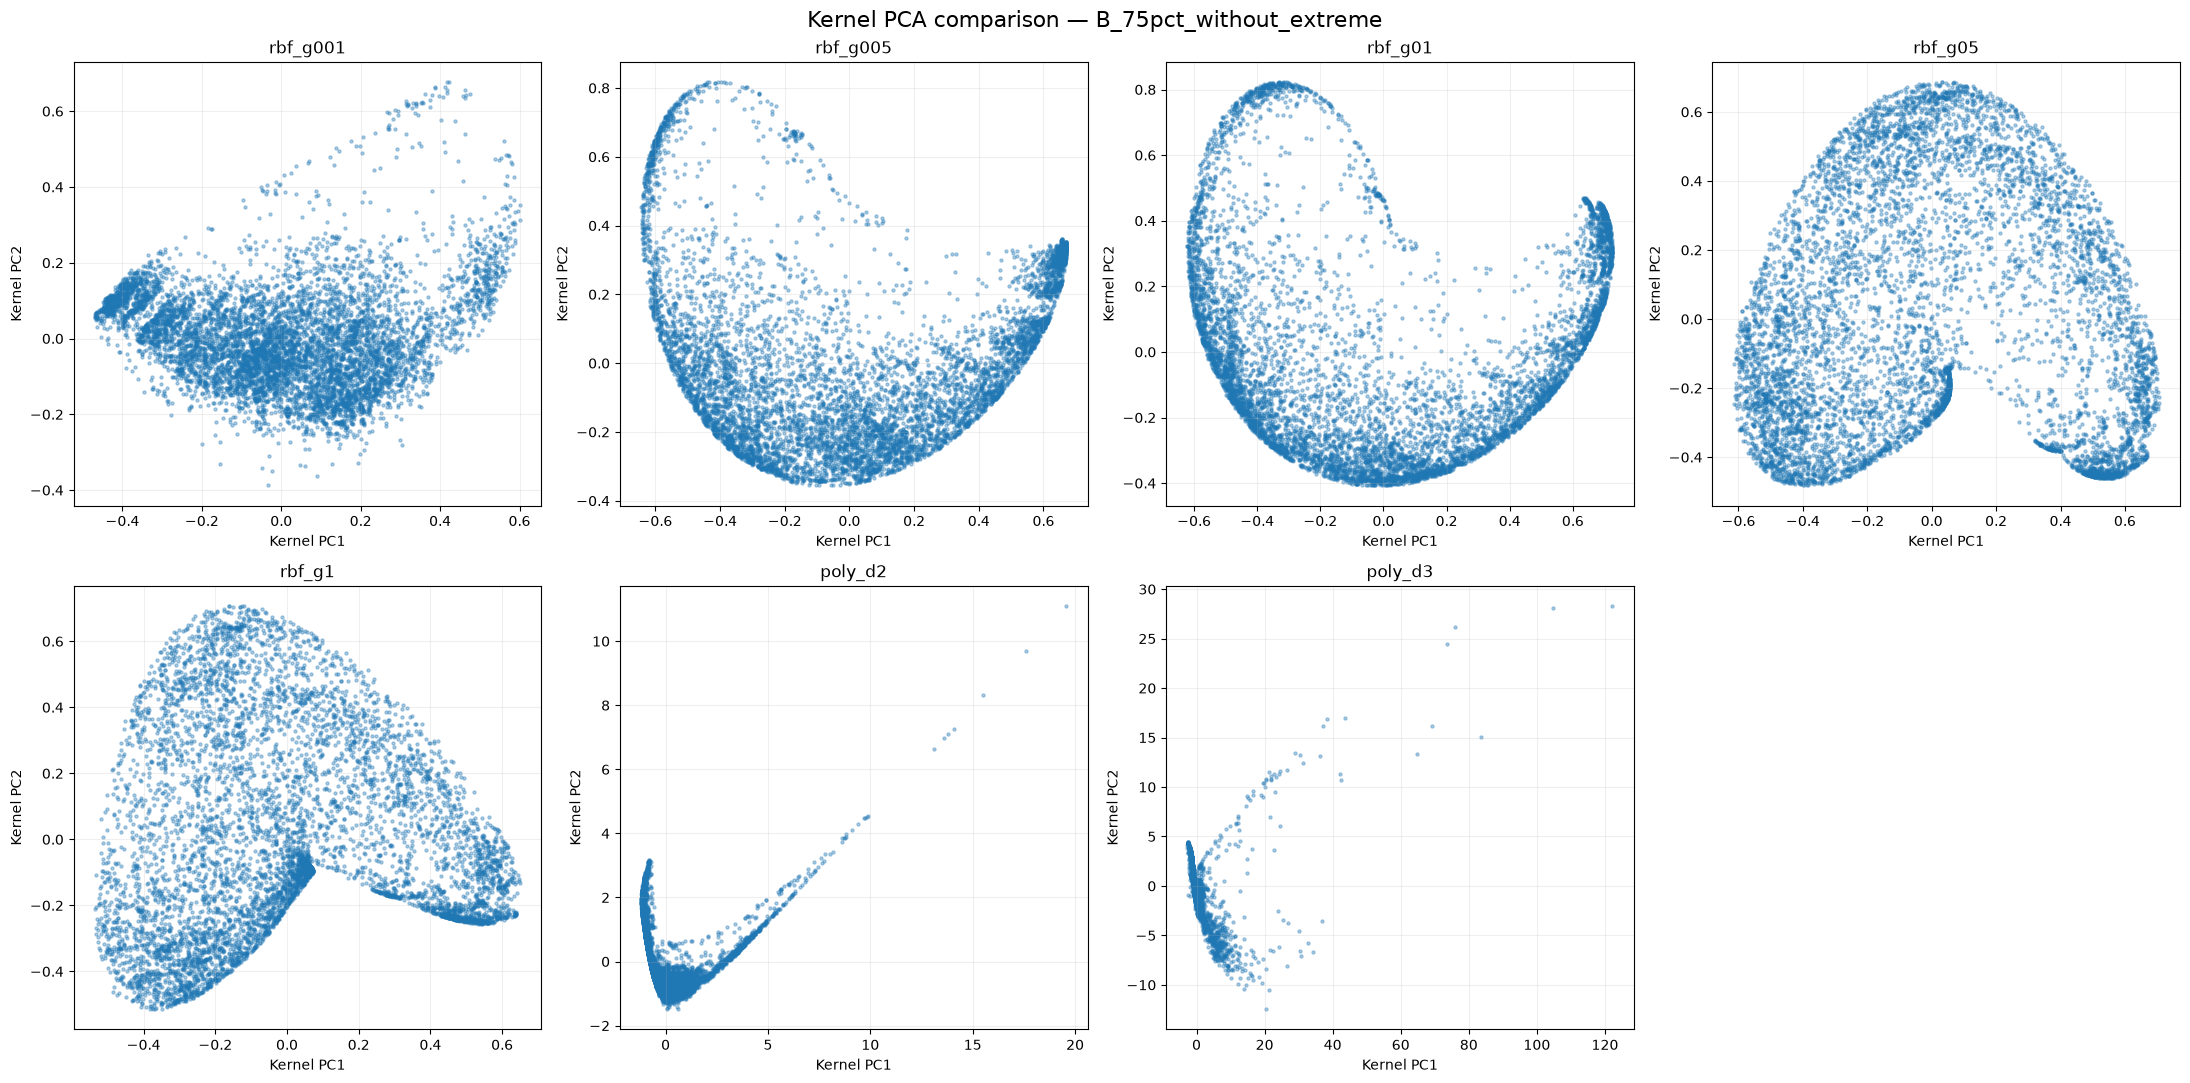

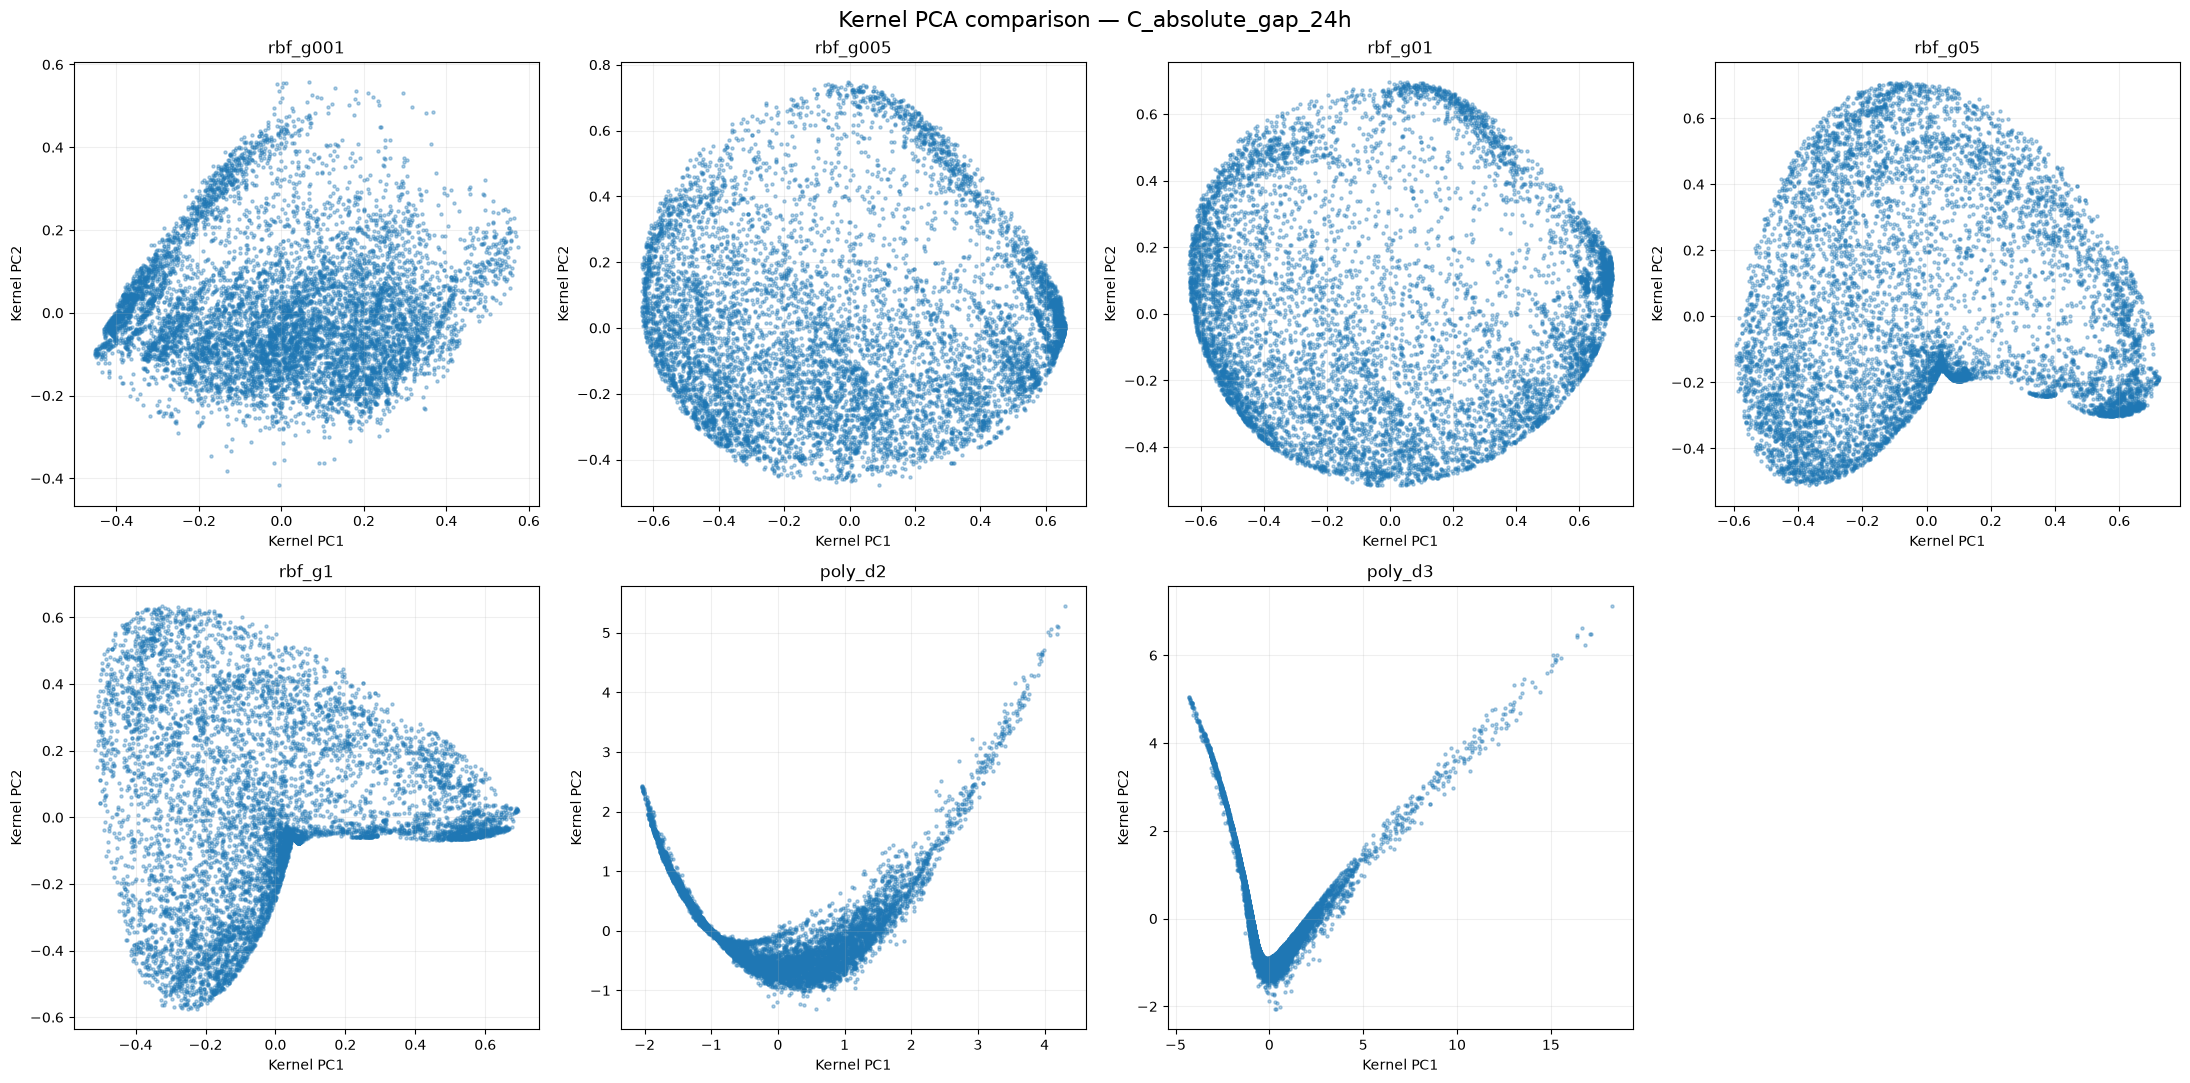

In [ ]:
for dataset_name, results in kernel_results.items():

    n = len(results)

    fig, axes = plt.subplots(
        2,
        4,
        figsize=(22, 11)
    )

    axes = axes.flatten()

    for ax, (config_name, result) in zip(
        axes,
        results.items()
    ):

        scores = result["scores"]

        ax.scatter(
            scores[:, 0],
            scores[:, 1],
            s=5,
            alpha=0.35
        )

        ax.set_title(config_name)
        ax.set_xlabel("Kernel PC1")
        ax.set_ylabel("Kernel PC2")
        ax.grid(alpha=0.2)

    for ax in axes[n:]:
        ax.set_visible(False)

    fig.suptitle(
        f"Kernel PCA comparison — {dataset_name}",
        fontsize=16
    )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR / f"{dataset_name}_kernel_pca.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
representation_results = {}

for dataset_name, X_scaled in prepared_datasets.items():

    representation_results[dataset_name] = {}

    # Standardized original feature space
    representation_results[dataset_name]["standardized_5d"] = (
        X_scaled.to_numpy()
    )

    # Linear PCA
    representation_results[dataset_name]["linear_pca_2d"] = (
        pca_results[dataset_name]["scores"]
    )

    # Successful Kernel PCA configurations only
    for config_name, result in kernel_results[
        dataset_name
    ].items():

        if result["scores"] is None:
            print(
                f"Skipping failed configuration: "
                f"{dataset_name} | {config_name}"
            )
            continue

        representation_results[dataset_name][config_name] = (
            result["scores"]
        )

print("\nAvailable representations:")

for dataset_name, representations in representation_results.items():
    print(f"\n{dataset_name}")

    for representation_name, X in representations.items():
        print(f"  {representation_name}: {X.shape}")


Available representations:

A_70pct_with_extreme
  standardized_5d: (7278, 5)
  linear_pca_2d: (7278, 2)
  rbf_g001: (7278, 2)
  rbf_g005: (7278, 2)
  rbf_g01: (7278, 2)
  rbf_g05: (7278, 2)
  rbf_g1: (7278, 2)
  poly_d2: (7278, 2)
  poly_d3: (7278, 2)

B_75pct_without_extreme
  standardized_5d: (7563, 5)
  linear_pca_2d: (7563, 2)
  rbf_g001: (7563, 2)
  rbf_g005: (7563, 2)
  rbf_g01: (7563, 2)
  rbf_g05: (7563, 2)
  rbf_g1: (7563, 2)
  poly_d2: (7563, 2)
  poly_d3: (7563, 2)

C_absolute_gap_24h
  standardized_5d: (8821, 5)
  linear_pca_2d: (8821, 2)
  rbf_g001: (8821, 2)
  rbf_g005: (8821, 2)
  rbf_g01: (8821, 2)
  rbf_g05: (8821, 2)
  rbf_g1: (8821, 2)
  poly_d2: (8821, 2)
  poly_d3: (8821, 2)


In [ ]:

def evaluate_kmeans(
    X,
    k_values=K_VALUES,
    random_state=RANDOM_STATE
):

    results = []
    assignments = {}

    for k in k_values:

        model = KMeans(
            n_clusters=k,
            init="k-means++",
            n_init=20,
            max_iter=300,
            random_state=random_state
        )

        labels = model.fit_predict(X)

        silhouette = silhouette_score(
            X,
            labels,
            sample_size=min(3000, len(X)),
            random_state=random_state
        )

        db_score = davies_bouldin_score(
            X,
            labels
        )

        ch_score = calinski_harabasz_score(
            X,
            labels
        )

        counts = pd.Series(labels).value_counts()

        results.append({
            "k": k,
            "silhouette": silhouette,
            "davies_bouldin": db_score,
            "calinski_harabasz": ch_score,
            "inertia": model.inertia_,
            "smallest_cluster": counts.min(),
            "largest_cluster": counts.max(),
            "smallest_cluster_pct": (
                counts.min() / len(labels) * 100
            )
        })

        assignments[k] = {
            "labels": labels,
            "model": model
        }

    return pd.DataFrame(results), assignments

In [ ]:
all_metrics = []
all_assignments = {}

for dataset_name, representations in (
    representation_results.items()
):

    for representation_name, X in representations.items():

        print(
            f"Evaluating: {dataset_name} | "
            f"{representation_name}"
        )

        metrics, assignments = evaluate_kmeans(X)

        metrics.insert(
            0, "representation", representation_name
        )

        metrics.insert(
            0, "dataset", dataset_name
        )

        all_metrics.append(metrics)

        all_assignments[
            (dataset_name, representation_name)
        ] = assignments

metrics_df = pd.concat(
    all_metrics,
    ignore_index=True
)

metrics_df.to_csv(
    OUTPUT_DIR / "pca_comparison_metrics.csv",
    index=False
)

display(
    metrics_df.sort_values(
        ["dataset", "silhouette"],
        ascending=[True, False]
    )
)

Evaluating: A_70pct_with_extreme | standardized_5d
Evaluating: A_70pct_with_extreme | linear_pca_2d
Evaluating: A_70pct_with_extreme | rbf_g001
Evaluating: A_70pct_with_extreme | rbf_g005
Evaluating: A_70pct_with_extreme | rbf_g01
Evaluating: A_70pct_with_extreme | rbf_g05
Evaluating: A_70pct_with_extreme | rbf_g1
Evaluating: A_70pct_with_extreme | poly_d2
Evaluating: A_70pct_with_extreme | poly_d3
Evaluating: B_75pct_without_extreme | standardized_5d
Evaluating: B_75pct_without_extreme | linear_pca_2d
Evaluating: B_75pct_without_extreme | rbf_g001
Evaluating: B_75pct_without_extreme | rbf_g005
Evaluating: B_75pct_without_extreme | rbf_g01
Evaluating: B_75pct_without_extreme | rbf_g05
Evaluating: B_75pct_without_extreme | rbf_g1
Evaluating: B_75pct_without_extreme | poly_d2
Evaluating: B_75pct_without_extreme | poly_d3
Evaluating: C_absolute_gap_24h | standardized_5d
Evaluating: C_absolute_gap_24h | linear_pca_2d
Evaluating: C_absolute_gap_24h | rbf_g001
Evaluating: C_absolute_gap_24h 

,dataset,representation,k,silhouette,davies_bouldin,calinski_harabasz,inertia,smallest_cluster,largest_cluster,smallest_cluster_pct
40,A_70pct_with_extreme,poly_d3,2,0.867483,0.696272,5364.169615,91335.398407,315,6963,4.328112
41,A_70pct_with_extreme,poly_d3,3,0.856630,0.522799,7892.585936,50057.705902,7,6905,0.096180
42,A_70pct_with_extreme,poly_d3,4,0.842171,0.642235,8905.379732,33956.247655,6,6868,0.082440
43,A_70pct_with_extreme,poly_d3,5,0.814968,0.556429,8835.538913,27080.011679,6,6812,0.082440
35,A_70pct_with_extreme,poly_d2,2,0.699303,0.555841,5616.947698,12866.617663,464,6814,6.375378
...,...,...,...,...,...,...,...,...,...,...
91,C_absolute_gap_24h,standardized_5d,3,0.382149,0.954721,5674.223000,19285.399888,1059,4258,12.005442
90,C_absolute_gap_24h,standardized_5d,2,0.378691,1.036524,6851.125379,24821.892408,4181,4640,47.398254
92,C_absolute_gap_24h,standardized_5d,4,0.339646,0.995575,6002.799554,14496.479012,967,3328,10.962476
94,C_absolute_gap_24h,standardized_5d,6,0.322901,1.009548,5431.157117,10808.387696,637,2463,7.221403


In [ ]:
# Minimum cluster-size filters
MIN_CLUSTER_PCT = 5.0

viable_models = metrics_df[
    metrics_df["smallest_cluster_pct"] >= MIN_CLUSTER_PCT
].copy()

viable_models = viable_models.sort_values(
    ["dataset", "silhouette"],
    ascending=[True, False]
)

print("=" * 90)
print("VIABLE CLUSTERING CONFIGURATIONS")
print("=" * 90)

for dataset_name in viable_models["dataset"].unique():

    print(f"\n{dataset_name}")

    display(
        viable_models[
            viable_models["dataset"] == dataset_name
        ][
            [
                "representation",
                "k",
                "silhouette",
                "davies_bouldin",
                "calinski_harabasz",
                "smallest_cluster_pct",
                "largest_cluster"
            ]
        ].head(15)
    )

VIABLE CLUSTERING CONFIGURATIONS

A_70pct_with_extreme


,representation,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster
35,poly_d2,2,0.699303,0.555841,5616.947698,6.375378,6814
36,poly_d2,3,0.576741,0.559727,9208.957116,6.018137,5028
26,rbf_g05,3,0.509984,0.687303,9689.406111,23.316845,3248
22,rbf_g01,4,0.507064,0.637526,13013.766831,11.967574,2376
17,rbf_g005,4,0.494794,0.650055,13182.407679,9.906568,2412
37,poly_d2,4,0.492113,0.616506,9396.388954,5.454795,3061
21,rbf_g01,3,0.489849,0.729327,10326.225546,27.589997,3127
34,rbf_g1,6,0.482801,0.702527,10258.327033,10.043968,1726
23,rbf_g01,5,0.480605,0.645577,14199.977872,10.524869,1977
33,rbf_g1,5,0.477701,0.724406,9898.209008,12.187414,1939



B_75pct_without_extreme


,representation,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster
80,poly_d2,2,0.690018,0.568160,5474.630246,6.584689,7065
81,poly_d2,3,0.582802,0.564459,9238.747688,6.240910,5087
71,rbf_g05,3,0.513830,0.684263,10267.625647,23.456300,3373
67,rbf_g01,4,0.507060,0.650467,13533.660594,13.103266,2416
66,rbf_g01,3,0.496966,0.727882,10924.266227,28.176649,3209
76,rbf_g1,3,0.496539,0.726367,8864.338383,24.791749,3616
79,rbf_g1,6,0.495899,0.699329,11083.654194,10.273701,1795
78,rbf_g1,5,0.492718,0.715021,10704.654353,12.349597,2024
62,rbf_g005,4,0.489146,0.668570,13392.467971,11.106704,2430
68,rbf_g01,5,0.488811,0.644804,14713.203038,11.662039,2070



C_absolute_gap_24h


,representation,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster
124,rbf_g1,6,0.527282,0.683567,13084.196332,8.978574,2830
123,rbf_g1,5,0.520284,0.687932,12773.477311,10.849110,3055
126,poly_d2,3,0.509622,0.670161,10214.325965,11.903412,5100
121,rbf_g1,3,0.503753,0.738499,9705.368301,22.571137,4668
122,rbf_g1,4,0.500868,0.639154,12024.360172,19.736991,3221
119,rbf_g05,6,0.495725,0.678734,13547.600272,11.438612,1961
116,rbf_g05,3,0.494251,0.723688,10745.820252,24.112912,4233
118,rbf_g05,5,0.486211,0.724338,12571.144129,12.447568,2204
110,rbf_g01,2,0.472179,0.880711,9498.129511,43.566489,4978
125,poly_d2,2,0.470924,0.834654,7159.605229,41.231153,5184


In [ ]:
CORRELATION_FEATURES = [
    "total_distance_km",
    "recorded_track_hours",
    "elapsed_span_hours",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
]

correlation_results = {}

for dataset_name, df in datasets.items():

    print("\n" + "=" * 75)
    print(f"CORRELATION ANALYSIS: {dataset_name}")
    print("=" * 75)

    X = df[CORRELATION_FEATURES].copy()

    # Pearson correlation
    pearson_corr = X.corr(method="pearson")

    # Spearman correlation
    spearman_corr = X.corr(method="spearman")

    correlation_results[dataset_name] = {
        "pearson": pearson_corr,
        "spearman": spearman_corr
    }

    print("\nPEARSON CORRELATION")
    display(pearson_corr.round(3))

    print("\nSPEARMAN CORRELATION")
    display(spearman_corr.round(3))


CORRELATION ANALYSIS: A_70pct_with_extreme

PEARSON CORRELATION


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
total_distance_km,1.000,0.695,0.645,0.568,0.304
recorded_track_hours,0.695,1.000,0.970,0.266,0.833
elapsed_span_hours,0.645,0.970,1.000,0.186,0.868
distance_based_avg_speed_kmh_clean,0.568,0.266,0.186,1.000,0.017
track_count,0.304,0.833,0.868,0.017,1.000



SPEARMAN CORRELATION


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
total_distance_km,1.000,0.909,0.874,0.855,0.558
recorded_track_hours,0.909,1.000,0.961,0.603,0.649
elapsed_span_hours,0.874,0.961,1.000,0.580,0.732
distance_based_avg_speed_kmh_clean,0.855,0.603,0.580,1.000,0.309
track_count,0.558,0.649,0.732,0.309,1.000



CORRELATION ANALYSIS: B_75pct_without_extreme

PEARSON CORRELATION


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
total_distance_km,1.000,0.631,0.559,0.615,0.232
recorded_track_hours,0.631,1.000,0.959,0.242,0.826
elapsed_span_hours,0.559,0.959,1.000,0.146,0.873
distance_based_avg_speed_kmh_clean,0.615,0.242,0.146,1.000,-0.023
track_count,0.232,0.826,0.873,-0.023,1.000


... (2 outputs left out)


CORRELATION ANALYSIS: C_absolute_gap_24h

PEARSON CORRELATION


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
total_distance_km,1.000,0.908,0.589,0.696,0.326
recorded_track_hours,0.908,1.000,0.673,0.532,0.456
elapsed_span_hours,0.589,0.673,1.000,0.177,0.655
distance_based_avg_speed_kmh_clean,0.696,0.532,0.177,1.000,0.021
track_count,0.326,0.456,0.655,0.021,1.000



SPEARMAN CORRELATION


,total_distance_km,recorded_track_hours,elapsed_span_hours,distance_based_avg_speed_kmh_clean,track_count
total_distance_km,1.000,0.907,0.518,0.889,0.332
recorded_track_hours,0.907,1.000,0.668,0.647,0.479
elapsed_span_hours,0.518,0.668,1.000,0.279,0.694
distance_based_avg_speed_kmh_clean,0.889,0.647,0.279,1.000,0.112
track_count,0.332,0.479,0.694,0.112,1.000


In [ ]:
FEATURE_CONFIGS = {
    "original_5d": [
        "total_distance_km",
        "recorded_track_hours",
        "elapsed_span_hours",
        "distance_based_avg_speed_kmh_clean",
        "track_count"
    ],

    "distance_speed_tracks": [
        "total_distance_km",
        "distance_based_avg_speed_kmh_clean",
        "track_count"
    ],

    "distance_duration_tracks": [
        "total_distance_km",
        "recorded_track_hours",
        "track_count"
    ],

    "speed_tracks": [
        "distance_based_avg_speed_kmh_clean",
        "track_count"
    ]
}

REGRESSION_SAFE_CONFIGS = [
    "distance_speed_tracks",
    "distance_duration_tracks",
    "speed_tracks"
]

In [ ]:
def prepare_feature_representation(df, features):

    X = df[features].copy()

    X = X.apply(pd.to_numeric, errors="coerce")

    X = X.replace([np.inf, -np.inf], np.nan)

    log_features = [
        col for col in [
            "total_distance_km",
            "recorded_track_hours",
            "elapsed_span_hours",
            "track_count"
        ]
        if col in features
    ]

    for col in log_features:

        if (X[col].dropna() < 0).any():
            raise ValueError(
                f"Negative values found in {col}"
            )

        X[col] = np.log1p(X[col])

    imputer = SimpleImputer(strategy="median")

    X_imputed = imputer.fit_transform(X)

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(X_imputed)

    return X_scaled, imputer, scaler

In [ ]:
feature_representation_results = {}

for dataset_name, df in datasets.items():

    feature_representation_results[dataset_name] = {}

    for config_name, features in FEATURE_CONFIGS.items():

        X_scaled, imputer, scaler = (
            prepare_feature_representation(
                df,
                features
            )
        )

        feature_representation_results[
            dataset_name
        ][config_name] = {
            "X": X_scaled,
            "features": features,
            "imputer": imputer,
            "scaler": scaler
        }

        print(
            f"{dataset_name} | {config_name} | "
            f"Shape: {X_scaled.shape}"
        )

A_70pct_with_extreme | original_5d | Shape: (7278, 5)
A_70pct_with_extreme | distance_speed_tracks | Shape: (7278, 3)
A_70pct_with_extreme | distance_duration_tracks | Shape: (7278, 3)
A_70pct_with_extreme | speed_tracks | Shape: (7278, 2)
B_75pct_without_extreme | original_5d | Shape: (7563, 5)
B_75pct_without_extreme | distance_speed_tracks | Shape: (7563, 3)
B_75pct_without_extreme | distance_duration_tracks | Shape: (7563, 3)
B_75pct_without_extreme | speed_tracks | Shape: (7563, 2)
C_absolute_gap_24h | original_5d | Shape: (8821, 5)
C_absolute_gap_24h | distance_speed_tracks | Shape: (8821, 3)
C_absolute_gap_24h | distance_duration_tracks | Shape: (8821, 3)
C_absolute_gap_24h | speed_tracks | Shape: (8821, 2)


In [ ]:
feature_pca_results = {}

for dataset_name, representations in (
    feature_representation_results.items()
):

    feature_pca_results[dataset_name] = {}

    for config_name, result in representations.items():

        X = result["X"]

        pca = PCA(
            n_components=2,
            random_state=RANDOM_STATE
        )

        scores = pca.fit_transform(X)

        feature_pca_results[
            dataset_name
        ][config_name] = {
            "model": pca,
            "scores": scores,
            "explained_variance": (
                pca.explained_variance_ratio_
            )
        }

        print(
            f"\n{dataset_name} | {config_name}"
        )

        print(
            "Explained variance:",
            pca.explained_variance_ratio_.round(4)
        )

        print(
            "Cumulative variance:",
            round(
                pca.explained_variance_ratio_.sum(),
                4
            )
        )


A_70pct_with_extreme | original_5d
Explained variance: [0.7602 0.1787]
Cumulative variance: 0.9389

A_70pct_with_extreme | distance_speed_tracks
Explained variance: [0.706  0.2587]
Cumulative variance: 0.9646

A_70pct_with_extreme | distance_duration_tracks
Explained variance: [0.8082 0.1604]
Cumulative variance: 0.9686

A_70pct_with_extreme | speed_tracks
Explained variance: [0.6253 0.3747]
Cumulative variance: 1.0

B_75pct_without_extreme | original_5d
Explained variance: [0.7438 0.1944]
Cumulative variance: 0.9382

B_75pct_without_extreme | distance_speed_tracks
Explained variance: [0.6883 0.2759]
Cumulative variance: 0.9642

B_75pct_without_extreme | distance_duration_tracks
Explained variance: [0.7927 0.1755]
Cumulative variance: 0.9682

B_75pct_without_extreme | speed_tracks
Explained variance: [0.6007 0.3993]
Cumulative variance: 1.0

C_absolute_gap_24h | original_5d
Explained variance: [0.6427 0.2509]
Cumulative variance: 0.8935

C_absolute_gap_24h | distance_speed_tracks
Expl

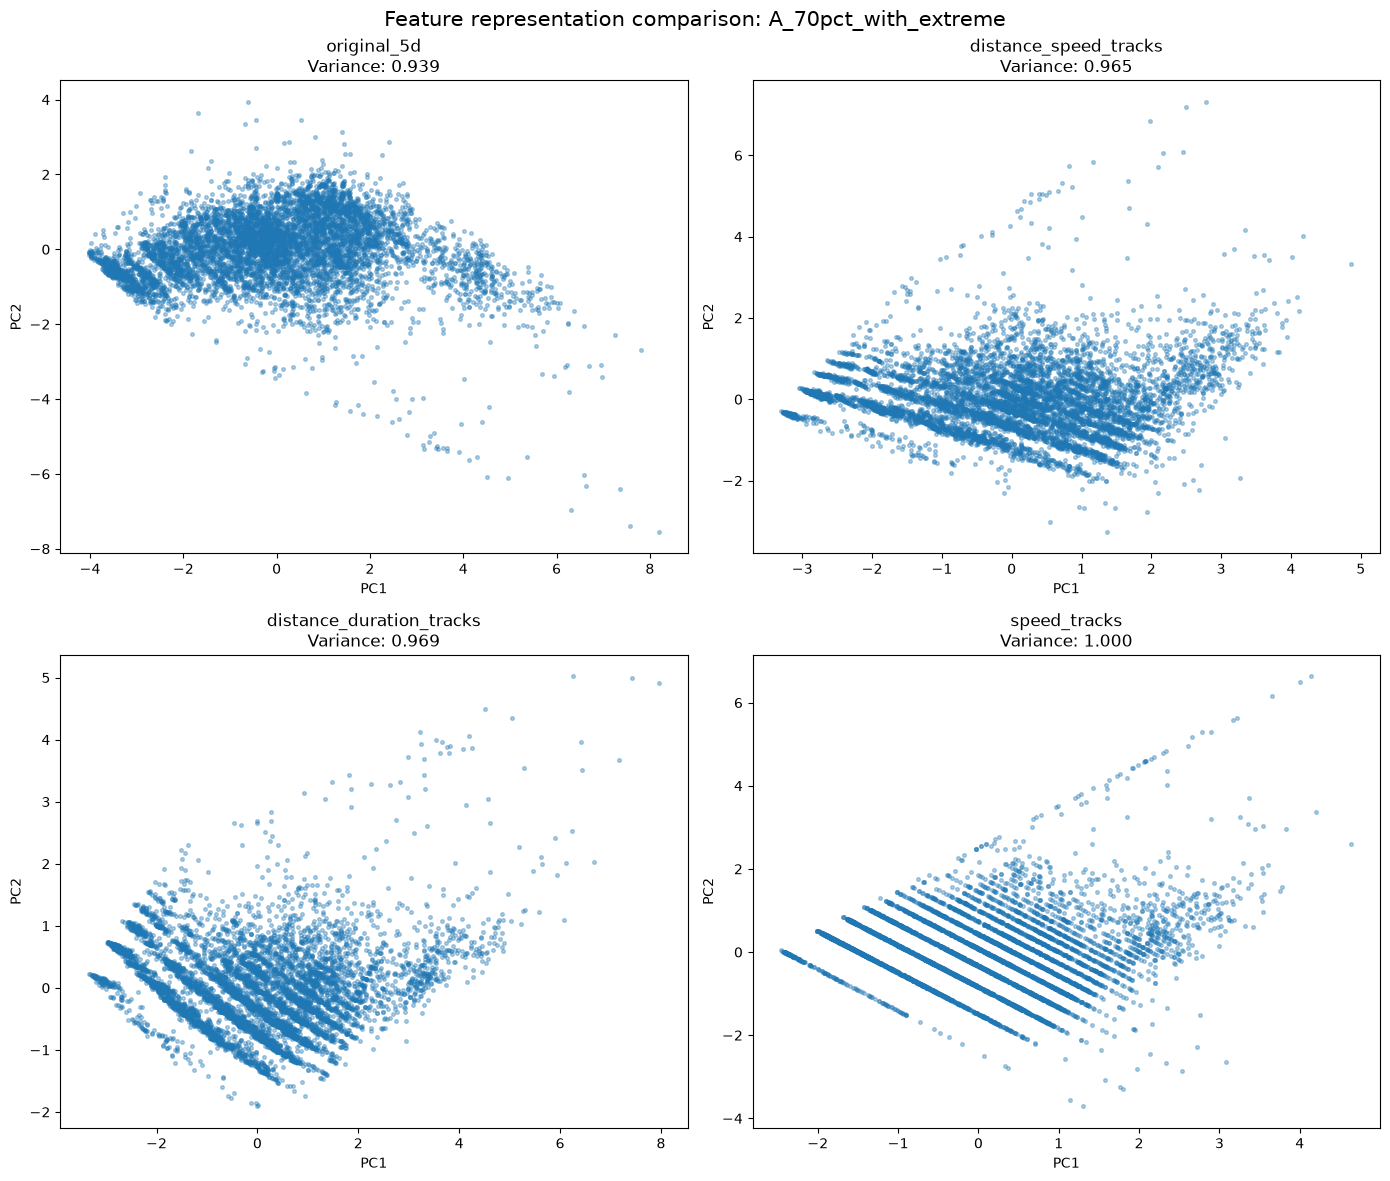

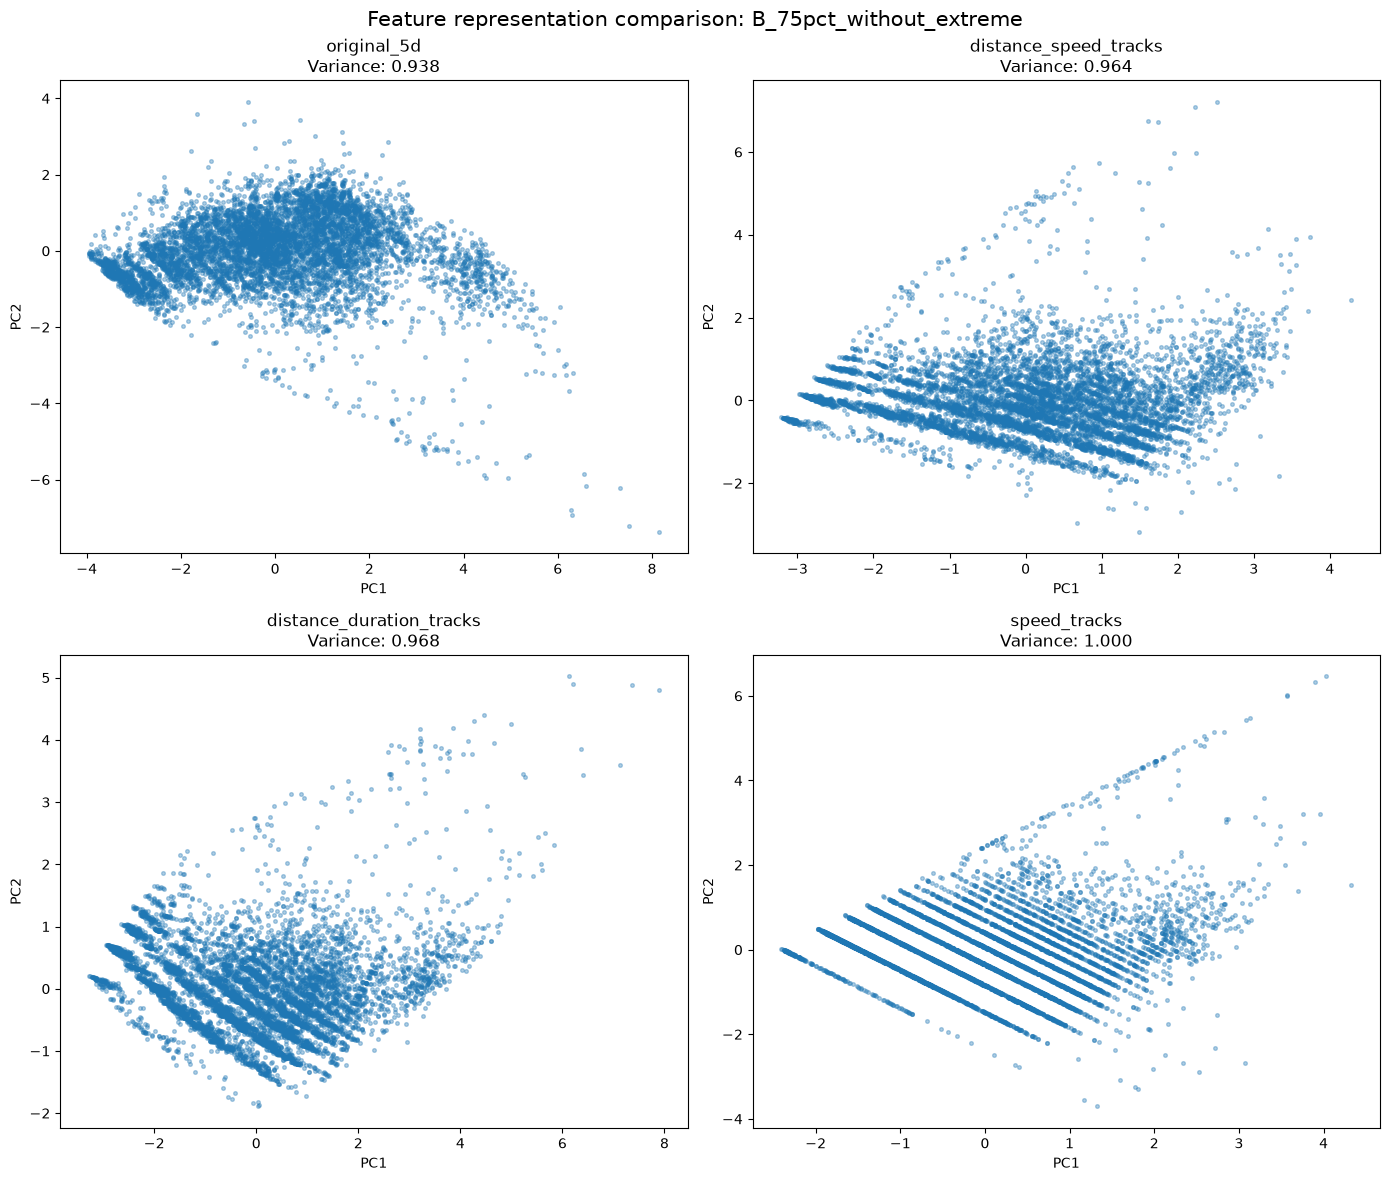

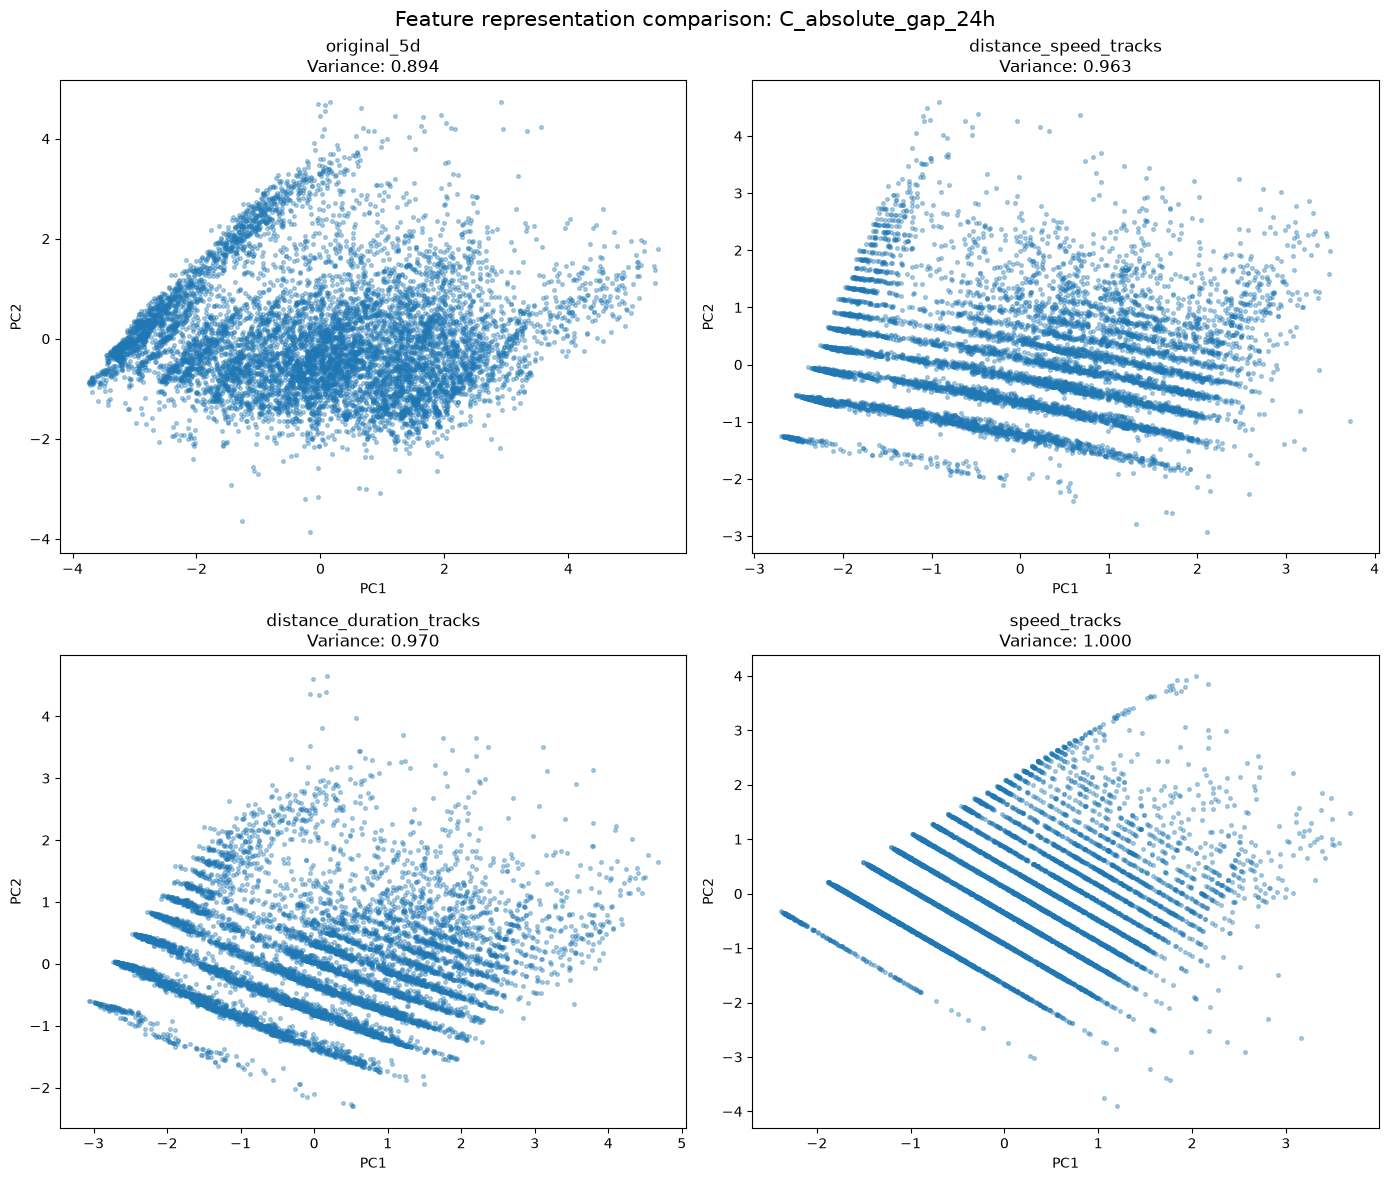

In [ ]:
for dataset_name, representations in (
    feature_pca_results.items()
):

    fig, axes = plt.subplots(
        2, 2,
        figsize=(14, 12)
    )

    axes = axes.flatten()

    for ax, (config_name, result) in zip(
        axes,
        representations.items()
    ):

        scores = result["scores"]

        ax.scatter(
            scores[:, 0],
            scores[:, 1],
            s=7,
            alpha=0.35
        )

        variance = result["explained_variance"].sum()

        ax.set_title(
            f"{config_name}\n"
            f"Variance: {variance:.3f}"
        )

        ax.set_xlabel("PC1")
        ax.set_ylabel("PC2")

    fig.suptitle(
        f"Feature representation comparison: {dataset_name}",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import pandas as pd
import numpy as np
import time

clustering_comparison = []

for dataset_name, representations in feature_representation_results.items():

    for config_name in REGRESSION_SAFE_CONFIGS:

        X = representations[config_name]["X"]

        for k in range(2, 7):

            start_time = time.time()

            model = KMeans(
                n_clusters=k,
                n_init=20,
                max_iter=300,
                random_state=42
            )

            labels = model.fit_predict(X)

            elapsed = time.time() - start_time

            counts = np.bincount(labels)

            silhouette = silhouette_score(
                X,
                labels,
                sample_size=min(3000, len(X)),
                random_state=42
            )

            clustering_comparison.append({
                "dataset": dataset_name,
                "representation": config_name,
                "k": k,
                "silhouette": silhouette,
                "davies_bouldin": davies_bouldin_score(X, labels),
                "calinski_harabasz": calinski_harabasz_score(X, labels),
                "inertia": model.inertia_,
                "smallest_cluster_pct": counts.min() / len(labels) * 100,
                "largest_cluster_pct": counts.max() / len(labels) * 100,
                "runtime_sec": elapsed
            })

clustering_comparison_df = pd.DataFrame(clustering_comparison)

clustering_comparison_df = clustering_comparison_df.sort_values(
    ["dataset", "silhouette"],
    ascending=[True, False]
)

display(clustering_comparison_df.round(4))

,dataset,representation,k,silhouette,davies_bouldin,calinski_harabasz,inertia,smallest_cluster_pct,largest_cluster_pct,runtime_sec
5,A_70pct_with_extreme,distance_duration_tracks,2,0.4178,0.8710,7131.9848,11026.1532,48.9008,51.0992,0.0494
6,A_70pct_with_extreme,distance_duration_tracks,3,0.4020,0.8343,7404.6863,7192.5527,15.7323,55.6334,0.0710
0,A_70pct_with_extreme,distance_speed_tracks,2,0.3967,0.9213,6272.1548,11725.9121,40.5881,59.4119,0.0517
11,A_70pct_with_extreme,speed_tracks,3,0.3894,0.9462,5439.7889,5832.9806,17.8483,41.4262,0.0569
14,A_70pct_with_extreme,speed_tracks,6,0.3864,0.7846,5414.9984,3081.8223,0.7694,24.3199,0.0892
13,A_70pct_with_extreme,speed_tracks,5,0.3830,0.8479,5401.2553,3665.9880,7.7356,24.7733,0.0694
12,A_70pct_with_extreme,speed_tracks,4,0.3775,0.9008,5237.9847,4605.9100,9.3982,32.4128,0.0743
10,A_70pct_with_extreme,speed_tracks,2,0.3775,1.0197,5049.5773,8592.6675,49.0382,50.9618,0.0430
7,A_70pct_with_extreme,distance_duration_tracks,4,0.3681,0.8975,7441.2823,5365.9615,7.3784,37.1256,0.0758
3,A_70pct_with_extreme,distance_speed_tracks,5,0.3674,0.9009,5666.0377,5304.4193,7.8730,28.3457,0.0758


In [ ]:
KERNEL_CONFIGS = [
    # RBF: wider gamma exploration
    {"name": "rbf_0001", "kernel": "rbf", "gamma": 0.001},
    {"name": "rbf_0005", "kernel": "rbf", "gamma": 0.005},
    {"name": "rbf_001",  "kernel": "rbf", "gamma": 0.01},
    {"name": "rbf_005",  "kernel": "rbf", "gamma": 0.05},
    {"name": "rbf_01",   "kernel": "rbf", "gamma": 0.1},
    {"name": "rbf_05",   "kernel": "rbf", "gamma": 0.5},
    {"name": "rbf_1",    "kernel": "rbf", "gamma": 1.0},

    # Laplacian
    {"name": "laplacian_0005", "kernel": "laplacian", "gamma": 0.005},
    {"name": "laplacian_001",  "kernel": "laplacian", "gamma": 0.01},
    {"name": "laplacian_005",  "kernel": "laplacian", "gamma": 0.05},
    {"name": "laplacian_01",   "kernel": "laplacian", "gamma": 0.1},
    {"name": "laplacian_05",   "kernel": "laplacian", "gamma": 0.5},

    # Cosine
    {"name": "cosine", "kernel": "cosine"},

    # Polynomial
    {"name": "poly_d2", "kernel": "poly", "gamma": 0.1, "degree": 2, "coef0": 1},
    {"name": "poly_d3", "kernel": "poly", "gamma": 0.1, "degree": 3, "coef0": 1},
    {"name": "poly_d4", "kernel": "poly", "gamma": 0.1, "degree": 4, "coef0": 1},
    {"name": "poly_d2_g05", "kernel": "poly", "gamma": 0.5, "degree": 2, "coef0": 1},

    # Sigmoid
    {"name": "sigmoid_001", "kernel": "sigmoid", "gamma": 0.01, "coef0": 0},
    {"name": "sigmoid_005", "kernel": "sigmoid", "gamma": 0.05, "coef0": 0},
    {"name": "sigmoid_01", "kernel": "sigmoid", "gamma": 0.1, "coef0": 0},
]

print("Total kernel configurations:", len(KERNEL_CONFIGS))

Total kernel configurations: 20


In [ ]:
from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
import numpy as np
import pandas as pd
import time

dataset_name = "A_70pct_with_extreme"
representation_name = "distance_speed_tracks"

X = feature_representation_results[
    dataset_name
][representation_name]["X"]

kernel_results = []
kernel_embeddings = {}

for config in KERNEL_CONFIGS:

    print(f"\nRunning: {config['name']}")
    start = time.time()

    try:
        kpca = KernelPCA(
            n_components=5,
            kernel=config["kernel"],
            gamma=config.get("gamma", None),
            degree=config.get("degree", 3),
            coef0=config.get("coef0", 1),
            eigen_solver="arpack",
            random_state=42,
            n_jobs=-1
        )

        X_kernel = kpca.fit_transform(X)

        kernel_embeddings[config["name"]] = X_kernel

        for k in range(2, 7):

            km = KMeans(
                n_clusters=k,
                n_init=20,
                max_iter=300,
                random_state=42
            )

            labels = km.fit_predict(X_kernel)
            counts = np.bincount(labels)

            kernel_results.append({
                "kernel": config["name"],
                "k": k,
                "silhouette": silhouette_score(
                    X_kernel,
                    labels,
                    sample_size=min(3000, len(X_kernel)),
                    random_state=42
                ),
                "davies_bouldin": davies_bouldin_score(
                    X_kernel, labels
                ),
                "calinski_harabasz": calinski_harabasz_score(
                    X_kernel, labels
                ),
                "smallest_cluster_pct": (
                    counts.min() / len(labels) * 100
                ),
                "largest_cluster_pct": (
                    counts.max() / len(labels) * 100
                )
            })

        print(
            f"Completed {config['name']} "
            f"in {time.time() - start:.1f}s"
        )

    except Exception as e:
        print(f"FAILED: {config['name']} -> {e}")

kernel_results_df = pd.DataFrame(kernel_results)

print("\nExperiment completed.")
display(kernel_results_df.head())


Running: rbf_0001
Completed rbf_0001 in 0.9s

Running: rbf_0005
Completed rbf_0005 in 0.9s

Running: rbf_001
Completed rbf_001 in 0.8s

Running: rbf_005
Completed rbf_005 in 0.8s

Running: rbf_01
Completed rbf_01 in 0.9s

Running: rbf_05
Completed rbf_05 in 0.9s

Running: rbf_1
Completed rbf_1 in 1.0s

Running: laplacian_0005
FAILED: laplacian_0005 -> The 'kernel' parameter of KernelPCA must be a str among {'poly', 'linear', 'rbf', 'cosine', 'sigmoid', 'precomputed'} or a callable. Got 'laplacian' instead.

Running: laplacian_001
FAILED: laplacian_001 -> The 'kernel' parameter of KernelPCA must be a str among {'poly', 'linear', 'rbf', 'cosine', 'sigmoid', 'precomputed'} or a callable. Got 'laplacian' instead.

Running: laplacian_005
FAILED: laplacian_005 -> The 'kernel' parameter of KernelPCA must be a str among {'poly', 'linear', 'rbf', 'cosine', 'sigmoid', 'precomputed'} or a callable. Got 'laplacian' instead.

Running: laplacian_01
FAILED: laplacian_01 -> The 'kernel' parameter of 

,kernel,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
0,rbf_0001,2,0.396240,0.923898,6251.131023,40.588074,59.411926
1,rbf_0001,3,0.363364,1.032509,5541.105921,17.339929,49.519099
2,rbf_0001,4,0.350443,0.944739,5654.152716,12.517175,38.788129
3,rbf_0001,5,0.367408,0.901052,5651.383793,7.886782,28.263259
4,rbf_0001,6,0.369683,0.858231,5351.036537,0.865622,26.875515


In [ ]:
balanced_kernel_results = kernel_results_df[
    kernel_results_df["smallest_cluster_pct"] >= 5
].copy()

display(
    balanced_kernel_results.sort_values(
        "silhouette",
        ascending=False
    ).head(20).round(4)
)

,kernel,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
35,cosine,2,0.4758,0.8820,7707.8166,46.7161,53.2839
56,poly_d2_g05,3,0.4722,0.8933,3243.2311,6.4990,74.6359
36,cosine,3,0.4636,0.8385,7727.2444,27.3427,40.7942
46,poly_d3,3,0.4531,0.9086,3336.4065,6.4029,71.1459
38,cosine,5,0.4419,0.7848,7984.1362,12.1187,29.1838
37,cosine,4,0.4403,0.8141,7640.6148,14.0148,35.4905
41,poly_d2,3,0.4087,0.9323,4296.0870,8.9035,62.3935
70,sigmoid_01,2,0.4052,0.9114,6732.5330,41.3713,58.6287
55,poly_d2_g05,2,0.4038,0.9926,2440.2137,19.7719,80.2281
65,sigmoid_005,2,0.3992,0.9172,6443.9913,40.5743,59.4257


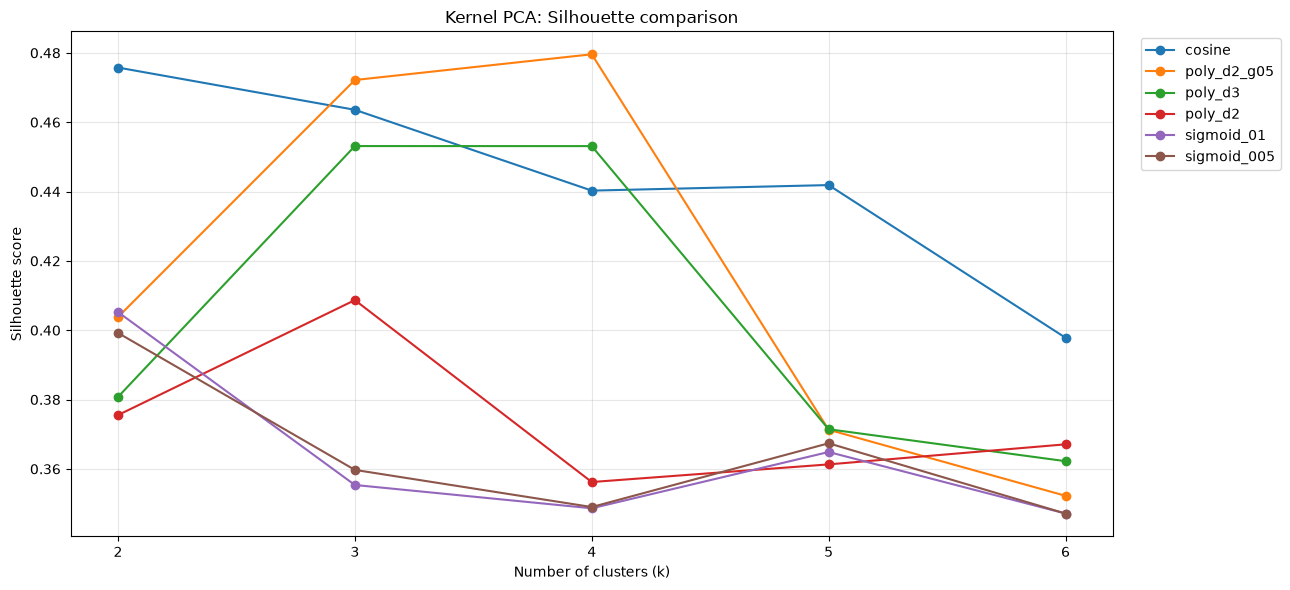

In [ ]:
import matplotlib.pyplot as plt

top_kernels = (
    balanced_kernel_results
    .sort_values("silhouette", ascending=False)
    .head(10)
    .copy()
)

plt.figure(figsize=(13, 6))

for kernel_name in top_kernels["kernel"].unique():
    subset = kernel_results_df[
        kernel_results_df["kernel"] == kernel_name
    ]

    plt.plot(
        subset["k"],
        subset["silhouette"],
        marker="o",
        label=kernel_name
    )

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Kernel PCA: Silhouette comparison")
plt.xticks(range(2, 7))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
top_configs = (
    balanced_kernel_results
    .sort_values("silhouette", ascending=False)
    .head(10)
)

display(
    top_configs[
        [
            "kernel",
            "k",
            "silhouette",
            "davies_bouldin",
            "calinski_harabasz",
            "smallest_cluster_pct",
            "largest_cluster_pct"
        ]
    ].round(4)
)

,kernel,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,largest_cluster_pct
35,cosine,2,0.4758,0.8820,7707.8166,46.7161,53.2839
56,poly_d2_g05,3,0.4722,0.8933,3243.2311,6.4990,74.6359
36,cosine,3,0.4636,0.8385,7727.2444,27.3427,40.7942
46,poly_d3,3,0.4531,0.9086,3336.4065,6.4029,71.1459
38,cosine,5,0.4419,0.7848,7984.1362,12.1187,29.1838
37,cosine,4,0.4403,0.8141,7640.6148,14.0148,35.4905
41,poly_d2,3,0.4087,0.9323,4296.0870,8.9035,62.3935
70,sigmoid_01,2,0.4052,0.9114,6732.5330,41.3713,58.6287
55,poly_d2_g05,2,0.4038,0.9926,2440.2137,19.7719,80.2281
65,sigmoid_005,2,0.3992,0.9172,6443.9913,40.5743,59.4257


In [ ]:
from sklearn.cluster import KMeans

X = feature_representation_results[
    "A_70pct_with_extreme"
]["distance_speed_tracks"]["X"]

shortlisted_models = {
    "cosine_k2": 2,
    "cosine_k3": 3
}

shortlisted_labels = {}

for name, k in shortlisted_models.items():

    X_kernel = kernel_embeddings["cosine"]

    model = KMeans(
        n_clusters=k,
        n_init=20,
        max_iter=300,
        random_state=42
    )

    labels = model.fit_predict(X_kernel)

    shortlisted_labels[name] = labels

    print(f"\n{name}")
    print(pd.Series(labels).value_counts().sort_index())


cosine_k2
0    3878
1    3400
Name: count, dtype: int64

cosine_k3
0    2319
1    2969
2    1990
Name: count, dtype: int64


In [ ]:
from sklearn.metrics import silhouette_score

for name, labels in shortlisted_labels.items():

    X_kernel = kernel_embeddings["cosine"]

    print(
        name,
        "Silhouette:",
        round(silhouette_score(
            X_kernel,
            labels,
            sample_size=min(3000, len(X_kernel)),
            random_state=42
        ), 4)
    )

cosine_k2 Silhouette: 0.4758
cosine_k3 Silhouette: 0.4636


In [ ]:
import pandas as pd
from pathlib import Path

DATA_A_PATH = Path(
    "../data/processed/tour_level/pca_experiments/"
    "experiment_A_70pct_with_extreme.csv"
)

df_A = pd.read_csv(DATA_A_PATH)

print("Dataset A shape:", df_A.shape)
print("Columns:", df_A.columns.tolist())

# Verify row alignment before attaching labels.
assert len(df_A) == len(shortlisted_labels["cosine_k2"])
assert len(df_A) == len(shortlisted_labels["cosine_k3"])

df_A["cluster_cosine_k2"] = shortlisted_labels["cosine_k2"]
df_A["cluster_cosine_k3"] = shortlisted_labels["cosine_k3"]

display(df_A.head())

Dataset A shape: (7278, 31)
Columns: ['vehicle_id', 'tour_id', 'track_count', 'start_time', 'last_track_start', 'end_time', 'total_distance_km', 'total_valid_track_duration_seconds', 'valid_duration_track_count', 'home_base_endpoint', 'elapsed_span_hours', 'recorded_track_hours', 'distance_based_avg_speed_kmh', 'fleet_test_id', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'home_base', 'cid', 'negative_elapsed_span', 'non_positive_distance', 'duration_incomplete', 'duration_unusable', 'high_distance_based_speed', 'requires_quality_review', 'extreme_derived_speed', 'distance_based_avg_speed_kmh_clean', 'unrecorded_gap_hours', 'unrecorded_ratio', 'unrecorded_percentage']


,vehicle_id,tour_id,track_count,start_time,last_track_start,end_time,total_distance_km,total_valid_track_duration_seconds,valid_duration_track_count,home_base_endpoint,...,duration_unusable,high_distance_based_speed,requires_quality_review,extreme_derived_speed,distance_based_avg_speed_kmh_clean,unrecorded_gap_hours,unrecorded_ratio,unrecorded_percentage,cluster_cosine_k2,cluster_cosine_k3
0,1,0,3,2021-09-10 09:04:53.598000+00:00,2021-09-10 11:25:20.146000+00:00,2021-09-10 12:09:50.802000+00:00,57.945,7412.956,3,True,...,False,False,False,False,28.140191,1.023402,0.331998,33.199786,1,1
1,1,4,16,2021-10-07 10:19:52.098000+00:00,2021-10-09 06:35:21.071000+00:00,2021-10-09 07:59:24.414000+00:00,1291.041,74143.179,16,True,...,False,False,False,False,62.686112,25.063649,0.548931,54.893147,0,2
2,1,6,5,2021-10-11 06:12:38.147000+00:00,2021-10-11 10:43:29.014000+00:00,2021-10-11 11:27:17.033000+00:00,64.381,9649.372,5,True,...,False,False,False,False,24.019346,2.563754,0.488880,48.888022,1,1
3,1,8,18,2021-10-11 13:05:55.392000+00:00,2021-10-13 12:56:09.903000+00:00,2021-10-13 13:45:49.873000+00:00,959.976,65111.842,18,True,...,False,False,False,False,53.076576,30.578511,0.628345,62.834536,0,2
4,1,10,18,2021-10-13 15:48:39.651000+00:00,2021-10-15 14:56:58.239000+00:00,2021-10-15 15:41:40.279000+00:00,1176.021,72737.804,18,True,...,False,False,False,False,58.204611,27.678562,0.578040,57.803957,0,2


In [ ]:
profile_features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "recorded_track_hours",
    "track_count"
]

for cluster_col in ["cluster_cosine_k2", "cluster_cosine_k3"]:

    print(f"\n{'='*70}")
    print(f"CLUSTER PROFILES: {cluster_col}")
    print(f"{'='*70}")

    profile = df_A.groupby(cluster_col)[profile_features].agg(
        ["count", "median", "mean", "std"]
    )

    display(profile.round(2))


CLUSTER PROFILES: cluster_cosine_k2


total_distance_km                          \
                              count  median    mean     std   
cluster_cosine_k2                                             
0                              3878  208.82  314.51  328.58   
1                              3400   23.40   33.89   33.03   

                  distance_based_avg_speed_kmh_clean                      \
                                               count median   mean   std   
cluster_cosine_k2                                                          
0                                               3878  49.77  49.95  13.5   
1                                               3400  18.09  19.43  11.5   

                  recorded_track_hours                    track_count         \
                                 count median  mean   std       count median   
cluster_cosine_k2                                                              
0                                 3878   4.43  6.34  8.01        3878    6.0   
1                                 3400   1.24  1.74  2.08        3400    3.0   

                                
                   mean    std  
cluster_cosine_k2               
0                  9.12  20.43  
1                  4.06   5.60


CLUSTER PROFILES: cluster_cosine_k3


total_distance_km                          \
                              count  median    mean     std   
cluster_cosine_k3                                             
0                              2319  193.45  223.95  146.09   
1                              2969   20.05   28.42   28.60   
2                              1990  197.90  367.43  431.61   

                  distance_based_avg_speed_kmh_clean                       \
                                               count median   mean    std   
cluster_cosine_k3                                                           
0                                               2319  53.70  53.63  11.71   
1                                               2969  17.09  18.30  10.92   
2                                               1990  39.96  40.74  15.50   

                  recorded_track_hours                     track_count         \
                                 count median  mean    std       count median   
cluster_cosine_k3                                                               
0                                 2319   3.71  4.05   2.25        2319    4.0   
1                                 2969   1.04  1.44   1.36        2969    3.0   
2                                 1990   5.37  8.45  10.66        1990   10.0   

                                 
                    mean    std  
cluster_cosine_k3                
0                   4.10   1.50  
1                   3.30   1.83  
2                  15.01  28.09

In [ ]:
import numpy as np
import pandas as pd

X = feature_representation_results[
    "A_70pct_with_extreme"
]["distance_speed_tracks"]["X"]

print("Input shape:", X.shape)
print("Number of input features:", X.shape[1])

X_cosine = kernel_embeddings["cosine"]

print("Cosine embedding shape:", X_cosine.shape)

# Check variance of each embedding component
component_variance = np.var(X_cosine, axis=0)

variance_df = pd.DataFrame({
    "component": [
        f"PC{i+1}" for i in range(len(component_variance))
    ],
    "variance": component_variance
})

display(variance_df)

Input shape: (7278, 3)
Number of input features: 3
Cosine embedding shape: (7278, 5)


,component,variance
0,PC1,0.595067
1,PC2,0.314378
2,PC3,0.085285
3,PC4,0.000000
4,PC5,0.000000


In [ ]:
from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

cosine_dimension_results = []
cosine_dimension_embeddings = {}

for n_components in [2, 3]:

    kpca = KernelPCA(
        n_components=n_components,
        kernel="cosine",
        eigen_solver="arpack",
        random_state=42
    )

    X_kpca = kpca.fit_transform(X)

    cosine_dimension_embeddings[n_components] = X_kpca

    for k in range(2, 7):

        model = KMeans(
            n_clusters=k,
            n_init=20,
            max_iter=300,
            random_state=42
        )

        labels = model.fit_predict(X_kpca)

        counts = np.bincount(labels)

        cosine_dimension_results.append({
            "components": n_components,
            "k": k,
            "silhouette": silhouette_score(
                X_kpca,
                labels,
                sample_size=min(3000, len(X_kpca)),
                random_state=42
            ),
            "smallest_cluster_pct": counts.min() / len(labels) * 100,
            "largest_cluster_pct": counts.max() / len(labels) * 100
        })

cosine_dimension_df = pd.DataFrame(cosine_dimension_results)

display(
    cosine_dimension_df.sort_values(
        "silhouette", ascending=False
    ).round(4)
)

,components,k,silhouette,smallest_cluster_pct,largest_cluster_pct
3,2,5,0.5403,12.2836,29.9121
1,2,3,0.5293,27.3289,40.8217
0,2,2,0.5225,46.7024,53.2976
2,2,4,0.5168,14.0286,35.4218
4,2,6,0.5069,10.5249,23.8939
5,3,2,0.4758,46.7161,53.2839
6,3,3,0.4636,27.3427,40.7942
8,3,5,0.4419,12.1187,29.1838
7,3,4,0.4403,14.0148,35.4905
9,3,6,0.3979,11.4867,26.3534


In [ ]:
from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

component_results = []
component_embeddings = {}

for n_components in [1, 2, 3]:

    kpca = KernelPCA(
        n_components=n_components,
        kernel="cosine",
        eigen_solver="arpack",
        random_state=42
    )

    X_kpca = kpca.fit_transform(X)
    component_embeddings[n_components] = X_kpca

    for k in range(2, 8):

        km = KMeans(
            n_clusters=k,
            n_init=20,
            max_iter=300,
            random_state=42
        )

        labels = km.fit_predict(X_kpca)
        counts = np.bincount(labels)

        component_results.append({
            "components": n_components,
            "k": k,
            "silhouette": silhouette_score(
                X_kpca,
                labels,
                sample_size=min(3000, len(X_kpca)),
                random_state=42
            ),
            "smallest_cluster_pct": counts.min() / len(labels) * 100,
            "largest_cluster_pct": counts.max() / len(labels) * 100
        })

component_results_df = pd.DataFrame(component_results)

display(
    component_results_df.sort_values(
        "silhouette",
        ascending=False
    ).round(4)
)

,components,k,silhouette,smallest_cluster_pct,largest_cluster_pct
0,1,2,0.7440,46.7024,53.2976
1,1,3,0.7173,18.7826,43.1849
2,1,4,0.6755,13.7538,37.2080
3,1,5,0.6641,11.7477,31.5334
4,1,6,0.6505,9.0547,29.2113
5,1,7,0.6485,6.9112,28.3732
9,2,5,0.5403,12.2836,29.9121
7,2,3,0.5293,27.3289,40.8217
6,2,2,0.5225,46.7024,53.2976
8,2,4,0.5168,14.0286,35.4218


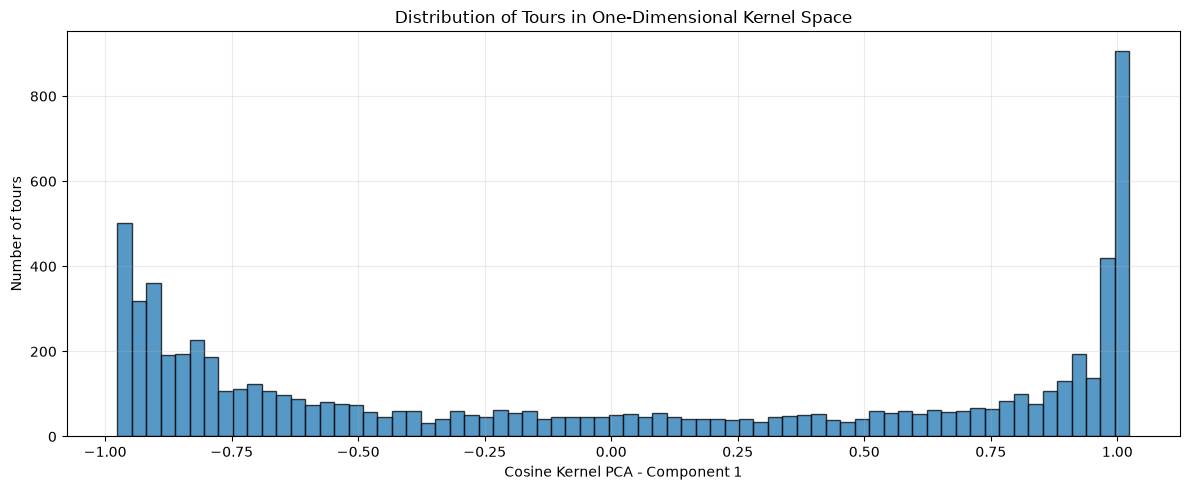

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

X_cosine_1d = component_embeddings[1]

plt.figure(figsize=(12, 5))

plt.hist(
    X_cosine_1d[:, 0],
    bins=70,
    edgecolor="black",
    alpha=0.75
)

plt.xlabel("Cosine Kernel PCA - Component 1")
plt.ylabel("Number of tours")
plt.title("Distribution of Tours in One-Dimensional Kernel Space")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

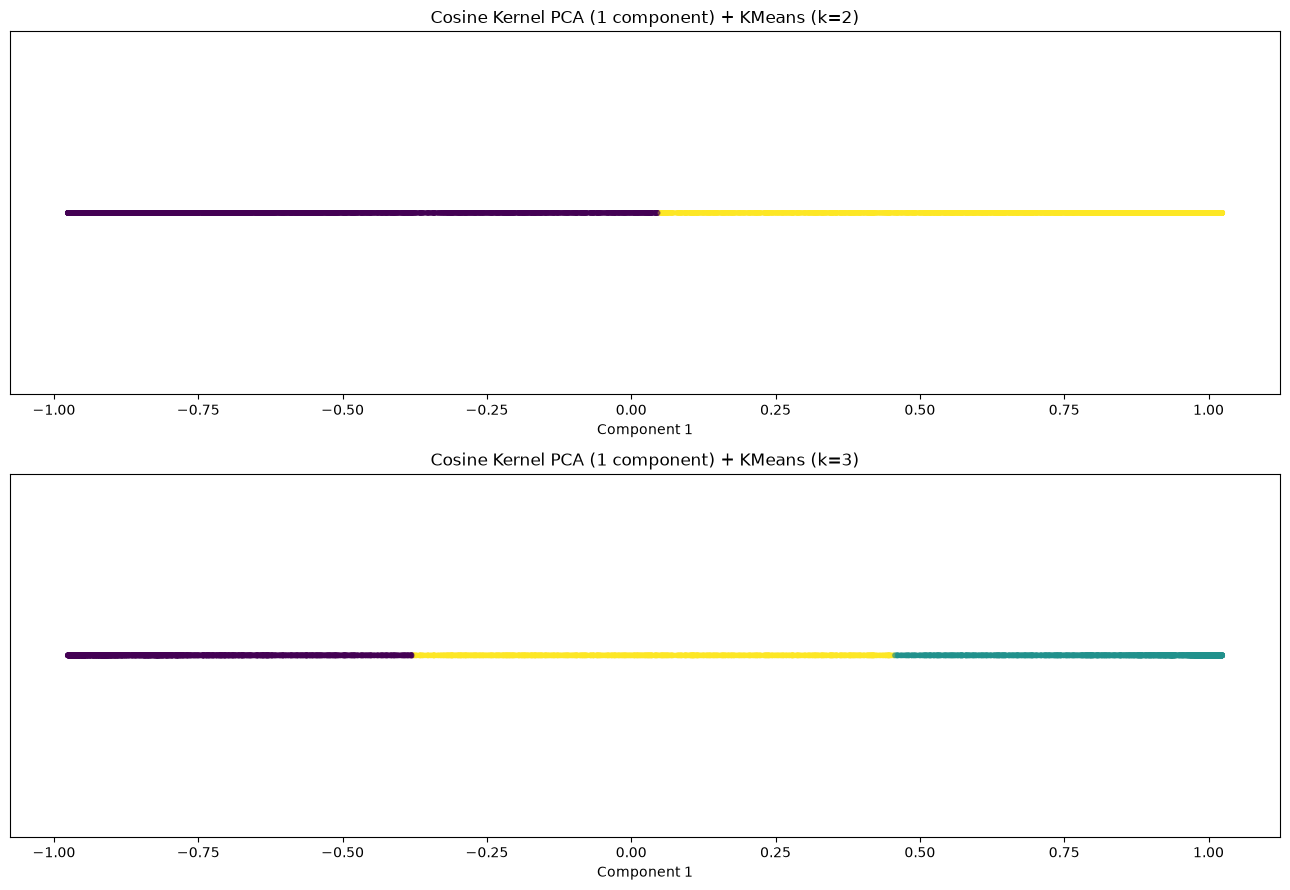

In [ ]:
from sklearn.cluster import KMeans

X_cosine_1d = component_embeddings[1]

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

for ax, k in zip(axes, [2, 3]):

    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )

    labels = model.fit_predict(X_cosine_1d)

    ax.scatter(
        X_cosine_1d[:, 0],
        np.zeros(len(X_cosine_1d)),
        c=labels,
        cmap="viridis",
        s=9,
        alpha=0.5
    )

    ax.set_title(f"Cosine Kernel PCA (1 component) + KMeans (k={k})")
    ax.set_xlabel("Component 1")
    ax.set_yticks([])

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from sklearn.decomposition import KernelPCA

kpca_variance = KernelPCA(
    n_components=3,
    kernel="cosine",
    eigen_solver="arpack",
    random_state=42
)

kpca_variance.fit(X)

eigenvalues = kpca_variance.eigenvalues_

# Keep positive eigenvalues to avoid numerical noise
positive_eigenvalues = eigenvalues[eigenvalues > 1e-10]

explained_ratio = (
    positive_eigenvalues / positive_eigenvalues.sum()
)

cumulative_ratio = np.cumsum(explained_ratio)

variance_table = pd.DataFrame({
    "Component": [
        f"PC{i+1}" for i in range(len(explained_ratio))
    ],
    "Eigenvalue": positive_eigenvalues,
    "Explained_Variance_%": explained_ratio * 100,
    "Cumulative_Variance_%": cumulative_ratio * 100
})

display(variance_table.round(4))

,Component,Eigenvalue,Explained_Variance_%,Cumulative_Variance_%
0,PC1,4330.8976,59.8220,59.8220
1,PC2,2288.0453,31.6044,91.4263
2,PC3,620.7033,8.5737,100.0000


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

X_1d = component_embeddings[1]

candidate_labels = {}

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        n_init=20,
        max_iter=300,
        random_state=42
    )

    labels = model.fit_predict(X_1d)

    candidate_labels[k] = labels

    print(f"\nCosine KPCA: 1 component, k={k}")
    print("Silhouette:",
          round(silhouette_score(X_1d, labels), 4))

    print("Cluster percentages:")
    print(
        pd.Series(labels)
        .value_counts(normalize=True)
        .sort_index()
        .mul(100)
        .round(2)
    )



Cosine KPCA: 1 component, k=2
Silhouette: 0.7489
Cluster percentages:
0    53.3
1    46.7
Name: proportion, dtype: float64

Cosine KPCA: 1 component, k=3
Silhouette: 0.7185
Cluster percentages:
0    43.18
1    38.03
2    18.78
Name: proportion, dtype: float64


In [ ]:
from sklearn.metrics import adjusted_rand_score
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

stability_results = []

for k in [2, 3]:

    labels_by_seed = {}

    for seed in [21, 42, 63, 84, 105]:

        model = KMeans(
            n_clusters=k,
            n_init=20,
            max_iter=300,
            random_state=seed
        )

        labels = model.fit_predict(X_1d)
        labels_by_seed[seed] = labels

    seeds = list(labels_by_seed.keys())

    for i in range(len(seeds)):
        for j in range(i + 1, len(seeds)):

            ari = adjusted_rand_score(
                labels_by_seed[seeds[i]],
                labels_by_seed[seeds[j]]
            )

            stability_results.append({
                "k": k,
                "seed_1": seeds[i],
                "seed_2": seeds[j],
                "ARI": ari
            })

stability_df = pd.DataFrame(stability_results)

display(
    stability_df.groupby("k")["ARI"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

,mean,std,min,max
k,,,,
2,1.0000,0.0000,1.0000,1.000
3,0.9952,0.0026,0.9907,0.999


In [ ]:
# Reload original Dataset A
df_A = pd.read_csv(DATA_A_PATH)

# Ensure row counts match before assigning labels
assert len(df_A) == len(X_1d), (
    "Dataset and embedding row counts do not match!"
)

for k, labels in candidate_labels.items():

    cluster_col = f"cosine_1d_k{k}"

    df_A[cluster_col] = labels

    print(f"\n{'='*70}")
    print(f"COSINE KERNEL PCA: 1 COMPONENT, K={k}")
    print(f"{'='*70}")

    profile = df_A.groupby(cluster_col)[
        [
            "total_distance_km",
            "distance_based_avg_speed_kmh_clean",
            "recorded_track_hours",
            "track_count"
        ]
    ].agg(["count", "median", "mean", "std"])

    display(profile.round(2))


COSINE KERNEL PCA: 1 COMPONENT, K=2


total_distance_km                          \
                         count  median    mean     std   
cosine_1d_k2                                             
0                         3879  208.79  314.50  328.54   
1                         3399   23.41   33.82   32.84   

             distance_based_avg_speed_kmh_clean                       \
                                          count median   mean    std   
cosine_1d_k2                                                           
0                                          3879  49.77  49.88  13.61   
1                                          3399  18.10  19.50  11.55   

             recorded_track_hours                    track_count               \
                            count median  mean   std       count median  mean   
cosine_1d_k2                                                                    
0                            3879   4.43  6.36  8.02        3879    6.0  9.19   
1                            3399   1.24  1.72  1.96        3399    3.0  3.98   

                     
                std  
cosine_1d_k2         
0             20.54  
1              5.03


COSINE KERNEL PCA: 1 COMPONENT, K=3


total_distance_km                          \
                         count  median    mean     std   
cosine_1d_k3                                             
0                         3143  253.22  363.37  346.47   
1                         2768   18.15   24.61   23.80   
2                         1367   78.72   91.23   47.07   

             distance_based_avg_speed_kmh_clean                       \
                                          count median   mean    std   
cosine_1d_k3                                                           
0                                          3143  53.80  53.13  11.74   
1                                          2768  16.00  17.21  10.32   
2                                          1367  34.48  33.02  12.25   

             recorded_track_hours                     track_count         \
                            count median  mean    std       count median   
cosine_1d_k3                                                               
0                            3143   4.81  6.68   5.92        3143    6.0   
1                            2768   0.97  1.35   1.25        2768    3.0   
2                            1367   2.44  4.22  10.32        1367    4.0   

                           
              mean    std  
cosine_1d_k3               
0             8.57   9.25  
1             3.30   1.85  
2             9.59  32.46

In [ ]:
display(
    stability_df.groupby("k")["ARI"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

,mean,std,min,max
k,,,,
2,1.0000,0.0000,1.0000,1.000
3,0.9952,0.0026,0.9907,0.999


In [ ]:
from sklearn.decomposition import KernelPCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

cross_dataset_results = []
cross_dataset_embeddings = {}
cross_dataset_labels = {}

for dataset_name, representations in feature_representation_results.items():

    X_dataset = representations["distance_speed_tracks"]["X"]

    kpca = KernelPCA(
        n_components=1,
        kernel="cosine",
        eigen_solver="arpack",
        random_state=42
    )

    X_embedding = kpca.fit_transform(X_dataset)

    cross_dataset_embeddings[dataset_name] = X_embedding

    for k in [2, 3]:

        model = KMeans(
            n_clusters=k,
            n_init=20,
            max_iter=300,
            random_state=42
        )

        labels = model.fit_predict(X_embedding)
        counts = np.bincount(labels)

        cross_dataset_labels[(dataset_name, k)] = labels

        cross_dataset_results.append({
            "dataset": dataset_name,
            "k": k,
            "silhouette": silhouette_score(
                X_embedding,
                labels,
                sample_size=min(3000, len(X_embedding)),
                random_state=42
            ),
            "smallest_cluster_pct": counts.min() / len(labels) * 100,
            "largest_cluster_pct": counts.max() / len(labels) * 100
        })

cross_dataset_df = pd.DataFrame(cross_dataset_results)

display(cross_dataset_df.round(4))

,dataset,k,silhouette,smallest_cluster_pct,largest_cluster_pct
0,A_70pct_with_extreme,2,0.7440,46.7024,53.2976
1,A_70pct_with_extreme,3,0.7173,18.7826,43.1849
2,B_75pct_without_extreme,2,0.7483,46.2250,53.7750
3,B_75pct_without_extreme,3,0.7121,19.1062,42.9591
4,C_absolute_gap_24h,2,0.7624,46.6387,53.3613
5,C_absolute_gap_24h,3,0.7052,17.4923,43.6118


In [ ]:

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.decomposition import KernelPCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Use the same Dataset A regression-safe feature matrix
X = feature_representation_results[
    "A_70pct_with_extreme"
]["distance_speed_tracks"]["X"]

X = np.asarray(X)

print("Original feature matrix:", X.shape)
print("Missing values:", np.isnan(X).sum())

# Store comparison results
comparison_results = []

# Representations to compare
representations = {
    "Original_3D": X
}

# Fit cosine Kernel PCA with 1 and 2 components
for n_components in [1, 2]:

    kpca = KernelPCA(
        n_components=n_components,
        kernel="cosine",
        eigen_solver="arpack",
        random_state=42
    )

    X_transformed = kpca.fit_transform(X)

    representations[f"Cosine_KPCA_{n_components}D"] = X_transformed

# Evaluate each representation for k = 2 and k = 3
for representation_name, X_rep in representations.items():

    for k in [2, 3]:

        kmeans = KMeans(
            n_clusters=k,
            n_init=20,
            max_iter=300,
            random_state=42
        )

        labels = kmeans.fit_predict(X_rep)

        # Silhouette in the representation used by KMeans
        silhouette_representation = silhouette_score(
            X_rep,
            labels,
            sample_size=min(3000, len(X_rep)),
            random_state=42
        )

        # Evaluate the same labels in the original 3D feature space
        silhouette_original = silhouette_score(
            X,
            labels,
            sample_size=min(3000, len(X)),
            random_state=42
        )

        # Additional cluster quality metrics in original feature space
        db_original = davies_bouldin_score(X, labels)
        ch_original = calinski_harabasz_score(X, labels)

        cluster_sizes = pd.Series(labels).value_counts(normalize=True)

        comparison_results.append({
            "Representation": representation_name,
            "K": k,
            "Silhouette_Representation": silhouette_representation,
            "Silhouette_Original": silhouette_original,
            "Davies_Bouldin_Original": db_original,
            "Calinski_Harabasz_Original": ch_original,
            "Smallest_Cluster_%": cluster_sizes.min() * 100,
            "Largest_Cluster_%": cluster_sizes.max() * 100
        })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="Silhouette_Original",
    ascending=False
).reset_index(drop=True)

comparison_df.round(4)


Original feature matrix: (7278, 3)
Missing values: 0


,Representation,K,Silhouette_Representation,Silhouette_Original,Davies_Bouldin_Original,Calinski_Harabasz_Original,Smallest_Cluster_%,Largest_Cluster_%
0,Original_3D,2,0.3967,0.3967,0.9213,6272.1548,40.5881,59.4119
1,Cosine_KPCA_2D,2,0.5225,0.3880,0.9535,6182.7813,46.7024,53.2976
2,Cosine_KPCA_1D,2,0.7440,0.3878,0.9533,6183.9885,46.7024,53.2976
3,Original_3D,3,0.3636,0.3636,1.0313,5562.4023,17.3399,49.5054
4,Cosine_KPCA_2D,3,0.5293,0.3335,1.0993,5060.2010,27.3289,40.8217
5,Cosine_KPCA_1D,3,0.7173,0.2430,1.5445,4099.7277,18.7826,43.1849


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. Locate the exported track-cluster assignments
# --------------------------------------------------

assignment_candidates = [
    Path("../src/anomaly_detection/data/track_cluster_assignments.csv"),
    Path("src/anomaly_detection/data/track_cluster_assignments.csv"),
]

ASSIGNMENT_PATH = next(
    (p for p in assignment_candidates if p.exists()),
    None
)

if ASSIGNMENT_PATH is None:
    raise FileNotFoundError(
        "Could not locate track_cluster_assignments.csv. "
        "Please set ASSIGNMENT_PATH to its actual location."
    )

track_clusters = pd.read_csv(ASSIGNMENT_PATH)

print("Assignment file:", ASSIGNMENT_PATH)
print("Assignment shape:", track_clusters.shape)
print("Columns:", track_clusters.columns.tolist())

# --------------------------------------------------
# 2. Validate the assignment table
# --------------------------------------------------

required_assignment_cols = {"track_id", "vehicle_id", "cluster"}

assert required_assignment_cols.issubset(track_clusters.columns)
assert track_clusters["track_id"].is_unique
assert track_clusters["track_id"].notna().all()
assert track_clusters["cluster"].notna().all()

print("\nCluster distribution:")
display(
    track_clusters["cluster"]
    .value_counts()
    .sort_index()
    .rename("track_count")
    .to_frame()
)

# --------------------------------------------------
# 3. Locate the original track metadata
# --------------------------------------------------

# Search common project locations.
track_candidates = [
    Path("../data/raw/tracks.csv"),
    Path("../data/tracks.csv"),
    Path("data/raw/tracks.csv"),
    Path("data/tracks.csv"),
]

TRACKS_PATH = next(
    (p for p in track_candidates if p.exists()),
    None
)

print("\nCurrent working directory:", Path.cwd())
print("Track metadata file:", TRACKS_PATH)

if TRACKS_PATH is not None:

    tracks_metadata = pd.read_csv(
        TRACKS_PATH,
        usecols=lambda c: c in [
            "track_id",
            "tour_id",
            "vehicle_id"
        ]
    )

    print("Track metadata shape:", tracks_metadata.shape)
    print("Metadata columns:", tracks_metadata.columns.tolist())

    assert {"track_id", "tour_id", "vehicle_id"}.issubset(
        tracks_metadata.columns
    )

    assert tracks_metadata["track_id"].is_unique

else:
    print(
        "Track metadata CSV not found in the standard locations. "
        "We need to identify its actual path before joining."
    )


Assignment file: ../src/anomaly_detection/data/track_cluster_assignments.csv
Assignment shape: (148359, 3)
Columns: ['track_id', 'vehicle_id', 'cluster']

Cluster distribution:


,track_count
cluster,
0,53133
1,59590
2,35636



Current working directory: /Users/janibhargesh/Documents/ML-Project/notebooks
Track metadata file: None
Track metadata CSV not found in the standard locations. We need to identify its actual path before joining.


In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np

# Project root: parent of notebooks/
PROJECT_ROOT = Path.cwd().parent

TRACKS_PATH = PROJECT_ROOT / "data/raw/tracks/tracks.csv"

assert TRACKS_PATH.exists(), f"File not found: {TRACKS_PATH}"

# Load only the columns needed for aggregation
tracks_metadata = pd.read_csv(
    TRACKS_PATH,
    usecols=[
        "track_id",
        "tour_id",
        "vehicle_id"
    ]
)

print("Track metadata shape:", tracks_metadata.shape)
print("Unique tracks:", tracks_metadata["track_id"].nunique())
print("Unique tours:", tracks_metadata["tour_id"].nunique())
print("Unique vehicles:", tracks_metadata["vehicle_id"].nunique())

# Validate identifiers
assert tracks_metadata["track_id"].is_unique
assert tracks_metadata["track_id"].notna().all()
assert tracks_metadata["tour_id"].notna().all()
assert tracks_metadata["vehicle_id"].notna().all()

# --------------------------------------------------
# Join track assignments with tour metadata
# --------------------------------------------------

track_level = track_clusters.merge(
    tracks_metadata,
    on=["track_id", "vehicle_id"],
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nJoin results:")
print(track_level["_merge"].value_counts())

# Check whether every assigned track has tour metadata
unmatched_tracks = track_level.loc[
    track_level["_merge"] != "both"
]

print("\nUnmatched assigned tracks:", len(unmatched_tracks))

# Retain successfully matched tracks
track_level = track_level.loc[
    track_level["_merge"] == "both"
].drop(columns="_merge").copy()

# --------------------------------------------------
# Check tour and vehicle relationships
# --------------------------------------------------

print("\nMatched track rows:", len(track_level))
print(
    "Unique vehicle-tour combinations:",
    track_level[["vehicle_id", "tour_id"]].drop_duplicates().shape[0]
)

vehicles_per_tour = (
    track_level.groupby("tour_id")["vehicle_id"]
    .nunique()
)

print("\nMulti-vehicle tours in assigned population:",
      int((vehicles_per_tour > 1).sum()))

print("\nTrack-level data preview:")
display(track_level.head())


Track metadata shape: (151598, 3)
Unique tracks: 151598
Unique tours: 13444
Unique vehicles: 163

Join results:
_merge
both          148359
left_only          0
right_only         0
Name: count, dtype: int64

Unmatched assigned tracks: 0

Matched track rows: 148359
Unique vehicle-tour combinations: 13518

Multi-vehicle tours in assigned population: 86

Track-level data preview:


,track_id,vehicle_id,cluster,tour_id
0,0,1,0,0
1,1,1,0,0
2,2,1,0,0
3,3,1,1,1
4,4,1,1,1


In [ ]:

# --------------------------------------------------
# 1. Count all tracks per vehicle-tour
# --------------------------------------------------

all_track_counts = (
    tracks_metadata
    .groupby(["vehicle_id", "tour_id"])
    .agg(total_track_count=("track_id", "nunique"))
    .reset_index()
)

# --------------------------------------------------
# 2. Count assigned tracks by cluster
# --------------------------------------------------

cluster_counts = (
    track_level
    .groupby(["vehicle_id", "tour_id", "cluster"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=[0, 1, 2], fill_value=0)
)

cluster_counts.columns = [
    "cluster_0_count",
    "cluster_1_count",
    "cluster_2_count"
]

cluster_counts = cluster_counts.reset_index()

# --------------------------------------------------
# 3. Combine counts
# --------------------------------------------------

tour_movement = all_track_counts.merge(
    cluster_counts,
    on=["vehicle_id", "tour_id"],
    how="left",
    validate="one_to_one"
)

count_cols = [
    "cluster_0_count",
    "cluster_1_count",
    "cluster_2_count"
]

tour_movement[count_cols] = (
    tour_movement[count_cols].fillna(0).astype(int)
)

tour_movement["assigned_track_count"] = (
    tour_movement[count_cols].sum(axis=1)
)

# --------------------------------------------------
# 4. Calculate assignment coverage
# --------------------------------------------------

tour_movement["assignment_coverage_pct"] = (
    tour_movement["assigned_track_count"]
    / tour_movement["total_track_count"]
    * 100
)

# --------------------------------------------------
# 5. Calculate cluster composition
# --------------------------------------------------

for cluster in [0, 1, 2]:

    tour_movement[f"cluster_{cluster}_pct"] = np.where(
        tour_movement["assigned_track_count"] > 0,
        tour_movement[f"cluster_{cluster}_count"]
        / tour_movement["assigned_track_count"] * 100,
        np.nan
    )

# --------------------------------------------------
# 6. Validate
# --------------------------------------------------

print("Vehicle-tour combinations:", len(tour_movement))

print(
    "Tours with no assigned tracks:",
    (tour_movement["assigned_track_count"] == 0).sum()
)

print(
    "Tours with incomplete assignment coverage:",
    (tour_movement["assignment_coverage_pct"] < 100).sum()
)

print(
    "Tours with complete assignment coverage:",
    (tour_movement["assignment_coverage_pct"] == 100).sum()
)

# Verify proportions sum to 100% for tours with assignments
valid = tour_movement["assigned_track_count"] > 0

proportion_sum = (
    tour_movement.loc[valid, [
        "cluster_0_pct",
        "cluster_1_pct",
        "cluster_2_pct"
    ]].sum(axis=1)
)

assert np.allclose(proportion_sum, 100)

print("\nCluster composition summary:")
display(
    tour_movement[
        [
            "cluster_0_pct",
            "cluster_1_pct",
            "cluster_2_pct",
            "assignment_coverage_pct"
        ]
    ].describe().round(2)
)

print("\nSample vehicle-tour records:")
display(tour_movement.head(10))


Vehicle-tour combinations: 13579
Tours with no assigned tracks: 61
Tours with incomplete assignment coverage: 1695
Tours with complete assignment coverage: 11884

Cluster composition summary:


,cluster_0_pct,cluster_1_pct,cluster_2_pct,assignment_coverage_pct
count,13518.00,13518.00,13518.00,13579.00
mean,52.96,27.66,19.38,97.49
std,37.19,31.25,26.31,10.26
min,0.00,0.00,0.00,0.00
25%,16.67,0.00,0.00,100.00
50%,55.56,20.00,8.70,100.00
75%,90.00,50.00,33.33,100.00
max,100.00,100.00,100.00,100.00



Sample vehicle-tour records:


,vehicle_id,tour_id,total_track_count,cluster_0_count,cluster_1_count,cluster_2_count,assigned_track_count,assignment_coverage_pct,cluster_0_pct,cluster_1_pct,cluster_2_pct
0,1,0,3,3,0,0,3,100.000000,100.000000,0.000000,0.000000
1,1,1,7,0,3,4,7,100.000000,0.000000,42.857143,57.142857
2,1,2,8,5,2,1,8,100.000000,62.500000,25.000000,12.500000
3,1,3,104,4,57,42,103,99.038462,3.883495,55.339806,40.776699
4,1,4,16,10,3,2,15,93.750000,66.666667,20.000000,13.333333
5,1,5,48,2,39,6,47,97.916667,4.255319,82.978723,12.765957
6,1,6,5,3,0,2,5,100.000000,60.000000,0.000000,40.000000
7,1,7,1,0,0,1,1,100.000000,0.000000,0.000000,100.000000
8,1,8,18,11,3,4,18,100.000000,61.111111,16.666667,22.222222
9,1,9,1,0,1,0,1,100.000000,0.000000,100.000000,0.000000


In [ ]:

# Distribution of tracks per vehicle-tour
print("Total tracks per vehicle-tour:")
display(
    tour_movement["total_track_count"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .to_frame()
    .round(2)
)

print("\nAssigned tracks per vehicle-tour:")
display(
    tour_movement["assigned_track_count"]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95])
    .to_frame()
    .round(2)
)

# Count vehicle-tour combinations by assigned-track count
track_count_distribution = (
    tour_movement
    .groupby("assigned_track_count")
    .size()
    .reset_index(name="vehicle_tour_count")
    .sort_values("assigned_track_count")
)

print("\nVehicle-tour counts by number of assigned tracks:")
display(track_count_distribution.head(20))

# Inspect different minimum-count thresholds
threshold_rows = []

for threshold in [1, 2, 3, 5, 10, 15, 20, 30]:

    eligible = tour_movement[
        tour_movement["assigned_track_count"] >= threshold
    ]

    threshold_rows.append({
        "minimum_assigned_tracks": threshold,
        "vehicle_tour_count": len(eligible),
        "percentage_retained": (
            len(eligible) / len(tour_movement) * 100
        )
    })

threshold_summary = pd.DataFrame(threshold_rows)

print("\nEffect of minimum assigned-track thresholds:")
display(threshold_summary.round(2))

# Coverage distribution
print("\nAssignment coverage distribution:")
display(
    tour_movement["assignment_coverage_pct"]
    .describe(percentiles=[0.01, 0.05, 0.10, 0.25, 0.50, 0.75])
    .to_frame()
    .round(2)
)


Total tracks per vehicle-tour:


,total_track_count
count,13579.00
mean,11.16
std,36.70
min,1.00
10%,1.00
25%,2.00
50%,4.00
75%,8.00
90%,19.00
95%,40.00



Assigned tracks per vehicle-tour:


,assigned_track_count
count,13579.00
mean,10.93
std,36.33
min,0.00
10%,1.00
25%,2.00
50%,4.00
75%,8.00
90%,18.00
95%,40.00



Vehicle-tour counts by number of assigned tracks:


,assigned_track_count,vehicle_tour_count
0,0,61
1,1,1616
2,2,2228
3,3,2001
4,4,1540
5,5,1181
6,6,890
7,7,550
8,8,458
9,9,377



Effect of minimum assigned-track thresholds:


,minimum_assigned_tracks,vehicle_tour_count,percentage_retained
0,1,13518,99.55
1,2,11902,87.65
2,3,9674,71.24
3,5,6133,45.17
4,10,2677,19.71
5,15,1757,12.94
6,20,1279,9.42
7,30,892,6.57



Assignment coverage distribution:


,assignment_coverage_pct
count,13579.00
mean,97.49
std,10.26
min,0.00
1%,50.00
5%,83.33
10%,96.43
25%,100.00
50%,100.00
75%,100.00


In [ ]:

# --------------------------------------------------
# 1. Inspect Dataset A keys
# --------------------------------------------------

required_keys = ["vehicle_id", "tour_id"]

print("Dataset A shape:", df_A.shape)
print("Dataset A columns:", df_A.columns.tolist())

assert all(col in df_A.columns for col in required_keys)

print(
    "Dataset A unique vehicle-tour combinations:",
    df_A[required_keys].drop_duplicates().shape[0]
)

print(
    "Duplicate vehicle-tour rows in Dataset A:",
    df_A.duplicated(required_keys).sum()
)

# --------------------------------------------------
# 2. Validate aggregation keys
# --------------------------------------------------

assert not tour_movement.duplicated(required_keys).any()

# --------------------------------------------------
# 3. Merge movement composition into Dataset A
# --------------------------------------------------

movement_features = [
    "total_track_count",
    "assigned_track_count",
    "assignment_coverage_pct",
    "cluster_0_pct",
    "cluster_1_pct",
    "cluster_2_pct"
]

df_A_enriched = df_A.merge(
    tour_movement[required_keys + movement_features],
    on=required_keys,
    how="left",
    validate="one_to_one",
    indicator=True
)

print("\nMerge results:")
print(df_A_enriched["_merge"].value_counts())

df_A_enriched.drop(columns="_merge", inplace=True)

# --------------------------------------------------
# 4. Check missing composition
# --------------------------------------------------

print("\nDataset A enriched shape:", df_A_enriched.shape)

print(
    "Rows without assigned tracks:",
    df_A_enriched["assigned_track_count"].isna().sum()
)

print(
    "Rows with zero assigned tracks:",
    (df_A_enriched["assigned_track_count"] == 0).sum()
)

print(
    "Rows with fewer than 3 assigned tracks:",
    (df_A_enriched["assigned_track_count"] < 3).sum()
)

print(
    "Rows with coverage below 90%:",
    (df_A_enriched["assignment_coverage_pct"] < 90).sum()
)

display(
    df_A_enriched[
        required_keys + [
            "total_track_count",
            "assigned_track_count",
            "assignment_coverage_pct",
            "cluster_0_pct",
            "cluster_1_pct",
            "cluster_2_pct"
        ]
    ].head(10)
)


Dataset A shape: (7278, 33)
Dataset A columns: ['vehicle_id', 'tour_id', 'track_count', 'start_time', 'last_track_start', 'end_time', 'total_distance_km', 'total_valid_track_duration_seconds', 'valid_duration_track_count', 'home_base_endpoint', 'elapsed_span_hours', 'recorded_track_hours', 'distance_based_avg_speed_kmh', 'fleet_test_id', 'long_haul', 'rest_area', 'service_area_fuel', 'industrial_area', 'home_base', 'cid', 'negative_elapsed_span', 'non_positive_distance', 'duration_incomplete', 'duration_unusable', 'high_distance_based_speed', 'requires_quality_review', 'extreme_derived_speed', 'distance_based_avg_speed_kmh_clean', 'unrecorded_gap_hours', 'unrecorded_ratio', 'unrecorded_percentage', 'cosine_1d_k2', 'cosine_1d_k3']
Dataset A unique vehicle-tour combinations: 7278
Duplicate vehicle-tour rows in Dataset A: 0

Merge results:
_merge
both          7278
left_only        0
right_only       0
Name: count, dtype: int64

Dataset A enriched shape: (7278, 39)
Rows without assigned t

,vehicle_id,tour_id,total_track_count,assigned_track_count,assignment_coverage_pct,cluster_0_pct,cluster_1_pct,cluster_2_pct
0,1,0,3,3,100.000000,100.000000,0.000000,0.000000
1,1,4,16,15,93.750000,66.666667,20.000000,13.333333
2,1,6,5,5,100.000000,60.000000,0.000000,40.000000
3,1,8,18,18,100.000000,61.111111,16.666667,22.222222
4,1,10,18,18,100.000000,61.111111,22.222222,16.666667
5,1,12,23,23,100.000000,60.869565,21.739130,17.391304
6,1,14,34,33,97.058824,42.424242,33.333333,24.242424
7,1,16,15,15,100.000000,73.333333,6.666667,20.000000
8,1,18,28,26,92.857143,50.000000,23.076923,26.923077
9,1,20,17,17,100.000000,58.823529,23.529412,17.647059


In [ ]:

print("Dataset A original rows:", len(df_A))
print("Dataset A enriched rows:", len(df_A_enriched))

# Missing vehicle-tour matches
missing_match = df_A_enriched["total_track_count"].isna()

print("\nVehicle-tour combinations without metadata match:",
      missing_match.sum())

# Assigned-track diagnostics
assigned = df_A_enriched["assigned_track_count"].fillna(0)

print("No assigned tracks:", (assigned == 0).sum())
print("At least 1 assigned track:", (assigned >= 1).sum())
print("At least 2 assigned tracks:", (assigned >= 2).sum())
print("At least 3 assigned tracks:", (assigned >= 3).sum())

# Coverage diagnostics
coverage = df_A_enriched["assignment_coverage_pct"]

print("\nCoverage below 90%:",
      (coverage < 90).sum())

print("Coverage at least 90%:",
      (coverage >= 90).sum())

# Proposed eligibility rule
eligible_mask = (
    (assigned >= 3)
    & (coverage >= 90)
)

print("\nProposed eligible rows:", eligible_mask.sum())
print("Proposed eligible percentage:",
      round(eligible_mask.mean() * 100, 2), "%")

# Inspect excluded rows
print("\nExclusion reasons:")
print({
    "No metadata match": int(missing_match.sum()),
    "Fewer than 3 assigned tracks": int((assigned < 3).sum()),
    "Coverage below 90%": int((coverage < 90).sum()),
    "Eligible": int(eligible_mask.sum())
})


Dataset A original rows: 7278
Dataset A enriched rows: 7278

Vehicle-tour combinations without metadata match: 0
No assigned tracks: 5
At least 1 assigned track: 7273
At least 2 assigned tracks: 7055
At least 3 assigned tracks: 5748

Coverage below 90%: 384
Coverage at least 90%: 6894

Proposed eligible rows: 5431
Proposed eligible percentage: 74.62 %

Exclusion reasons:
{'No metadata match': 0, 'Fewer than 3 assigned tracks': 1530, 'Coverage below 90%': 384, 'Eligible': 5431}


In [ ]:

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# --------------------------------------------------
# 1. Select the same eligible population for both
# --------------------------------------------------

eligible_mask = (
    (df_A_enriched["assigned_track_count"] >= 3)
    & (df_A_enriched["assignment_coverage_pct"] >= 90)
)

experiment_df = df_A_enriched.loc[eligible_mask].copy()

print("Experimental population:", len(experiment_df))

# --------------------------------------------------
# 2. Define feature sets
# --------------------------------------------------

baseline_features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
]

behaviour_features = [
    "cluster_0_pct",
    "cluster_1_pct"
]

required_features = baseline_features + behaviour_features

missing_columns = [
    col for col in required_features
    if col not in experiment_df.columns
]

assert not missing_columns, f"Missing columns: {missing_columns}"

# --------------------------------------------------
# 3. Check track-count consistency
# --------------------------------------------------

track_count_difference = (
    experiment_df["track_count"]
    - experiment_df["total_track_count"]
)

print(
    "Rows where original track_count differs from "
    "metadata total_track_count:",
    (track_count_difference != 0).sum()
)

print("\nTrack-count difference summary:")
display(track_count_difference.describe())

# Keep the original track_count in the baseline to
# preserve the original tour-level representation.

# --------------------------------------------------
# 4. Prepare baseline variables
# --------------------------------------------------

X_baseline_raw = experiment_df[baseline_features].copy()

# Log transform non-negative, right-skewed variables
assert (X_baseline_raw >= 0).all().all()

X_baseline_log = np.log1p(X_baseline_raw)

# Median imputation
baseline_imputer = SimpleImputer(strategy="median")

X_baseline_imputed = baseline_imputer.fit_transform(
    X_baseline_log
)

# Standardization
baseline_scaler = StandardScaler()

X_baseline = baseline_scaler.fit_transform(
    X_baseline_imputed
)

# --------------------------------------------------
# 5. Prepare enriched variables
# --------------------------------------------------

X_enriched_raw = experiment_df[
    baseline_features + behaviour_features
].copy()

# Apply the same log transform to original features
X_enriched_log = X_enriched_raw.copy()

X_enriched_log[baseline_features] = np.log1p(
    X_enriched_log[baseline_features]
)

# Behaviour percentages remain on their original scale
assert X_enriched_log[behaviour_features].notna().all().all()

# Impute original tour features
enriched_imputer = SimpleImputer(strategy="median")

original_part = enriched_imputer.fit_transform(
    X_enriched_log[baseline_features]
)

behaviour_part = X_enriched_log[
    behaviour_features
].to_numpy()

X_enriched_combined = np.column_stack([
    original_part,
    behaviour_part
])

# Standardize all five features
enriched_scaler = StandardScaler()

X_enriched = enriched_scaler.fit_transform(
    X_enriched_combined
)

# --------------------------------------------------
# 6. Validate
# --------------------------------------------------

print("\nBaseline matrix shape:", X_baseline.shape)
print("Enriched matrix shape:", X_enriched.shape)

assert X_baseline.shape[0] == X_enriched.shape[0]
assert np.isfinite(X_baseline).all()
assert np.isfinite(X_enriched).all()

print("\nBaseline features:", baseline_features)
print("Enriched features:", baseline_features + behaviour_features)

print("\nFeature correlation in enriched raw data:")
display(
    experiment_df[
        baseline_features + behaviour_features
    ].corr().round(3)
)


Experimental population: 5431
Rows where original track_count differs from metadata total_track_count: 0

Track-count difference summary:


count    5431.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
dtype: float64


Baseline matrix shape: (5431, 3)
Enriched matrix shape: (5431, 5)

Baseline features: ['total_distance_km', 'distance_based_avg_speed_kmh_clean', 'track_count']
Enriched features: ['total_distance_km', 'distance_based_avg_speed_kmh_clean', 'track_count', 'cluster_0_pct', 'cluster_1_pct']

Feature correlation in enriched raw data:


,total_distance_km,distance_based_avg_speed_kmh_clean,track_count,cluster_0_pct,cluster_1_pct
total_distance_km,1.000,0.556,0.273,-0.091,0.016
distance_based_avg_speed_kmh_clean,0.556,1.000,-0.043,0.269,-0.314
track_count,0.273,-0.043,1.000,-0.289,0.261
cluster_0_pct,-0.091,0.269,-0.289,1.000,-0.795
cluster_1_pct,0.016,-0.314,0.261,-0.795,1.000


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# --------------------------------------------------
# 1. Helper function for evaluation
# --------------------------------------------------

def evaluate_labels(X, labels):
    return {
        "silhouette": silhouette_score(X, labels),
        "davies_bouldin": davies_bouldin_score(X, labels),
        "calinski_harabasz": calinski_harabasz_score(X, labels)
    }


# --------------------------------------------------
# 2. Run KMeans on both representations
# --------------------------------------------------

results = []
cluster_labels = {}

representations = {
    "Baseline_3D": X_baseline,
    "Enriched_5D": X_enriched
}

for representation_name, X_train in representations.items():

    for k in [2, 3]:

        model = KMeans(
            n_clusters=k,
            n_init=20,
            max_iter=300,
            random_state=42
        )

        labels = model.fit_predict(X_train)

        label_key = (representation_name, k)
        cluster_labels[label_key] = labels

        # Evaluate the same labels in both spaces
        baseline_metrics = evaluate_labels(
            X_baseline, labels
        )

        enriched_metrics = evaluate_labels(
            X_enriched, labels
        )

        own_metrics = (
            baseline_metrics
            if representation_name == "Baseline_3D"
            else enriched_metrics
        )

        results.append({
            "representation": representation_name,
            "k": k,
            "silhouette_own_space": own_metrics["silhouette"],
            "silhouette_baseline_space": baseline_metrics["silhouette"],
            "silhouette_enriched_space": enriched_metrics["silhouette"],
            "DB_own_space": (
                davies_bouldin_score(X_train, labels)
            ),
            "CH_own_space": (
                calinski_harabasz_score(X_train, labels)
            ),
            "inertia": model.inertia_,
            "smallest_cluster_pct": (
                pd.Series(labels).value_counts(normalize=True).min() * 100
            ),
            "largest_cluster_pct": (
                pd.Series(labels).value_counts(normalize=True).max() * 100
            )
        })

        print(
            f"\n{representation_name} | k={k}"
        )

        print(
            pd.Series(labels)
            .value_counts()
            .sort_index()
            .rename("tour_count")
        )


# --------------------------------------------------
# 3. Display comparison
# --------------------------------------------------

comparison_results = pd.DataFrame(results)

print("\nControlled KMeans comparison:")
display(
    comparison_results
    .round(4)
    .sort_values(["k", "representation"])
    .reset_index(drop=True)
)



Baseline_3D | k=2
0    4113
1    1318
Name: tour_count, dtype: int64

Baseline_3D | k=3
0    1104
1    1005
2    3322
Name: tour_count, dtype: int64

Enriched_5D | k=2
0    1303
1    4128
Name: tour_count, dtype: int64

Enriched_5D | k=3
0    2918
1    1055
2    1458
Name: tour_count, dtype: int64

Controlled KMeans comparison:


,representation,k,silhouette_own_space,silhouette_baseline_space,silhouette_enriched_space,DB_own_space,CH_own_space,inertia,smallest_cluster_pct,largest_cluster_pct
0,Baseline_3D,2,0.4473,0.4473,0.3357,0.9389,3673.9622,9717.1399,24.2681,75.7319
1,Enriched_5D,2,0.3691,0.3576,0.3691,1.2435,2420.5007,18781.3874,23.9919,76.0081
2,Baseline_3D,3,0.4062,0.4062,0.2841,0.8974,3937.0645,6648.4582,18.5049,61.1674
3,Enriched_5D,3,0.3308,0.2449,0.3308,1.1024,2682.7842,13656.0409,19.4255,53.7286


Cluster distribution:


baseline_cluster
0    4113
1    1318
Name: count, dtype: int64


Cluster proportions:


baseline_cluster
0    75.73
1    24.27
Name: proportion, dtype: float64

total_distance_km                  \
                              mean  median     std   
baseline_cluster                                     
0                           286.26  190.55  324.53   
1                            24.50   18.98   25.04   

                 distance_based_avg_speed_kmh_clean               track_count  \
                                               mean median    std        mean   
baseline_cluster                                                                
0                                             46.91  45.60  14.07        7.83   
1                                             14.07  14.09   7.87        8.85   

                               elapsed_span_hours                
                 median    std               mean median    std  
baseline_cluster                                                 
0                   5.0   8.57              10.34   5.96  14.55  
1                   4.0  32.76               5.84   1.96  27.56

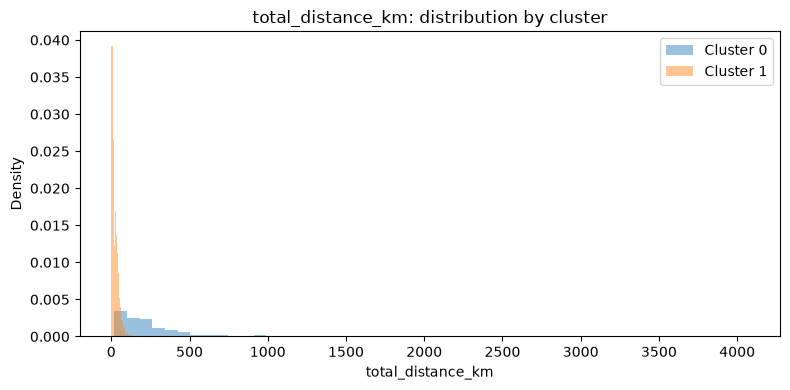

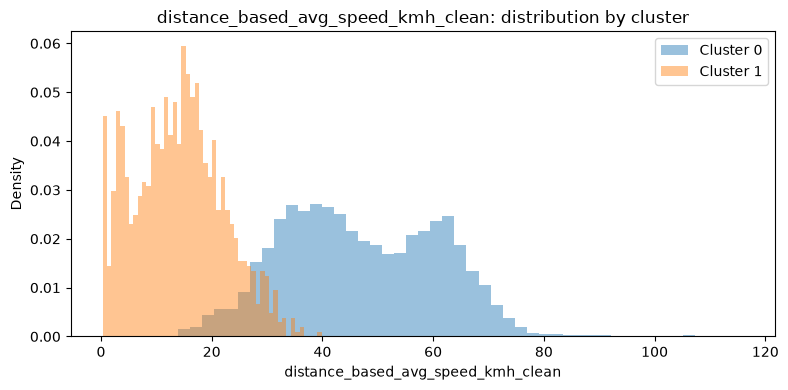

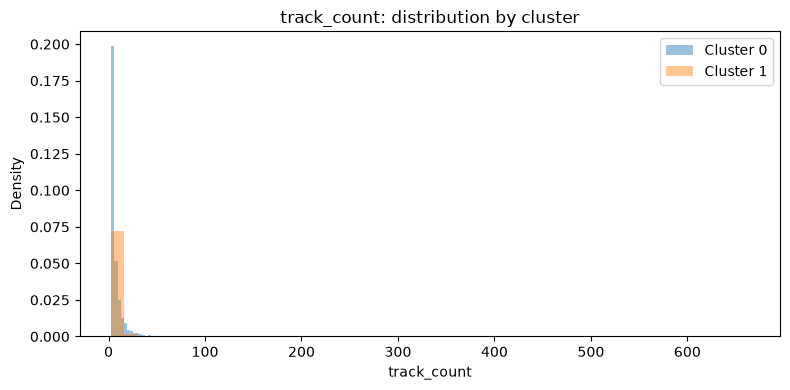


Overall silhouette:
0.4473

Silhouette distribution:


,count,mean,std,min,25%,50%,75%,max
baseline_cluster,,,,,,,,
0,4113.0,0.4867,0.1348,0.0351,0.4057,0.5271,0.6009,0.6449
1,1318.0,0.3242,0.1885,-0.0676,0.1540,0.3773,0.4980,0.5496



Percentage of observations with negative silhouette:
1.45 %

Percentage with silhouette below 0.2:
10.83 %


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples

# --------------------------------------------------
# 1. Fit baseline KMeans
# --------------------------------------------------

baseline_model = KMeans(
    n_clusters=2,
    n_init=20,
    max_iter=300,
    random_state=42
)

baseline_labels = baseline_model.fit_predict(X_baseline)

experiment_df = experiment_df.copy()
experiment_df["baseline_cluster"] = baseline_labels

# --------------------------------------------------
# 2. Cluster distribution
# --------------------------------------------------

print("Cluster distribution:")
display(
    experiment_df["baseline_cluster"]
    .value_counts()
    .sort_index()
)

print("\nCluster proportions:")
display(
    experiment_df["baseline_cluster"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

# --------------------------------------------------
# 3. Profile clusters in original units
# --------------------------------------------------

profile_features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
    "elapsed_span_hours"
]

cluster_profiles = (
    experiment_df
    .groupby("baseline_cluster")[profile_features]
    .agg(["mean", "median", "std"])
)

display(cluster_profiles.round(2))

# --------------------------------------------------
# 4. Feature distributions by cluster
# --------------------------------------------------

for feature in profile_features[:3]:

    plt.figure(figsize=(8, 4))

    for cluster in sorted(experiment_df["baseline_cluster"].unique()):

        values = experiment_df.loc[
            experiment_df["baseline_cluster"] == cluster,
            feature
        ].dropna()

        plt.hist(
            values,
            bins=50,
            alpha=0.45,
            density=True,
            label=f"Cluster {cluster}"
        )

    plt.title(f"{feature}: distribution by cluster")
    plt.xlabel(feature)
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 5. Silhouette values for individual tours
# --------------------------------------------------

sample_silhouettes = silhouette_samples(
    X_baseline,
    baseline_labels
)

experiment_df["silhouette_value"] = sample_silhouettes

print("\nOverall silhouette:")
print(round(sample_silhouettes.mean(), 4))

print("\nSilhouette distribution:")
display(
    experiment_df
    .groupby("baseline_cluster")["silhouette_value"]
    .describe()
    .round(4)
)

print("\nPercentage of observations with negative silhouette:")
print(
    round(
        (sample_silhouettes < 0).mean() * 100,
        2
    ),
    "%"
)

print("\nPercentage with silhouette below 0.2:")
print(
    round(
        (sample_silhouettes < 0.2).mean() * 100,
        2
    ),
    "%"
)


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# --------------------------------------------------
# 1. Prepare two-feature representation
# --------------------------------------------------

two_features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean"
]

X_two_raw = experiment_df[two_features].copy()

assert (X_two_raw >= 0).all().all()

X_two_log = np.log1p(X_two_raw)

two_imputer = SimpleImputer(strategy="median")
X_two_imputed = two_imputer.fit_transform(X_two_log)

two_scaler = StandardScaler()
X_two = two_scaler.fit_transform(X_two_imputed)

# --------------------------------------------------
# 2. Compare two-feature and three-feature models
# --------------------------------------------------

feature_sets = {
    "Distance_Speed": X_two,
    "Distance_Speed_TrackCount": X_baseline
}

comparison = []
two_three_labels = {}

for name, X in feature_sets.items():

    for k in [2, 3]:

        model = KMeans(
            n_clusters=k,
            n_init=20,
            max_iter=300,
            random_state=42
        )

        labels = model.fit_predict(X)
        two_three_labels[(name, k)] = labels

        comparison.append({
            "representation": name,
            "k": k,
            "silhouette": silhouette_score(X, labels),
            "davies_bouldin": davies_bouldin_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels),
            "inertia": model.inertia_,
            "smallest_cluster_pct": (
                pd.Series(labels).value_counts(normalize=True).min() * 100
            ),
            "largest_cluster_pct": (
                pd.Series(labels).value_counts(normalize=True).max() * 100
            )
        })

        print(f"\n{name} | k={k}")
        print(pd.Series(labels).value_counts().sort_index())

comparison_df = pd.DataFrame(comparison)

display(
    comparison_df
    .round(4)
    .sort_values(["k", "representation"])
    .reset_index(drop=True)
)



Distance_Speed | k=2
0    4165
1    1266
Name: count, dtype: int64

Distance_Speed | k=3
0    2417
1     688
2    2326
Name: count, dtype: int64

Distance_Speed_TrackCount | k=2
0    4113
1    1318
Name: count, dtype: int64

Distance_Speed_TrackCount | k=3
0    1104
1    1005
2    3322
Name: count, dtype: int64


,representation,k,silhouette,davies_bouldin,calinski_harabasz,inertia,smallest_cluster_pct,largest_cluster_pct
0,Distance_Speed,2,0.5757,0.6748,8059.3734,4371.9005,23.3106,76.6894
1,Distance_Speed_TrackCount,2,0.4473,0.9389,3673.9622,9717.1399,24.2681,75.7319
2,Distance_Speed,3,0.4826,0.6875,9312.0989,2451.3042,12.6680,44.5038
3,Distance_Speed_TrackCount,3,0.4062,0.8974,3937.0645,6648.4582,18.5049,61.1674


In [ ]:

from sklearn.metrics import adjusted_rand_score

for k in [2, 3]:

    labels_2d = two_three_labels[("Distance_Speed", k)]
    labels_3d = two_three_labels[("Distance_Speed_TrackCount", k)]

    ari = adjusted_rand_score(labels_2d, labels_3d)

    print(f"\nk={k}")
    print("Adjusted Rand Index:", round(ari, 4))

    print("\nTwo-feature cluster profiles:")

    temp = experiment_df[
        [
            "total_distance_km",
            "distance_based_avg_speed_kmh_clean",
            "track_count"
        ]
    ].copy()

    temp["cluster"] = labels_2d

    display(
        temp.groupby("cluster").agg(
            tour_count=("track_count", "size"),
            distance_median=("total_distance_km", "median"),
            speed_median=(
                "distance_based_avg_speed_kmh_clean", "median"
            ),
            track_count_median=("track_count", "median"),
            track_count_mean=("track_count", "mean")
        ).round(2)
    )



k=2
Adjusted Rand Index: 0.9233

Two-feature cluster profiles:


,tour_count,distance_median,speed_median,track_count_median,track_count_mean
cluster,,,,,
0,4165,188.4,45.33,5.0,7.69
1,1266,18.1,13.60,4.0,9.34



k=3
Adjusted Rand Index: 0.2318

Two-feature cluster profiles:


,tour_count,distance_median,speed_median,track_count_median,track_count_mean
cluster,,,,,
0,2417,288.66,56.61,6.0,9.15
1,688,7.44,8.55,4.0,12.09
2,2326,70.82,31.49,5.0,5.77


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
import pandas as pd
import numpy as np

# Reference partition
reference_model = KMeans(
    n_clusters=2,
    n_init=20,
    max_iter=300,
    random_state=42
)

reference_labels = reference_model.fit_predict(X_two)

# Test multiple random seeds
seeds = [0, 10, 21, 42, 50, 100, 123, 202, 500, 999]

stability_results = []

for seed in seeds:

    model = KMeans(
        n_clusters=2,
        n_init=20,
        max_iter=300,
        random_state=seed
    )

    labels = model.fit_predict(X_two)

    stability_results.append({
        "seed": seed,
        "ARI_vs_reference": adjusted_rand_score(
            reference_labels, labels
        ),
        "silhouette": silhouette_score(X_two, labels),
        "inertia": model.inertia_
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

print("\nStability summary:")
print(
    "Mean ARI:",
    round(stability_df["ARI_vs_reference"].mean(), 4)
)
print(
    "Minimum ARI:",
    round(stability_df["ARI_vs_reference"].min(), 4)
)
print(
    "Mean silhouette:",
    round(stability_df["silhouette"].mean(), 4)
)


,seed,ARI_vs_reference,silhouette,inertia
0,0,1.0,0.5757,4371.8984
1,10,1.0,0.5757,4371.9005
2,21,1.0,0.5757,4371.9005
3,42,1.0,0.5757,4371.9005
4,50,1.0,0.5757,4371.9005
5,100,1.0,0.5757,4371.8984
6,123,1.0,0.5757,4371.9005
7,202,1.0,0.5757,4371.9005
8,500,1.0,0.5757,4371.9005
9,999,1.0,0.5757,4371.9005



Stability summary:
Mean ARI: 1.0
Minimum ARI: 1.0
Mean silhouette: 0.5757


In [ ]:

from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

gmm_results = []
gmm_models = {}
gmm_labels = {}

for k in [2, 3]:

    for covariance in ["full", "diag"]:

        model = GaussianMixture(
            n_components=k,
            covariance_type=covariance,
            n_init=5,
            max_iter=300,
            random_state=42,
            reg_covar=1e-6
        )

        model.fit(X_two)

        labels = model.predict(X_two)
        probabilities = model.predict_proba(X_two)

        cluster_sizes = pd.Series(labels).value_counts()

        # Metrics require at least two non-empty clusters
        if len(cluster_sizes) > 1:

            silhouette = silhouette_score(X_two, labels)
            db = davies_bouldin_score(X_two, labels)
            ch = calinski_harabasz_score(X_two, labels)

        else:
            silhouette = np.nan
            db = np.nan
            ch = np.nan

        gmm_results.append({
            "components": k,
            "covariance": covariance,
            "silhouette": silhouette,
            "davies_bouldin": db,
            "calinski_harabasz": ch,
            "BIC": model.bic(X_two),
            "AIC": model.aic(X_two),
            "smallest_cluster_pct": cluster_sizes.min() / len(labels) * 100,
            "largest_cluster_pct": cluster_sizes.max() / len(labels) * 100,
            "mean_max_membership_probability": probabilities.max(axis=1).mean(),
            "converged": model.converged_
        })

        key = (k, covariance)
        gmm_models[key] = model
        gmm_labels[key] = labels

        print(f"\nGMM: k={k}, covariance={covariance}")
        print("Cluster sizes:")
        print(cluster_sizes.sort_index())
        print("Converged:", model.converged_)

gmm_comparison = pd.DataFrame(gmm_results)

print("\nGMM comparison:")
display(
    gmm_comparison
    .round(4)
    .sort_values("BIC")
    .reset_index(drop=True)
)



GMM: k=2, covariance=full
Cluster sizes:
0    1237
1    4194
Name: count, dtype: int64
Converged: True

GMM: k=2, covariance=diag
Cluster sizes:
0    1348
1    4083
Name: count, dtype: int64
Converged: True

GMM: k=3, covariance=full
Cluster sizes:
0    2359
1     684
2    2388
Name: count, dtype: int64
Converged: True

GMM: k=3, covariance=diag
Cluster sizes:
0    2251
1     850
2    2330
Name: count, dtype: int64
Converged: True

GMM comparison:


,components,covariance,silhouette,davies_bouldin,calinski_harabasz,BIC,AIC,smallest_cluster_pct,largest_cluster_pct,mean_max_membership_probability,converged
0,3,full,0.4558,0.7114,8529.6616,21060.2690,20948.0711,12.5944,43.9698,0.8410,True
1,2,full,0.5493,0.7257,6866.9762,21487.0271,21414.4284,22.7767,77.2233,0.9286,True
2,3,diag,0.4675,0.7029,8861.5281,22028.1415,21935.7432,15.6509,42.9019,0.9269,True
3,2,diag,0.5668,0.6910,7941.5637,24739.4899,24680.0910,24.8205,75.1795,0.9569,True


In [ ]:

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

dbscan_results = []
dbscan_models = {}
dbscan_labels = {}

for min_samples in [5, 10]:

    # Distance to the min_samples-th nearest neighbour
    nn = NearestNeighbors(
        n_neighbors=min_samples,
        metric="euclidean"
    )

    nn.fit(X_two)
    distances, _ = nn.kneighbors(X_two)

    k_distances = np.sort(distances[:, -1])

    # Candidate eps values from the observed distance distribution
    eps_values = np.unique(
        np.quantile(
            k_distances,
            [0.90, 0.95, 0.97, 0.98, 0.99]
        ).round(5)
    )

    for eps in eps_values:

        model = DBSCAN(
            eps=float(eps),
            min_samples=min_samples,
            metric="euclidean"
        )

        labels = model.fit_predict(X_two)

        non_noise_mask = labels != -1
        non_noise_labels = labels[non_noise_mask]

        cluster_ids = set(non_noise_labels)
        n_clusters = len(cluster_ids)

        noise_pct = (~non_noise_mask).mean() * 100

        # Evaluate only if at least two clusters remain
        # after excluding noise observations.
        if n_clusters >= 2 and non_noise_mask.sum() > n_clusters:

            silhouette = silhouette_score(
                X_two[non_noise_mask],
                non_noise_labels
            )

            db = davies_bouldin_score(
                X_two[non_noise_mask],
                non_noise_labels
            )

            ch = calinski_harabasz_score(
                X_two[non_noise_mask],
                non_noise_labels
            )

        else:
            silhouette = np.nan
            db = np.nan
            ch = np.nan

        cluster_sizes = (
            pd.Series(non_noise_labels)
            .value_counts()
        )

        dbscan_results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "noise_pct": noise_pct,
            "largest_cluster_pct_of_all": (
                cluster_sizes.max() / len(labels) * 100
                if n_clusters > 0 else np.nan
            ),
            "smallest_cluster_pct_of_all": (
                cluster_sizes.min() / len(labels) * 100
                if n_clusters > 0 else np.nan
            ),
            "silhouette_non_noise": silhouette,
            "davies_bouldin_non_noise": db,
            "calinski_harabasz_non_noise": ch
        })

        dbscan_models[(eps, min_samples)] = model
        dbscan_labels[(eps, min_samples)] = labels

dbscan_comparison = pd.DataFrame(dbscan_results)

display(
    dbscan_comparison
    .round(4)
    .sort_values(
        ["silhouette_non_noise", "noise_pct"],
        ascending=[False, True],
        na_position="last"
    )
    .reset_index(drop=True)
)


,eps,min_samples,n_clusters,noise_pct,largest_cluster_pct_of_all,smallest_cluster_pct_of_all,silhouette_non_noise,davies_bouldin_non_noise,calinski_harabasz_non_noise
0,0.2733,5,2,0.5156,98.7111,0.7733,0.6444,0.3335,532.6982
1,0.2223,10,3,1.6387,97.7536,0.2394,0.6401,0.3122,223.0827
2,0.2728,10,3,0.9575,98.2876,0.3130,0.6330,0.3770,269.3521
3,0.1648,10,2,3.1486,91.6958,5.1556,0.6204,0.3966,3329.2019
4,0.1471,5,6,1.9333,91.8431,0.1105,0.3693,0.4081,860.7734
5,0.1102,5,8,3.4064,91.0145,0.0737,0.3449,0.6758,550.5861
6,0.1874,5,4,1.3257,97.9009,0.1105,0.3066,0.4611,164.9200
7,0.1114,10,4,6.3708,89.2101,0.1841,0.1080,0.6783,1012.6052
8,0.0780,5,19,6.4997,87.4793,0.0737,-0.3446,0.6357,195.6254
9,0.3981,10,1,0.5340,99.4660,99.4660,NaN,NaN,NaN


In [ ]:

# CELL 17 — Regression data audit

print("Dataset shape:", df_A.shape)

print("\nAll available columns:")
for col in df_A.columns:
    print(f"- {col}")

print("\nPotential load / weight-related columns:")
load_cols = [
    col for col in df_A.columns
    if any(term in col.lower() for term in
           ["load", "weight", "mass", "cargo", "payload", "gross"])
]
print(load_cols if load_cols else "No load-related columns found.")

print("\nTarget availability:")
print(df_A["elapsed_span_hours"].describe())
print("Missing target values:",
      df_A["elapsed_span_hours"].isna().sum())

print("\nPotential predictor availability:")
candidate_cols = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "recorded_track_hours",
    "track_count",
    "elapsed_span_hours"
]

available_cols = [c for c in candidate_cols if c in df_A.columns]

display(
    df_A[available_cols].describe().T.round(3)
)

print("\nMissing values:")
display(df_A[available_cols].isna().sum().to_frame("missing_count"))


Dataset shape: (7278, 33)

All available columns:
- vehicle_id
- tour_id
- track_count
- start_time
- last_track_start
- end_time
- total_distance_km
- total_valid_track_duration_seconds
- valid_duration_track_count
- home_base_endpoint
- elapsed_span_hours
- recorded_track_hours
- distance_based_avg_speed_kmh
- fleet_test_id
- long_haul
- rest_area
- service_area_fuel
- industrial_area
- home_base
- cid
- negative_elapsed_span
- non_positive_distance
- duration_incomplete
- duration_unusable
- high_distance_based_speed
- requires_quality_review
- extreme_derived_speed
- distance_based_avg_speed_kmh_clean
- unrecorded_gap_hours
- unrecorded_ratio
- unrecorded_percentage
- cosine_1d_k2
- cosine_1d_k3

Potential load / weight-related columns:
No load-related columns found.

Target availability:
count    7278.000000
mean        7.622206
std        16.554070
min         0.052241
25%         1.975603
50%         4.076432
75%         7.461515
max       600.325050
Name: elapsed_span_hours, dt

,count,mean,std,min,25%,50%,75%,max
total_distance_km,7278.0,183.415,278.633,1.000,27.553,85.378,219.060,4070.267
distance_based_avg_speed_kmh_clean,7278.0,35.693,19.768,0.298,18.836,35.913,51.129,115.968
recorded_track_hours,7278.0,4.192,6.440,0.052,1.302,2.619,4.933,222.011
track_count,7278.0,6.759,15.602,1.000,3.000,4.000,7.000,663.000
elapsed_span_hours,7278.0,7.622,16.554,0.052,1.976,4.076,7.462,600.325



Missing values:


,missing_count
total_distance_km,0
distance_based_avg_speed_kmh_clean,0
recorded_track_hours,0
track_count,0
elapsed_span_hours,0


In [ ]:

# CELL 18 — Leakage and target distribution audit

import numpy as np
import pandas as pd

# 1. Check mathematical relationships
df_check = df_A.copy()

df_check["calculated_speed"] = (
    df_check["total_distance_km"] /
    df_check["recorded_track_hours"]
)

df_check["calculated_elapsed"] = (
    df_check["recorded_track_hours"] +
    df_check["unrecorded_gap_hours"]
)

print("MATHEMATICAL RELATIONSHIPS")

print(
    "\nSpeed formula difference:",
    (
        df_check["distance_based_avg_speed_kmh_clean"]
        - df_check["calculated_speed"]
    ).abs().describe()
)

print(
    "\nElapsed span formula difference:",
    (
        df_check["elapsed_span_hours"]
        - df_check["calculated_elapsed"]
    ).abs().describe()
)

# 2. Correlation with target
print("\nCORRELATION WITH TARGET")

correlations = (
    df_A.select_dtypes(include=np.number)
    .corr()["elapsed_span_hours"]
    .sort_values(ascending=False)
)

display(correlations.to_frame("correlation").round(4))

# 3. Target distribution and extreme values
print("\nTARGET PERCENTILES")

display(
    df_A["elapsed_span_hours"]
    .quantile([0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 1.00])
    .to_frame("elapsed_span_hours")
)

print(
    "\nTours above 24 hours:",
    (df_A["elapsed_span_hours"] > 24).sum()
)

print(
    "Tours above 48 hours:",
    (df_A["elapsed_span_hours"] > 48).sum()
)

print(
    "Tours above 72 hours:",
    (df_A["elapsed_span_hours"] > 72).sum()
)


MATHEMATICAL RELATIONSHIPS

Speed formula difference: count    7.278000e+03
mean     3.408459e-15
std      4.582299e-15
min      0.000000e+00
25%      0.000000e+00
50%      8.881784e-16
75%      7.105427e-15
max      5.684342e-14
dtype: float64

Elapsed span formula difference: count    7.278000e+03
mean     6.769569e-17
std      6.830706e-16
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.842171e-14
dtype: float64

CORRELATION WITH TARGET


,correlation
elapsed_span_hours,1.0000
unrecorded_gap_hours,0.9888
total_valid_track_duration_seconds,0.9705
recorded_track_hours,0.9705
valid_duration_track_count,0.8686
track_count,0.8682
total_distance_km,0.6453
unrecorded_ratio,0.2789
unrecorded_percentage,0.2789
distance_based_avg_speed_kmh,0.1861



TARGET PERCENTILES


,elapsed_span_hours
0.500,4.076432
0.750,7.461515
0.900,11.706953
0.950,30.798198
0.990,66.497637
0.995,88.303407
1.000,600.325050



Tours above 24 hours: 457
Tours above 48 hours: 158
Tours above 72 hours: 66


In [ ]:

# CELL 20 — Load all three regression datasets

from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    "../data/processed/tour_level/pca_experiments/"
)

DATASET_PATHS = {
    "A_70pct_with_extreme":
        DATA_DIR / "experiment_A_70pct_with_extreme.csv",

    "B_75pct_without_extreme":
        DATA_DIR / "experiment_B_75pct_without_extreme.csv",

    "C_absolute_gap_24h":
        DATA_DIR / "experiment_C_absolute_gap_24h.csv"
}

regression_datasets = {}

for name, path in DATASET_PATHS.items():

    data = pd.read_csv(path)

    regression_datasets[name] = data

    print(f"\n{name}")
    print("Shape:", data.shape)
    print("Missing target:",
          data["elapsed_span_hours"].isna().sum())
    print("Target median:",
          round(data["elapsed_span_hours"].median(), 3))
    print("Target maximum:",
          round(data["elapsed_span_hours"].max(), 3))



A_70pct_with_extreme
Shape: (7278, 31)
Missing target: 0
Target median: 4.076
Target maximum: 600.325

B_75pct_without_extreme
Shape: (7563, 31)
Missing target: 0
Target median: 4.082
Target maximum: 600.325

C_absolute_gap_24h
Shape: (8821, 31)
Missing target: 0
Target median: 4.402
Target maximum: 45.498


In [ ]:

# CELL 21 — Regression comparison
# 3 datasets × 2 feature sets × 4 models = 24 experiments

import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Experiment configuration
# --------------------------------------------------

TARGET = "elapsed_span_hours"

FEATURE_CONFIGS = {
    "With_Track_Count": [
        "total_distance_km",
        "distance_based_avg_speed_kmh_clean",
        "track_count"
    ],

    "Without_Track_Count": [
        "total_distance_km",
        "distance_based_avg_speed_kmh_clean"
    ]
}

TEST_SIZE = 0.20
RANDOM_STATE = 42

print("=" * 70)
print("COMPREHENSIVE REGRESSION EXPERIMENT")
print("=" * 70)

print("Datasets:", len(regression_datasets))
print("Feature configurations:", len(FEATURE_CONFIGS))
print("Models: 4")
print("Total experiments:",
      len(regression_datasets) * len(FEATURE_CONFIGS) * 4)

# --------------------------------------------------
# 2. Model factory
# --------------------------------------------------

def create_models():

    return {
        "Linear Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearRegression())
        ]),

        "Elastic Net": Pipeline([
            ("scaler", StandardScaler()),
            ("model", ElasticNet(
                alpha=0.1,
                l1_ratio=0.5,
                max_iter=10000,
                random_state=RANDOM_STATE
            ))
        ]),

        "Decision Tree": DecisionTreeRegressor(
            max_depth=10,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=RANDOM_STATE
        ),

        "Random Forest": RandomForestRegressor(
            n_estimators=200,
            max_depth=15,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    }


# --------------------------------------------------
# 3. Experiment storage
# --------------------------------------------------

regression_results = []
regression_models = {}
regression_splits = {}

# --------------------------------------------------
# 4. Run all experiments
# --------------------------------------------------

for dataset_name, data in regression_datasets.items():

    print("\n" + "=" * 70)
    print("DATASET:", dataset_name)
    print("=" * 70)

    print("Dataset shape:", data.shape)
    print("Target median:",
          round(data[TARGET].median(), 3))
    print("Target maximum:",
          round(data[TARGET].max(), 3))

    for feature_config, FEATURES in FEATURE_CONFIGS.items():

        print("\n" + "-" * 65)
        print("FEATURE CONFIGURATION:", feature_config)
        print("Features:", FEATURES)
        print("-" * 65)

        # Step 1: Prepare data
        X = data[FEATURES].copy()
        y = data[TARGET].copy()

        print("\n[1] Data preparation")
        print("X shape:", X.shape)
        print("y shape:", y.shape)
        print("Missing values in X:", X.isna().sum().sum())
        print("Missing values in y:", y.isna().sum())

        # Step 2: Transform target
        y_log = np.log1p(y)

        print("\n[2] Target transformation")
        print("Applied log1p transformation")
        print("Original target mean:", round(y.mean(), 4))
        print("Transformed target mean:", round(y_log.mean(), 4))

        # Step 3: Split data
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y_log,
            test_size=TEST_SIZE,
            random_state=RANDOM_STATE
        )

        split_key = (dataset_name, feature_config)

        regression_splits[split_key] = (
            X_train, X_test, y_train, y_test
        )

        print("\n[3] Train-test split")
        print("Training samples:", len(X_train))
        print("Testing samples:", len(X_test))

        y_train_actual = np.expm1(y_train)
        y_test_actual = np.expm1(y_test)

        models = create_models()

        # Step 4: Train models
        for model_name, model in models.items():

            print("\n" + "." * 55)
            print("MODEL:", model_name)
            print("." * 55)

            start_time = time.time()

            model.fit(X_train, y_train)

            training_time = time.time() - start_time

            print("[4] Training completed")
            print("Time:", round(training_time, 4), "seconds")

            # Step 5: Predictions
            train_pred = np.expm1(model.predict(X_train))
            test_pred = np.expm1(model.predict(X_test))

            print("[5] Predictions completed")
            print("Train predictions:", len(train_pred))
            print("Test predictions:", len(test_pred))

            # Step 6: Evaluation
            train_mae = mean_absolute_error(
                y_train_actual, train_pred
            )

            test_mae = mean_absolute_error(
                y_test_actual, test_pred
            )

            test_rmse = np.sqrt(
                mean_squared_error(y_test_actual, test_pred)
            )

            train_r2 = r2_score(
                y_train_actual, train_pred
            )

            test_r2 = r2_score(
                y_test_actual, test_pred
            )

            print("[6] Evaluation")
            print("Train MAE:", round(train_mae, 4), "hours")
            print("Test MAE:", round(test_mae, 4), "hours")
            print("Test RMSE:", round(test_rmse, 4), "hours")
            print("Train R²:", round(train_r2, 4))
            print("Test R²:", round(test_r2, 4))

            # Step 7: Save
            regression_results.append({
                "Dataset": dataset_name,
                "Feature_Set": feature_config,
                "Model": model_name,
                "Train_Size": len(X_train),
                "Test_Size": len(X_test),
                "Training_Time_sec": training_time,
                "Train_MAE": train_mae,
                "Test_MAE": test_mae,
                "Test_RMSE": test_rmse,
                "Train_R2": train_r2,
                "Test_R2": test_r2
            })

            regression_models[
                (dataset_name, feature_config, model_name)
            ] = model

            print("[7] Experiment saved")


# --------------------------------------------------
# 5. Consolidated results
# --------------------------------------------------

results_df = pd.DataFrame(regression_results)

print("\n" + "=" * 70)
print("ALL 24 EXPERIMENTS — FINAL RESULTS")
print("=" * 70)

display(
    results_df.sort_values(
        ["Dataset", "Feature_Set", "Test_MAE"]
    ).round(4).reset_index(drop=True)
)


# --------------------------------------------------
# 6. Best model for each configuration
# --------------------------------------------------

print("\nBEST MODEL PER DATASET AND FEATURE CONFIGURATION")

best_results = (
    results_df.loc[
        results_df.groupby(
            ["Dataset", "Feature_Set"]
        )["Test_MAE"].idxmin()
    ]
    .sort_values(["Dataset", "Feature_Set"])
)

display(
    best_results[
        [
            "Dataset",
            "Feature_Set",
            "Model",
            "Test_MAE",
            "Test_RMSE",
            "Test_R2"
        ]
    ].round(4).reset_index(drop=True)
)


# --------------------------------------------------
# 7. Direct comparison of track_count contribution
# --------------------------------------------------

print("\nTRACK COUNT CONTRIBUTION COMPARISON")

track_comparison = results_df.pivot_table(
    index=["Dataset", "Model"],
    columns="Feature_Set",
    values=["Test_MAE", "Test_RMSE", "Test_R2"]
)

display(track_comparison.round(4))


COMPREHENSIVE REGRESSION EXPERIMENT
Datasets: 3
Feature configurations: 2
Models: 4
Total experiments: 24

DATASET: A_70pct_with_extreme
Dataset shape: (7278, 31)
Target median: 4.076
Target maximum: 600.325

-----------------------------------------------------------------
FEATURE CONFIGURATION: With_Track_Count
Features: ['total_distance_km', 'distance_based_avg_speed_kmh_clean', 'track_count']
-----------------------------------------------------------------

[1] Data preparation
X shape: (7278, 3)
y shape: (7278,)
Missing values in X: 0
Missing values in y: 0

[2] Target transformation
Applied log1p transformation
Original target mean: 7.6222
Transformed target mean: 1.6758

[3] Train-test split
Training samples: 5822
Testing samples: 1456

.......................................................
MODEL: Linear Regression
.......................................................
[4] Training completed
Time: 0.0052 seconds
[5] Predictions completed
Train predictions: 5822
Test predictio

,Dataset,Feature_Set,Model,Train_Size,Test_Size,Training_Time_sec,Train_MAE,Test_MAE,Test_RMSE,Train_R2,Test_R2
0,A_70pct_with_extreme,With_Track_Count,Random Forest,5822,1456,0.1319,1.1266,1.7855,14.9883,0.8069,0.5187
1,A_70pct_with_extreme,With_Track_Count,Decision Tree,5822,1456,0.0053,1.2083,1.9159,13.9128,0.8449,0.5853
2,A_70pct_with_extreme,With_Track_Count,Elastic Net,5822,1456,0.0010,10.6591,34.0457,1168.0934,-491.2780,-2922.2546
3,A_70pct_with_extreme,With_Track_Count,Linear Regression,5822,1456,0.0052,32.1847,255.9658,9612.9478,-8425.2376,-197980.5396
4,A_70pct_with_extreme,Without_Track_Count,Random Forest,5822,1456,0.1103,1.3112,2.0754,16.5079,0.7625,0.4162
5,A_70pct_with_extreme,Without_Track_Count,Decision Tree,5822,1456,0.0042,1.3100,2.0796,14.1748,0.8784,0.5695
6,A_70pct_with_extreme,Without_Track_Count,Elastic Net,5822,1456,0.0008,6.5573,4.1997,22.2160,-108.4610,-0.0574
7,A_70pct_with_extreme,Without_Track_Count,Linear Regression,5822,1456,0.0009,11.8461,4.8814,28.4428,-745.9866,-0.7332
8,B_75pct_without_extreme,With_Track_Count,Random Forest,6050,1513,0.1350,1.2404,1.8035,9.4700,0.7633,0.7154
9,B_75pct_without_extreme,With_Track_Count,Decision Tree,6050,1513,0.0052,1.2442,1.8190,6.4607,0.8845,0.8675



BEST MODEL PER DATASET AND FEATURE CONFIGURATION


,Dataset,Feature_Set,Model,Test_MAE,Test_RMSE,Test_R2
0,A_70pct_with_extreme,With_Track_Count,Random Forest,1.7855,14.9883,0.5187
1,A_70pct_with_extreme,Without_Track_Count,Random Forest,2.0754,16.5079,0.4162
2,B_75pct_without_extreme,With_Track_Count,Random Forest,1.8035,9.4700,0.7154
3,B_75pct_without_extreme,Without_Track_Count,Random Forest,2.1079,10.9150,0.6219
4,C_absolute_gap_24h,With_Track_Count,Random Forest,1.9487,3.5862,0.6860
5,C_absolute_gap_24h,Without_Track_Count,Random Forest,2.4820,4.3196,0.5445



TRACK COUNT CONTRIBUTION COMPARISON


Test_MAE  \
Feature_Set                               With_Track_Count   
Dataset                 Model                                
A_70pct_with_extreme    Decision Tree               1.9159   
                        Elastic Net                34.0457   
                        Linear Regression         255.9658   
                        Random Forest               1.7855   
B_75pct_without_extreme Decision Tree               1.8190   
                        Elastic Net                24.7679   
                        Linear Regression         136.1881   
                        Random Forest               1.8035   
C_absolute_gap_24h      Decision Tree               2.1019   
                        Elastic Net                 3.0972   
                        Linear Regression           3.4953   
                        Random Forest               1.9487   

                                                               \
Feature_Set                               Without_Track_Count   
Dataset                 Model                                   
A_70pct_with_extreme    Decision Tree                  2.0796   
                        Elastic Net                    4.1997   
                        Linear Regression              4.8814   
                        Random Forest                  2.0754   
B_75pct_without_extreme Decision Tree                  2.2776   
                        Elastic Net                    3.9126   
                        Linear Regression              4.6657   
                        Random Forest                  2.1079   
C_absolute_gap_24h      Decision Tree                  2.6170   
                        Elastic Net                    3.3445   
                        Linear Regression              3.6440   
                        Random Forest                  2.4820   

                                                   Test_R2  \
Feature_Set                               With_Track_Count   
Dataset                 Model                                
A_70pct_with_extreme    Decision Tree               0.5853   
                        Elastic Net             -2922.2546   
                        Linear Regression     -197980.5396   
                        Random Forest               0.5187   
B_75pct_without_extreme Decision Tree               0.8675   
                        Elastic Net             -1827.4770   
                        Linear Regression      -75036.9583   
                        Random Forest               0.7154   
C_absolute_gap_24h      Decision Tree               0.6540   
                        Elastic Net                -0.0763   
                        Linear Regression          -1.6877   
                        Random Forest               0.6860   

                                                               \
Feature_Set                               Without_Track_Count   
Dataset                 Model                                   
A_70pct_with_extreme    Decision Tree                  0.5695   
                        Elastic Net                   -0.0574   
                        Linear Regression             -0.7332   
                        Random Forest                  0.4162   
B_75pct_without_extreme Decision Tree                  0.6401   
                        Elastic Net                    0.1781   
                        Linear Regression             -0.2957   
                        Random Forest                  0.6219   
C_absolute_gap_24h      Decision Tree                  0.5085   
                        Elastic Net                    0.2743   
                        Linear Regression             -0.5229   
                        Random Forest                  0.5445   

                                                 Test_RMSE                      
Feature_Set                               With_Track_Count Without_Track_Count  
Dataset                 Model                                             

In [ ]:

# CELL 23 — Grouped Train-Test Split by Vehicle

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Select Dataset B
# --------------------------------------------------

data = regression_datasets["B_75pct_without_extreme"].copy()

FEATURES = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
]

TARGET = "elapsed_span_hours"
GROUP = "vehicle_id"

X = data[FEATURES].copy()
y = np.log1p(data[TARGET].copy())
groups = data[GROUP]

print("=" * 65)
print("VEHICLE-GROUPED VALIDATION")
print("=" * 65)

print("\n[STEP 1] Dataset information")
print("Total tours:", len(data))
print("Unique vehicles:", groups.nunique())
print("Features:", FEATURES)
print("Target:", TARGET)

print("\nTours per vehicle:")
display(groups.value_counts().describe().to_frame("tour_count").round(2))

# --------------------------------------------------
# 2. Grouped split
# --------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

train_vehicles = set(groups.iloc[train_idx])
test_vehicles = set(groups.iloc[test_idx])

print("\n[STEP 2] Grouped split")
print("Training tours:", len(X_train))
print("Testing tours:", len(X_test))
print("Training vehicles:", len(train_vehicles))
print("Testing vehicles:", len(test_vehicles))
print("Vehicle overlap:", len(train_vehicles & test_vehicles))

assert len(train_vehicles & test_vehicles) == 0

print("Validation: No vehicle appears in both sets.")

# --------------------------------------------------
# 3. Train Decision Tree
# --------------------------------------------------

print("\n[STEP 3] Model training")

model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Decision Tree training completed.")

# --------------------------------------------------
# 4. Generate predictions
# --------------------------------------------------

print("\n[STEP 4] Predictions")

train_pred = np.expm1(model.predict(X_train))
test_pred = np.expm1(model.predict(X_test))

y_train_actual = np.expm1(y_train)
y_test_actual = np.expm1(y_test)

print("Training predictions:", len(train_pred))
print("Testing predictions:", len(test_pred))

# --------------------------------------------------
# 5. Evaluate
# --------------------------------------------------

print("\n[STEP 5] Evaluation")

train_mae = mean_absolute_error(
    y_train_actual, train_pred
)

test_mae = mean_absolute_error(
    y_test_actual, test_pred
)

test_rmse = np.sqrt(
    mean_squared_error(y_test_actual, test_pred)
)

train_r2 = r2_score(
    y_train_actual, train_pred
)

test_r2 = r2_score(
    y_test_actual, test_pred
)

print("\nTRAINING PERFORMANCE")
print("MAE:", round(train_mae, 4), "hours")
print("R²:", round(train_r2, 4))

print("\nUNSEEN VEHICLE TEST PERFORMANCE")
print("MAE:", round(test_mae, 4), "hours")
print("RMSE:", round(test_rmse, 4), "hours")
print("R²:", round(test_r2, 4))

# --------------------------------------------------
# 6. Compare against previous random split
# --------------------------------------------------

print("\n[STEP 6] Comparison with random split")

random_split_result = results_df[
    (results_df["Dataset"] == "B_75pct_without_extreme") &
    (results_df["Feature_Set"] == "With_Track_Count") &
    (results_df["Model"] == "Decision Tree")
].iloc[0]

comparison = pd.DataFrame([
    {
        "Validation": "Random Train-Test Split",
        "Test_MAE": random_split_result["Test_MAE"],
        "Test_RMSE": random_split_result["Test_RMSE"],
        "Test_R2": random_split_result["Test_R2"]
    },
    {
        "Validation": "Vehicle-Grouped Split",
        "Test_MAE": test_mae,
        "Test_RMSE": test_rmse,
        "Test_R2": test_r2
    }
])

display(comparison.round(4))

print("\n[STEP 7] Vehicle-grouped validation completed.")


VEHICLE-GROUPED VALIDATION

[STEP 1] Dataset information
Total tours: 7563
Unique vehicles: 97
Features: ['total_distance_km', 'distance_based_avg_speed_kmh_clean', 'track_count']
Target: elapsed_span_hours

Tours per vehicle:


,tour_count
count,97.00
mean,77.97
std,110.05
min,1.00
25%,8.00
50%,45.00
75%,105.00
max,697.00



[STEP 2] Grouped split
Training tours: 6229
Testing tours: 1334
Training vehicles: 77
Testing vehicles: 20
Vehicle overlap: 0
Validation: No vehicle appears in both sets.

[STEP 3] Model training
Decision Tree training completed.

[STEP 4] Predictions
Training predictions: 6229
Testing predictions: 1334

[STEP 5] Evaluation

TRAINING PERFORMANCE
MAE: 1.2368 hours
R²: 0.7878

UNSEEN VEHICLE TEST PERFORMANCE
MAE: 2.5272 hours
RMSE: 10.8013 hours
R²: 0.7684

[STEP 6] Comparison with random split


,Validation,Test_MAE,Test_RMSE,Test_R2
0,Random Train-Test Split,1.8190,6.4607,0.8675
1,Vehicle-Grouped Split,2.5272,10.8013,0.7684



[STEP 7] Vehicle-grouped validation completed.


In [ ]:

# CELL 24 — GroupKFold validation

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

data = regression_datasets["B_75pct_without_extreme"].copy()

FEATURES = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
]

X = data[FEATURES]
y = data["elapsed_span_hours"]
y_log = np.log1p(y)
groups = data["vehicle_id"]

gkf = GroupKFold(n_splits=5)

fold_results = []
oof_predictions = np.full(len(data), np.nan)

print("=" * 65)
print("5-FOLD VEHICLE-GROUPED CROSS-VALIDATION")
print("=" * 65)

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y_log, groups), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y_log.iloc[train_idx]
    y_test = y.iloc[test_idx]

    train_vehicles = set(groups.iloc[train_idx])
    test_vehicles = set(groups.iloc[test_idx])

    assert train_vehicles.isdisjoint(test_vehicles)

    print(f"\nFOLD {fold}")
    print("-" * 45)
    print("Training tours:", len(train_idx))
    print("Testing tours:", len(test_idx))
    print("Training vehicles:", len(train_vehicles))
    print("Testing vehicles:", len(test_vehicles))
    print("Vehicle overlap:", len(train_vehicles & test_vehicles))

    model = DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    )

    model.fit(X_train, y_train)

    predictions = np.expm1(model.predict(X_test))
    actual = y_test.to_numpy()

    oof_predictions[test_idx] = predictions

    mae = mean_absolute_error(actual, predictions)
    rmse = np.sqrt(mean_squared_error(actual, predictions))
    r2 = r2_score(actual, predictions)

    fold_results.append({
        "Fold": fold,
        "Train_Tours": len(train_idx),
        "Test_Tours": len(test_idx),
        "Train_Vehicles": len(train_vehicles),
        "Test_Vehicles": len(test_vehicles),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print("MAE:", round(mae, 4), "hours")
    print("RMSE:", round(rmse, 4), "hours")
    print("R²:", round(r2, 4))

# --------------------------------------------------
# Overall fold comparison
# --------------------------------------------------

fold_df = pd.DataFrame(fold_results)

print("\n" + "=" * 65)
print("FOLD-WISE RESULTS")
print("=" * 65)

display(fold_df.round(4))

print("\nAVERAGE AND STANDARD DEVIATION")

display(
    fold_df[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .round(4)
)

# --------------------------------------------------
# Pooled out-of-fold evaluation
# --------------------------------------------------

print("\nPOOLED OUT-OF-FOLD PERFORMANCE")

print("MAE:", round(
    mean_absolute_error(y, oof_predictions), 4
))

print("RMSE:", round(
    np.sqrt(mean_squared_error(y, oof_predictions)), 4
))

print("R²:", round(
    r2_score(y, oof_predictions), 4
))

print("\nAll vehicles were evaluated in a held-out fold:",
      np.isfinite(oof_predictions).all())


5-FOLD VEHICLE-GROUPED CROSS-VALIDATION

FOLD 1
---------------------------------------------
Training tours: 6050
Testing tours: 1513
Training vehicles: 79
Testing vehicles: 18
Vehicle overlap: 0
MAE: 1.8429 hours
RMSE: 4.2684 hours
R²: 0.9198

FOLD 2
---------------------------------------------
Training tours: 6050
Testing tours: 1513
Training vehicles: 78
Testing vehicles: 19
Vehicle overlap: 0
MAE: 2.1886 hours
RMSE: 11.289 hours
R²: 0.6361

FOLD 3
---------------------------------------------
Training tours: 6050
Testing tours: 1513
Training vehicles: 76
Testing vehicles: 21
Vehicle overlap: 0
MAE: 2.0038 hours
RMSE: 4.7904 hours
R²: 0.8789

FOLD 4
---------------------------------------------
Training tours: 6051
Testing tours: 1512
Training vehicles: 78
Testing vehicles: 19
Vehicle overlap: 0
MAE: 1.8654 hours
RMSE: 4.2057 hours
R²: 0.8853

FOLD 5
---------------------------------------------
Training tours: 6051
Testing tours: 1512
Training vehicles: 77
Testing vehicles: 20
Ve

,Fold,Train_Tours,Test_Tours,Train_Vehicles,Test_Vehicles,MAE,RMSE,R2
0,1,6050,1513,79,18,1.8429,4.2684,0.9198
1,2,6050,1513,78,19,2.1886,11.2890,0.6361
2,3,6050,1513,76,21,2.0038,4.7904,0.8789
3,4,6051,1512,78,19,1.8654,4.2057,0.8853
4,5,6051,1512,77,20,2.1379,11.6339,0.6844



AVERAGE AND STANDARD DEVIATION


,MAE,RMSE,R2
mean,2.0077,7.2375,0.8009
std,0.1558,3.8645,0.1304



POOLED OUT-OF-FOLD PERFORMANCE
MAE: 2.0077
RMSE: 8.0203
R²: 0.762

All vehicles were evaluated in a held-out fold: True


In [ ]:

# CELL 25 — Investigate fold-wise prediction errors

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

data = regression_datasets["B_75pct_without_extreme"].copy()

X = data[
    [
        "total_distance_km",
        "distance_based_avg_speed_kmh_clean",
        "track_count"
    ]
]

y = data["elapsed_span_hours"]
groups = data["vehicle_id"]

gkf = GroupKFold(n_splits=5)

fold_analysis = []
fold_duration_analysis = []

for fold, (_, test_idx) in enumerate(
    gkf.split(X, np.log1p(y), groups),
    start=1
):

    actual = y.iloc[test_idx].to_numpy()
    predicted = oof_predictions[test_idx]

    absolute_error = np.abs(actual - predicted)

    fold_data = pd.DataFrame({
        "actual_hours": actual,
        "predicted_hours": predicted,
        "absolute_error": absolute_error
    })

    print("\n" + "=" * 60)
    print(f"FOLD {fold}")
    print("=" * 60)

    print("Test tours:", len(fold_data))
    print("Median elapsed span:", round(np.median(actual), 3))
    print("Maximum elapsed span:", round(np.max(actual), 3))
    print("MAE:", round(mean_absolute_error(actual, predicted), 3))
    print("RMSE:", round(
        np.sqrt(mean_squared_error(actual, predicted)), 3
    ))
    print("R²:", round(r2_score(actual, predicted), 4))

    fold_analysis.append({
        "Fold": fold,
        "Tours": len(actual),
        "Median_Target": np.median(actual),
        "Maximum_Target": np.max(actual),
        "Tours_Above_24h": np.sum(actual > 24),
        "Tours_Above_48h": np.sum(actual > 48),
        "Tours_Above_72h": np.sum(actual > 72),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

    # Error by duration category
    fold_data["duration_group"] = pd.cut(
        fold_data["actual_hours"],
        bins=[0, 6, 12, 24, 48, np.inf],
        labels=["0-6h", "6-12h", "12-24h", "24-48h", "48h+"],
        include_lowest=True
    )

    grouped = fold_data.groupby(
        "duration_group",
        observed=False
    ).agg(
        count=("actual_hours", "size"),
        MAE=("absolute_error", "mean"),
        median_error=("absolute_error", "median")
    ).reset_index()

    grouped.insert(0, "Fold", fold)
    fold_duration_analysis.append(grouped)

print("\nFOLD-WISE SUMMARY")

display(pd.DataFrame(fold_analysis).round(4))

print("\nERROR BY TOUR DURATION AND FOLD")

display(
    pd.concat(fold_duration_analysis, ignore_index=True).round(4)
)



FOLD 1
Test tours: 1513
Median elapsed span: 4.411
Maximum elapsed span: 365.923
MAE: 1.843
RMSE: 4.268
R²: 0.9198

FOLD 2
Test tours: 1513
Median elapsed span: 3.499
Maximum elapsed span: 426.875
MAE: 2.189
RMSE: 11.289
R²: 0.6361

FOLD 3
Test tours: 1513
Median elapsed span: 4.638
Maximum elapsed span: 133.481
MAE: 2.004
RMSE: 4.79
R²: 0.8789

FOLD 4
Test tours: 1512
Median elapsed span: 4.514
Maximum elapsed span: 117.785
MAE: 1.865
RMSE: 4.206
R²: 0.8853

FOLD 5
Test tours: 1512
Median elapsed span: 3.24
Maximum elapsed span: 600.325
MAE: 2.138
RMSE: 11.634
R²: 0.6844

FOLD-WISE SUMMARY


,Fold,Tours,Median_Target,Maximum_Target,Tours_Above_24h,Tours_Above_48h,Tours_Above_72h,MAE,RMSE,R2
0,1,1513,4.4113,365.9235,92,23,7,1.8429,4.2684,0.9198
1,2,1513,3.4994,426.8747,108,39,14,2.1886,11.2890,0.6361
2,3,1513,4.6377,133.4813,129,46,12,2.0038,4.7904,0.8789
3,4,1512,4.5137,117.7854,98,29,12,1.8654,4.2057,0.8853
4,5,1512,3.2396,600.3250,69,27,15,2.1379,11.6339,0.6844



ERROR BY TOUR DURATION AND FOLD


,Fold,duration_group,count,MAE,median_error
0,1,0-6h,967,0.6204,0.3927
1,1,6-12h,384,2.2852,1.7174
2,1,12-24h,70,6.7951,6.3033
3,1,24-48h,69,6.5663,4.0111
4,1,48h+,23,16.6141,13.9629
5,2,0-6h,1123,0.4959,0.3692
6,2,6-12h,231,1.5197,1.2023
7,2,12-24h,51,7.3304,7.6554
8,2,24-48h,69,12.5836,7.7231
9,2,48h+,39,29.7773,6.7234


In [ ]:

# CELL 26 — Detailed investigation of large prediction errors

import numpy as np
import pandas as pd

data = regression_datasets[
    "B_75pct_without_extreme"
].copy().reset_index(drop=True)

# Reconstruct out-of-fold predictions
assert len(oof_predictions) == len(data)

diagnostics = data.copy()

diagnostics["predicted_elapsed_hours"] = oof_predictions

diagnostics["residual_hours"] = (
    diagnostics["elapsed_span_hours"]
    - diagnostics["predicted_elapsed_hours"]
)

diagnostics["absolute_error_hours"] = (
    diagnostics["residual_hours"].abs()
)

diagnostics["percentage_error"] = (
    diagnostics["absolute_error_hours"]
    / diagnostics["elapsed_span_hours"].clip(lower=0.01)
) * 100

# --------------------------------------------------
# 1. Overall error characteristics
# --------------------------------------------------

print("=" * 65)
print("OVERALL RESIDUAL ANALYSIS")
print("=" * 65)

print("\nMean residual:", round(
    diagnostics["residual_hours"].mean(), 3
))

print("Median residual:", round(
    diagnostics["residual_hours"].median(), 3
))

print("Overpredictions:",
      (diagnostics["residual_hours"] < 0).sum())

print("Underpredictions:",
      (diagnostics["residual_hours"] > 0).sum())

# --------------------------------------------------
# 2. Largest prediction errors
# --------------------------------------------------

print("\n" + "=" * 65)
print("TOP 30 LARGEST PREDICTION ERRORS")
print("=" * 65)

inspection_columns = [
    "vehicle_id",
    "tour_id",
    "elapsed_span_hours",
    "predicted_elapsed_hours",
    "residual_hours",
    "absolute_error_hours",
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
    "recorded_track_hours",
    "unrecorded_gap_hours",
    "unrecorded_ratio"
]

inspection_columns = [
    c for c in inspection_columns
    if c in diagnostics.columns
]

top_errors = diagnostics.nlargest(
    30, "absolute_error_hours"
)

display(
    top_errors[inspection_columns].round(3)
)

# --------------------------------------------------
# 3. Error direction for long tours
# --------------------------------------------------

print("\n" + "=" * 65)
print("UNDERPREDICTION / OVERPREDICTION BY DURATION")
print("=" * 65)

diagnostics["duration_group"] = pd.cut(
    diagnostics["elapsed_span_hours"],
    bins=[0, 6, 12, 24, 48, np.inf],
    labels=["0-6h", "6-12h", "12-24h", "24-48h", "48h+"],
    include_lowest=True
)

direction_analysis = diagnostics.groupby(
    "duration_group",
    observed=False
).agg(
    count=("elapsed_span_hours", "size"),
    actual_mean=("elapsed_span_hours", "mean"),
    predicted_mean=("predicted_elapsed_hours", "mean"),
    mean_residual=("residual_hours", "mean"),
    median_residual=("residual_hours", "median"),
    MAE=("absolute_error_hours", "mean"),
    RMSE=("residual_hours",
          lambda x: np.sqrt(np.mean(x ** 2)))
).round(3)

display(direction_analysis)

# --------------------------------------------------
# 4. Compare gap characteristics
# --------------------------------------------------

if "unrecorded_gap_hours" in diagnostics.columns:

    print("\n" + "=" * 65)
    print("UNRECORDED GAP CHARACTERISTICS")
    print("=" * 65)

    gap_analysis = diagnostics.groupby(
        "duration_group",
        observed=False
    ).agg(
        median_gap=("unrecorded_gap_hours", "median"),
        mean_gap=("unrecorded_gap_hours", "mean"),
        median_gap_ratio=("unrecorded_ratio", "median"),
        mean_gap_ratio=("unrecorded_ratio", "mean")
    ).round(3)

    display(gap_analysis)


OVERALL RESIDUAL ANALYSIS

Mean residual: 0.192
Median residual: -0.079
Overpredictions: 4151
Underpredictions: 3412

TOP 30 LARGEST PREDICTION ERRORS


,vehicle_id,tour_id,elapsed_span_hours,predicted_elapsed_hours,residual_hours,absolute_error_hours,total_distance_km,distance_based_avg_speed_kmh_clean,track_count,recorded_track_hours,unrecorded_gap_hours,unrecorded_ratio
3645,35,6641,600.325,236.458,363.867,363.867,191.559,0.863,663,222.011,378.314,0.630
17,1,39,426.875,168.967,257.908,257.908,118.251,0.721,588,163.975,262.900,0.616
789,9,1463,277.414,106.629,170.785,170.785,42.627,0.525,439,81.139,196.275,0.708
5480,56,9840,36.896,168.967,-132.071,132.071,95.172,6.313,59,15.076,21.820,0.591
26,1,55,238.401,106.629,131.773,131.773,57.945,0.741,436,78.179,160.222,0.672
3295,31,6082,112.113,236.458,-124.345,124.345,15.984,0.394,182,40.570,71.544,0.638
5645,57,10107,45.668,168.967,-123.299,123.299,209.907,15.744,77,13.332,32.336,0.708
3275,31,6055,113.289,236.458,-123.169,123.169,56.615,1.834,178,30.867,82.422,0.728
5558,56,9965,54.246,168.967,-114.720,114.720,313.178,16.043,54,19.522,34.725,0.640
4540,54,8372,62.521,168.967,-106.445,106.445,315.406,12.342,94,25.556,36.966,0.591



UNDERPREDICTION / OVERPREDICTION BY DURATION


,count,actual_mean,predicted_mean,mean_residual,median_residual,MAE,RMSE
duration_group,,,,,,,
0-6h,5066,2.756,2.954,-0.198,-0.140,0.620,0.909
6-12h,1719,8.507,8.561,-0.054,0.171,1.856,2.875
12-24h,282,16.708,13.909,2.800,3.746,6.810,8.238
24-48h,332,35.829,35.653,0.177,1.377,9.322,14.846
48h+,164,80.730,70.357,10.372,7.562,23.412,47.868



UNRECORDED GAP CHARACTERISTICS


,median_gap,mean_gap,median_gap_ratio,mean_gap_ratio
duration_group,,,,
0-6h,0.723,0.876,0.303,0.327
6-12h,2.668,2.867,0.316,0.337
12-24h,9.641,8.811,0.572,0.503
24-48h,19.777,21.123,0.586,0.583
48h+,39.883,52.921,0.662,0.653


In [ ]:

# CLUSTER-SPECIFIC REGRESSION EXPERIMENT
# Compare one global model vs two cluster-specific models
# Validation: 5-fold GroupKFold by vehicle

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. DATA
# --------------------------------------------------

data = regression_datasets[
    "B_75pct_without_extreme"
].copy().reset_index(drop=True)

features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
]

cluster_features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean"
]

X = data[features].copy()
X_cluster = data[cluster_features].copy()

y = data["elapsed_span_hours"].to_numpy()
groups = data["vehicle_id"].to_numpy()

# Log transform target, as in our previous experiment
y_log = np.log1p(y)

# --------------------------------------------------
# 2. MODEL CONFIGURATION
# --------------------------------------------------

gkf = GroupKFold(n_splits=5)

global_oof = np.zeros(len(data))
cluster_oof = np.zeros(len(data))

cluster_assignments_oof = np.full(len(data), -1)

def create_regressor():
    return DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    )

# --------------------------------------------------
# 3. FIVE-FOLD VALIDATION
# --------------------------------------------------

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y_log, groups),
    start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    XC_train = X_cluster.iloc[train_idx]
    XC_test = X_cluster.iloc[test_idx]

    y_train = y_log[train_idx]

    # ----------------------------------------------
    # Fit clustering only on training vehicles
    # ----------------------------------------------

    cluster_imputer = SimpleImputer(strategy="median")

    train_cluster_values = cluster_imputer.fit_transform(
        XC_train
    )

    test_cluster_values = cluster_imputer.transform(
        XC_test
    )

    # Log transformation for clustering features
    train_cluster_values = np.log1p(
        np.clip(train_cluster_values, 0, None)
    )

    test_cluster_values = np.log1p(
        np.clip(test_cluster_values, 0, None)
    )

    cluster_scaler = StandardScaler()

    train_scaled = cluster_scaler.fit_transform(
        train_cluster_values
    )

    test_scaled = cluster_scaler.transform(
        test_cluster_values
    )

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    train_clusters = kmeans.fit_predict(train_scaled)
    test_clusters = kmeans.predict(test_scaled)

    cluster_assignments_oof[test_idx] = test_clusters

    # ----------------------------------------------
    # Global regression model
    # ----------------------------------------------

    global_model = create_regressor()

    global_model.fit(X_train, y_train)

    global_predictions = np.expm1(
        global_model.predict(X_test)
    )

    global_oof[test_idx] = global_predictions

    # ----------------------------------------------
    # Separate regression model for each cluster
    # ----------------------------------------------

    cluster_predictions = np.zeros(len(test_idx))

    for cluster_id in [0, 1]:

        train_mask = train_clusters == cluster_id
        test_mask = test_clusters == cluster_id

        if train_mask.sum() < 20:
            raise ValueError(
                f"Insufficient training observations "
                f"in cluster {cluster_id}, fold {fold}"
            )

        model = create_regressor()

        model.fit(
            X_train.iloc[np.where(train_mask)[0]],
            y_train[train_mask]
        )

        if test_mask.sum() > 0:

            predictions = np.expm1(
                model.predict(
                    X_test.iloc[np.where(test_mask)[0]]
                )
            )

            cluster_predictions[test_mask] = predictions

    cluster_oof[test_idx] = cluster_predictions

    # ----------------------------------------------
    # Fold-level comparison
    # ----------------------------------------------

    actual = y[test_idx]

    global_mae = mean_absolute_error(
        actual, global_predictions
    )

    cluster_mae = mean_absolute_error(
        actual, cluster_predictions
    )

    fold_results.append({
        "Fold": fold,
        "Global_MAE": global_mae,
        "Cluster_MAE": cluster_mae,
        "Global_R2": r2_score(
            actual, global_predictions
        ),
        "Cluster_R2": r2_score(
            actual, cluster_predictions
        )
    })

    print(f"\nFOLD {fold}")
    print("Training cluster sizes:", np.bincount(train_clusters))
    print("Testing cluster sizes:", np.bincount(test_clusters))
    print(f"Global MAE:  {global_mae:.4f}")
    print(f"Cluster MAE: {cluster_mae:.4f}")

# --------------------------------------------------
# 4. OVERALL OOF PERFORMANCE
# --------------------------------------------------

print("\n" + "=" * 65)
print("OVERALL VEHICLE-GROUPED CROSS-VALIDATION")
print("=" * 65)

comparison = pd.DataFrame([
    {
        "Approach": "Global Decision Tree",
        "MAE": mean_absolute_error(y, global_oof),
        "RMSE": np.sqrt(mean_squared_error(y, global_oof)),
        "R2": r2_score(y, global_oof)
    },
    {
        "Approach": "Two Cluster-Specific Trees",
        "MAE": mean_absolute_error(y, cluster_oof),
        "RMSE": np.sqrt(mean_squared_error(y, cluster_oof)),
        "R2": r2_score(y, cluster_oof)
    }
])

display(comparison.round(4))

print("\nFOLD-WISE COMPARISON")
display(pd.DataFrame(fold_results).round(4))

improvement = (
    (mean_absolute_error(y, global_oof)
     - mean_absolute_error(y, cluster_oof))
    / mean_absolute_error(y, global_oof)
) * 100

print(
    f"\nMAE improvement from cluster-specific models: "
    f"{improvement:.2f}%"
)

# --------------------------------------------------
# 5. FINAL CLUSTERS FOR USER-FACING OPERATION CHOICE
# --------------------------------------------------

# Fit final clustering model on the complete dataset
final_imputer = SimpleImputer(strategy="median")

final_values = final_imputer.fit_transform(X_cluster)

final_values = np.log1p(
    np.clip(final_values, 0, None)
)

final_scaler = StandardScaler()

final_scaled = final_scaler.fit_transform(final_values)

final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

final_clusters = final_kmeans.fit_predict(final_scaled)

profile_data = data.copy()
profile_data["cluster"] = final_clusters

print("\n" + "=" * 65)
print("FINAL OPERATIONAL CLUSTER PROFILES")
print("=" * 65)

profile = profile_data.groupby("cluster").agg(
    tours=("tour_id", "count"),
    median_distance_km=("total_distance_km", "median"),
    median_speed_kmh=(
        "distance_based_avg_speed_kmh_clean", "median"
    ),
    median_track_count=("track_count", "median"),
    median_elapsed_hours=("elapsed_span_hours", "median"),
    mean_elapsed_hours=("elapsed_span_hours", "mean")
).round(3)

display(profile)



FOLD 1
Training cluster sizes: [1790 4260]
Testing cluster sizes: [ 338 1175]
Global MAE:  1.8429
Cluster MAE: 1.8619

FOLD 2
Training cluster sizes: [4281 1769]
Testing cluster sizes: [1068  445]
Global MAE:  2.1886
Cluster MAE: 1.9705

FOLD 3
Training cluster sizes: [4486 1564]
Testing cluster sizes: [1079  434]
Global MAE:  2.0038
Cluster MAE: 2.0746

FOLD 4
Training cluster sizes: [4330 1721]
Testing cluster sizes: [1230  282]
Global MAE:  1.8654
Cluster MAE: 1.7748

FOLD 5
Training cluster sizes: [1405 4646]
Testing cluster sizes: [ 508 1004]
Global MAE:  2.1379
Cluster MAE: 2.1338

OVERALL VEHICLE-GROUPED CROSS-VALIDATION


,Approach,MAE,RMSE,R2
0,Global Decision Tree,2.0077,8.0203,0.7620
1,Two Cluster-Specific Trees,1.9631,8.2499,0.7481



FOLD-WISE COMPARISON


,Fold,Global_MAE,Cluster_MAE,Global_R2,Cluster_R2
0,1,1.8429,1.8619,0.9198,0.9016
1,2,2.1886,1.9705,0.6361,0.6821
2,3,2.0038,2.0746,0.8789,0.7178
3,4,1.8654,1.7748,0.8853,0.8880
4,5,2.1379,2.1338,0.6844,0.6832



MAE improvement from cluster-specific models: 2.22%

FINAL OPERATIONAL CLUSTER PROFILES


,tours,median_distance_km,median_speed_kmh,median_track_count,median_elapsed_hours,mean_elapsed_hours
cluster,,,,,,
0,5519,148.109,42.387,5.0,5.159,8.788
1,2044,8.310,10.061,3.0,1.259,4.860


In [ ]:

# CELL 27 — Global vs Cluster-Specific vs Cluster-Aware Regression
# Focus: observations where the global model performs poorly

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. DATA
# --------------------------------------------------

data = regression_datasets[
    "B_75pct_without_extreme"
].copy().reset_index(drop=True)

features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count"
]

cluster_features = [
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean"
]

X = data[features].copy()
XC = data[cluster_features].copy()

y = data["elapsed_span_hours"].to_numpy()
groups = data["vehicle_id"].to_numpy()
y_log = np.log1p(y)

# --------------------------------------------------
# 2. MODEL FACTORY AND METRICS
# --------------------------------------------------

def create_tree():
    return DecisionTreeRegressor(
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    )

def calculate_metrics(actual, predicted):
    return {
        "Count": len(actual),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": (
            r2_score(actual, predicted)
            if len(actual) > 1 else np.nan
        )
    }

# Out-of-fold prediction arrays
global_oof = np.zeros(len(data))
cluster_oof = np.zeros(len(data))
hybrid_oof = np.zeros(len(data))

cluster_assignment_oof = np.full(len(data), -1)

# --------------------------------------------------
# 3. GROUPED CROSS-VALIDATION
# --------------------------------------------------

gkf = GroupKFold(n_splits=5)

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y_log, groups), start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    XC_train = XC.iloc[train_idx]
    XC_test = XC.iloc[test_idx]

    y_train = y_log[train_idx]

    # Fit KMeans only on training vehicles
    imputer = SimpleImputer(strategy="median")

    train_cluster = imputer.fit_transform(XC_train)
    test_cluster = imputer.transform(XC_test)

    train_cluster = np.log1p(
        np.clip(train_cluster, 0, None)
    )
    test_cluster = np.log1p(
        np.clip(test_cluster, 0, None)
    )

    scaler = StandardScaler()

    train_scaled = scaler.fit_transform(train_cluster)
    test_scaled = scaler.transform(test_cluster)

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    train_labels = kmeans.fit_predict(train_scaled)
    test_labels = kmeans.predict(test_scaled)

    cluster_assignment_oof[test_idx] = test_labels

    # ----------------------------------------------
    # Model A: Global Decision Tree
    # ----------------------------------------------

    global_model = create_tree()
    global_model.fit(X_train, y_train)

    global_predictions = np.expm1(
        global_model.predict(X_test)
    )

    global_oof[test_idx] = global_predictions

    # ----------------------------------------------
    # Model B: Cluster-specific Decision Trees
    # ----------------------------------------------

    specific_predictions = np.zeros(len(test_idx))

    for cluster_id in [0, 1]:

        train_mask = train_labels == cluster_id
        test_mask = test_labels == cluster_id

        model = create_tree()

        model.fit(
            X_train.iloc[np.where(train_mask)[0]],
            y_train[train_mask]
        )

        if test_mask.sum() > 0:
            specific_predictions[test_mask] = np.expm1(
                model.predict(
                    X_test.iloc[np.where(test_mask)[0]]
                )
            )

    cluster_oof[test_idx] = specific_predictions

    # ----------------------------------------------
    # Model C: Cluster-aware Decision Tree
    # ----------------------------------------------

    X_train_hybrid = X_train.copy()
    X_test_hybrid = X_test.copy()

    X_train_hybrid["cluster"] = train_labels
    X_test_hybrid["cluster"] = test_labels

    hybrid_model = create_tree()
    hybrid_model.fit(X_train_hybrid, y_train)

    hybrid_predictions = np.expm1(
        hybrid_model.predict(X_test_hybrid)
    )

    hybrid_oof[test_idx] = hybrid_predictions

    print(f"Fold {fold} completed")
    print(
        f"  Global MAE: {mean_absolute_error(y[test_idx], global_predictions):.3f}"
    )
    print(
        f"  Specific MAE: {mean_absolute_error(y[test_idx], specific_predictions):.3f}"
    )
    print(
        f"  Hybrid MAE: {mean_absolute_error(y[test_idx], hybrid_predictions):.3f}"
    )

# --------------------------------------------------
# 4. IDENTIFY DIFFICULT OBSERVATIONS
# --------------------------------------------------

diagnostics = data.copy()

diagnostics["global_prediction"] = global_oof
diagnostics["specific_prediction"] = cluster_oof
diagnostics["hybrid_prediction"] = hybrid_oof

diagnostics["cluster"] = cluster_assignment_oof

diagnostics["global_error"] = np.abs(
    y - global_oof
)

diagnostics["specific_error"] = np.abs(
    y - cluster_oof
)

diagnostics["hybrid_error"] = np.abs(
    y - hybrid_oof
)

# Worst 10% according to global-model error
error_threshold = diagnostics["global_error"].quantile(0.90)

diagnostics["global_worst_10pct"] = (
    diagnostics["global_error"] >= error_threshold
)

# --------------------------------------------------
# 5. COMPARISON ON DIFFERENT POPULATIONS
# --------------------------------------------------

populations = {
    "All tours": np.ones(len(data), dtype=bool),
    "Global worst 10%": diagnostics[
        "global_worst_10pct"
    ].to_numpy(),
    "Tours above 24h": y > 24,
    "Tours above 48h": y > 48
}

results = []

for population_name, mask in populations.items():

    actual = y[mask]

    for model_name, predictions in {
        "Global": global_oof,
        "Cluster-specific": cluster_oof,
        "Cluster-aware": hybrid_oof
    }.items():

        metrics = calculate_metrics(
            actual,
            predictions[mask]
        )

        results.append({
            "Population": population_name,
            "Model": model_name,
            **metrics
        })

results_df = pd.DataFrame(results)

print("\n" + "=" * 75)
print("MODEL COMPARISON BY POPULATION")
print("=" * 75)

display(
    results_df.pivot(
        index="Population",
        columns="Model",
        values=["Count", "MAE", "RMSE", "R2"]
    ).round(4)
)

# --------------------------------------------------
# 6. WHICH MODEL IMPROVES THE GLOBAL WORST CASES?
# --------------------------------------------------

worst = diagnostics[
    diagnostics["global_worst_10pct"]
].copy()

print("\n" + "=" * 75)
print("GLOBAL WORST 10% — ERROR REDUCTION")
print("=" * 75)

print(
    "Global MAE:",
    round(worst["global_error"].mean(), 3)
)

print(
    "Cluster-specific MAE:",
    round(worst["specific_error"].mean(), 3)
)

print(
    "Cluster-aware MAE:",
    round(worst["hybrid_error"].mean(), 3)
)

# Percentage reduction relative to global
for name, column in [
    ("Cluster-specific", "specific_error"),
    ("Cluster-aware", "hybrid_error")
]:
    reduction = (
        (worst["global_error"].mean()
         - worst[column].mean())
        / worst["global_error"].mean()
    ) * 100

    print(f"{name} error reduction: {reduction:.2f}%")

# --------------------------------------------------
# 7. INSPECT THE 20 WORST GLOBAL PREDICTIONS
# --------------------------------------------------

print("\n" + "=" * 75)
print("20 WORST GLOBAL PREDICTIONS")
print("=" * 75)

columns = [
    "vehicle_id",
    "tour_id",
    "cluster",
    "elapsed_span_hours",
    "global_prediction",
    "specific_prediction",
    "hybrid_prediction",
    "global_error",
    "specific_error",
    "hybrid_error",
    "total_distance_km",
    "distance_based_avg_speed_kmh_clean",
    "track_count",
    "unrecorded_gap_hours",
    "unrecorded_ratio"
]

columns = [
    c for c in columns
    if c in diagnostics.columns
]

display(
    diagnostics.nlargest(
        20, "global_error"
    )[columns].round(3)
)


Fold 1 completed
  Global MAE: 1.843
  Specific MAE: 1.862
  Hybrid MAE: 1.843
Fold 2 completed
  Global MAE: 2.189
  Specific MAE: 1.970
  Hybrid MAE: 2.189
Fold 3 completed
  Global MAE: 2.004
  Specific MAE: 2.075
  Hybrid MAE: 2.004
Fold 4 completed
  Global MAE: 1.865
  Specific MAE: 1.775
  Hybrid MAE: 1.865
Fold 5 completed
  Global MAE: 2.138
  Specific MAE: 2.134
  Hybrid MAE: 2.138

MODEL COMPARISON BY POPULATION


Count                                    MAE  \
Model            Cluster-aware Cluster-specific  Global Cluster-aware   
Population                                                              
All tours               7563.0           7563.0  7563.0        2.0077   
Global worst 10%         757.0            757.0   757.0       12.7698   
Tours above 24h          496.0            496.0   496.0       13.9807   
Tours above 48h          164.0            164.0   164.0       23.4124   

                                                    RMSE                   \
Model            Cluster-specific   Global Cluster-aware Cluster-specific   
Population                                                                  
All tours                  1.9631   2.0077        8.0203           8.2499   
Global worst 10%          11.4819  12.7698       25.1184          25.6696   
Tours above 24h           13.3025  13.9807       30.0860          30.9637   
Tours above 48h           23.0640  23.4124       47.8683          51.5123   

                                     R2                           
Model              Global Cluster-aware Cluster-specific  Global  
Population                                                        
All tours          8.0203        0.7620           0.7481  0.7620  
Global worst 10%  25.1184        0.6104           0.5931  0.6104  
Tours above 24h   30.0860        0.5312           0.5034  0.5312  
Tours above 48h   47.8683        0.4776           0.3950  0.4776


GLOBAL WORST 10% — ERROR REDUCTION
Global MAE: 12.77
Cluster-specific MAE: 11.482
Cluster-aware MAE: 12.77
Cluster-specific error reduction: 10.09%
Cluster-aware error reduction: -0.00%

20 WORST GLOBAL PREDICTIONS


,vehicle_id,tour_id,cluster,elapsed_span_hours,global_prediction,specific_prediction,hybrid_prediction,global_error,specific_error,hybrid_error,total_distance_km,distance_based_avg_speed_kmh_clean,track_count,unrecorded_gap_hours,unrecorded_ratio
3645,35,6641,0,600.325,236.458,236.458,236.458,363.867,363.867,363.867,191.559,0.863,663,378.314,0.630
17,1,39,1,426.875,168.967,111.177,168.967,257.908,315.698,257.908,118.251,0.721,588,262.900,0.616
789,9,1463,1,277.414,106.629,111.177,106.629,170.785,166.237,170.785,42.627,0.525,439,196.275,0.708
5480,56,9840,1,36.896,168.967,48.230,168.967,132.071,11.334,132.071,95.172,6.313,59,21.820,0.591
26,1,55,1,238.401,106.629,111.177,106.629,131.773,127.225,131.773,57.945,0.741,436,160.222,0.672
3295,31,6082,0,112.113,236.458,236.458,236.458,124.345,124.345,124.345,15.984,0.394,182,71.544,0.638
5645,57,10107,0,45.668,168.967,22.160,168.967,123.299,23.508,123.299,209.907,15.744,77,32.336,0.708
3275,31,6055,0,113.289,236.458,236.458,236.458,123.169,123.169,123.169,56.615,1.834,178,82.422,0.728
5558,56,9965,0,54.246,168.967,39.933,168.967,114.720,14.313,114.720,313.178,16.043,54,34.725,0.640
4540,54,8372,0,62.521,168.967,39.933,168.967,106.445,22.588,106.445,315.406,12.342,94,36.966,0.591
